In [1]:

# EV Battery Component Detection - YOLOv9 Benchmark Notebook
# Baseline vs Custom 
# !pip install -U ultralytics
# !pip install "numpy<2.0" --force-reinstall
# !pip install pandas tensorboard

import os, time, yaml, random, logging, platform
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
from ultralytics import YOLO
from ultralytics.utils import SETTINGS

SETTINGS.reset()

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
logger = logging.getLogger("EV-Battery")

print("Ultralytics:", __import__("ultralytics").__version__)
print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available(), "| Platform:", platform.platform())


Ultralytics: 8.4.6
PyTorch: 1.12.1+cu113 | CUDA: True | Platform: Linux-6.8.0-90-generic-x86_64-with-glibc2.39


In [2]:
import shutil, inspect
from ultralytics.utils import metrics

m_src = inspect.getfile(metrics)
shutil.copyfile(m_src, m_src + ".bak")
print("Backed up metrics.py to:", m_src + ".bak")


Backed up metrics.py to: /users/2/240388203/anaconda3/envs/evdisassembly/lib/python3.10/site-packages/ultralytics/utils/metrics.py.bak


In [3]:
import re, inspect, shutil
from ultralytics.utils import metrics

m_path = inspect.getfile(metrics)

if not m_path.endswith(".bak"):
    shutil.copyfile(m_path, m_path + ".bak")
    print("Backup created:", m_path + ".bak")

txt = open(m_path, "r").read()

# Adding SIoU flag to bbox_iou signature
if "SIoU:" not in txt:
    txt = re.sub(
        r"(CIoU:\s*bool\s*=\s*False,\s*\n)",
        r"\1    SIoU: bool = False,\n",
        txt
    )
    print("Added SIoU flag to bbox_iou signature")

# Injecting SIoU computation
if "elif SIoU:" not in txt:
    siou_block = """
        elif SIoU:
            # SIoU-inspired geometry-aware IoU loss (axis-aligned)
            cw = torch.max(b1_x2, b2_x2) - torch.min(b1_x1, b2_x1)
            ch = torch.max(b1_y2, b2_y2) - torch.min(b1_y1, b2_y1)
            c2 = cw ** 2 + ch ** 2 + eps

            rho2 = ((b2_x1 + b2_x2 - b1_x1 - b1_x2) ** 2 +
                    (b2_y1 + b2_y2 - b1_y1 - b1_y2) ** 2) / 4

            distance_cost = rho2 / c2

            w1 = (b1_x2 - b1_x1).clamp(min=eps)
            h1 = (b1_y2 - b1_y1).clamp(min=eps)
            w2 = (b2_x2 - b2_x1).clamp(min=eps)
            h2 = (b2_y2 - b2_y1).clamp(min=eps)

            v = (4 / (torch.pi ** 2)) * torch.pow(
                torch.atan(w2 / h2) - torch.atan(w1 / h1), 2
            )

            return iou - (distance_cost + v)
"""
    txt = txt.replace("if CIoU:", "if CIoU:" + siou_block)
    print(" Injected SIoU computation block")

open(m_path, "w").write(txt)
print("metrics.py patched successfully")


Backup created: /users/2/240388203/anaconda3/envs/evdisassembly/lib/python3.10/site-packages/ultralytics/utils/metrics.py.bak
metrics.py patched successfully


In [4]:
# REPRODUCIBILITY
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)


In [5]:
# GPU SELECTION
os.environ["CUDA_VISIBLE_DEVICES"] = "2"
DEVICE = "0" 
logger.info(f"CUDA_VISIBLE_DEVICES={os.environ['CUDA_VISIBLE_DEVICES']} | Ultralytics device={DEVICE}")

if torch.cuda.is_available():
    logger.info(f"Using GPU: {torch.cuda.get_device_name(0)}")
else:
    logger.info("CUDA not available, using CPU.")


2026-01-26 04:32:41,366 | INFO | CUDA_VISIBLE_DEVICES=2 | Ultralytics device=0
2026-01-26 04:32:41,378 | INFO | Using GPU: NVIDIA RTX A6000


In [6]:
# DATASET PATHS

ROOT = "/home/240388203/ev-disassembly"
DATA_DIR = f"{ROOT}/datasets/ev_battery_1045"
DATA_YAML = f"{DATA_DIR}/data.yaml"

assert Path(DATA_DIR).exists(), f"Missing DATA_DIR: {DATA_DIR}"
assert Path(DATA_YAML).exists(), f"Missing data.yaml: {DATA_YAML}"

with open(DATA_YAML, "r") as f:
    cfg = yaml.safe_load(f)

logger.info("Dataset YAML loaded.")
logger.info(f"train: {cfg.get('train')}")
logger.info(f"val:   {cfg.get('val', cfg.get('valid'))}")
logger.info(f"test:  {cfg.get('test')}")
logger.info(f"nc:    {cfg.get('nc')}")
logger.info(f"names: {cfg.get('names')}")

2026-01-26 04:32:41,389 | INFO | Dataset YAML loaded.
2026-01-26 04:32:41,391 | INFO | train: ../train/images
2026-01-26 04:32:41,392 | INFO | val:   ../valid/images
2026-01-26 04:32:41,393 | INFO | test:  ../test/images
2026-01-26 04:32:41,394 | INFO | nc:    8
2026-01-26 04:32:41,395 | INFO | names: ['BMS_Unit', 'Busbars', 'Coolant_tubes', 'battery_module', 'battery_tray', 'fasteners', 'low_volt_cable', 'pack_cover']


In [7]:
# TRAINING STRATEGY 

IMGSZ = 768        
BATCH = 16          
WORKERS = 8

BASE_EPOCHS = 50
BASE_PATIENCE = 12

CUSTOM_EPOCHS = 80
CUSTOM_PATIENCE = 18

PROJECT_DIR = f"{ROOT}/runs_yolov9"
os.makedirs(PROJECT_DIR, exist_ok=True)

TB_ROOT = PROJECT_DIR

In [8]:
from ultralytics.utils import metrics
import inspect
print("SIoU in bbox_iou?", "SIoU" in inspect.getsource(metrics.bbox_iou))

SIoU in bbox_iou? True


In [9]:
run_siou = f"custom_bicubic_siou_1045_{int(time.time())}"

In [10]:
y_siou = YOLO("yolov9m.pt")

results_siou = y_siou.train(
    data=DATA_YAML,
    imgsz=IMGSZ,          # 768
    epochs=80,
    patience=18,
    batch=16,
    device=DEVICE,
    optimizer="AdamW",
    lr0=0.003,
    warmup_epochs=3,
    close_mosaic=5,
    cache=False,
    project=PROJECT_DIR,
    name=run_siou,
    save=True,
    plots=True,
)


New https://pypi.org/project/ultralytics/8.4.7 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.6 🚀 Python-3.10.18 torch-1.12.1+cu113 CUDA:0 (NVIDIA RTX A6000, 48539MiB)
WARNING ⚠️ Upgrade to torch>=2.0.0 for deterministic training.
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=5, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/240388203/ev-disassembly/datasets/ev_battery_1045/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=768, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.003, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=

/users/2/240388203/anaconda3/envs/evdisassembly/lib/python3.10/site-packages/ultralytics/nn/modules/head.py:236: UserWarning: __floordiv__ is deprecated, and its behavior will change in a future version of pytorch. It currently rounds toward 0 (like the 'trunc' function NOT 'floor'). This results in incorrect rounding for negative values. To keep the current behavior, use torch.div(a, b, rounding_mode='trunc'), or for actual floor division, use torch.div(a, b, rounding_mode='floor').
  idx = ori_index[torch.arange(batch_size)[..., None], index // nc]  # original index


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1557.0±985.4 MB/s, size: 145.3 KB)
val: Scanning /home/240388203/ev-disassembly/datasets/ev_battery_1045/valid/labels.cache... 209 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 209/209 10.1Mit/s 0.0s
Plotting labels to /home/240388203/ev-disassembly/runs_yolov9/custom_bicubic_siou_1045_1769401961/labels.jpg... 
optimizer: AdamW(lr=0.003, momentum=0.937) with parameter groups 149 weight(decay=0.0), 156 weight(decay=0.0005), 155 bias(decay=0.0)
Image sizes 768 train, 768 val
Using 8 dataloader workers
Logging results to /home/240388203/ev-disassembly/runs_yolov9/custom_bicubic_siou_1045_1769401961
Starting training for 80 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/80      11.2G      1.601      2.714      1.708        196        768: 100% ━━━━━━━━━━━━ 46/46 2.5it/s 18.5s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━

In [11]:
val_siou = y_siou.val(
    data=DATA_YAML,
    imgsz=IMGSZ,
    device=DEVICE,
    plots=True,
    project=PROJECT_DIR,
    name=run_siou + "_val",
)

Ultralytics 8.4.6 🚀 Python-3.10.18 torch-1.12.1+cu113 CUDA:0 (NVIDIA RTX A6000, 48539MiB)
YOLOv9m summary (fused): 151 layers, 20,018,776 parameters, 0 gradients, 76.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2462.4±168.4 MB/s, size: 164.8 KB)
val: Scanning /home/240388203/ev-disassembly/datasets/ev_battery_1045/valid/labels.cache... 209 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 209/209 48.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 2.8it/s 5.0s0.1s
                   all        209       1289      0.784      0.804      0.786      0.584
              BMS_Unit         40         41      0.769      0.854      0.817      0.593
               Busbars         31         63      0.863      0.898       0.91      0.715
         Coolant_tubes         20         27      0.673      0.667      0.619      0.377
        battery_module        147        501      0.848      0.883      0.879     

In [12]:
run_siou_base = f"baseline_siou_1045_{int(time.time())}"
y_siou_base = YOLO("yolov9m.pt")

y_siou_base.train(
    data=DATA_YAML,
    imgsz=IMGSZ,          # 768
    epochs=50,
    patience=12,
    batch=BATCH,
    device=DEVICE,
    optimizer="SGD",
    lr0=0.01,
    lrf=0.01,
    warmup_epochs=2,
    cache=False,
    close_mosaic=5,
    seed=42,
    project=PROJECT_DIR,
    name=run_siou_base,
    save=True,
    plots=True,
)


New https://pypi.org/project/ultralytics/8.4.7 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.6 🚀 Python-3.10.18 torch-1.12.1+cu113 CUDA:0 (NVIDIA RTX A6000, 48539MiB)
WARNING ⚠️ Upgrade to torch>=2.0.0 for deterministic training.
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=5, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/240388203/ev-disassembly/datasets/ev_battery_1045/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=768, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=t

/users/2/240388203/anaconda3/envs/evdisassembly/lib/python3.10/site-packages/ultralytics/nn/modules/head.py:236: UserWarning: __floordiv__ is deprecated, and its behavior will change in a future version of pytorch. It currently rounds toward 0 (like the 'trunc' function NOT 'floor'). This results in incorrect rounding for negative values. To keep the current behavior, use torch.div(a, b, rounding_mode='trunc'), or for actual floor division, use torch.div(a, b, rounding_mode='floor').
  idx = ori_index[torch.arange(batch_size)[..., None], index // nc]  # original index


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1001.2±678.2 MB/s, size: 204.4 KB)
val: Scanning /home/240388203/ev-disassembly/datasets/ev_battery_1045/valid/labels.cache... 209 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 209/209 8.3Mit/s 0.0s
Plotting labels to /home/240388203/ev-disassembly/runs_yolov9/baseline_siou_1045_1769403253/labels.jpg... 
optimizer: SGD(lr=0.01, momentum=0.937) with parameter groups 149 weight(decay=0.0), 156 weight(decay=0.0005), 155 bias(decay=0.0)
Image sizes 768 train, 768 val
Using 8 dataloader workers
Logging results to /home/240388203/ev-disassembly/runs_yolov9/baseline_siou_1045_1769403253
Starting training for 50 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/50      11.6G      1.235      2.526      1.476        196        768: 100% ━━━━━━━━━━━━ 46/46 2.7it/s 17.2s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 6.0it/s 1.

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7ed1a1a861d0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,

Run save_dir: /home/240388203/ev-disassembly/runs_yolov9/baseline_siou_1045_1769403253
Found 7 PNGs:
 - BoxF1_curve.png
 - BoxPR_curve.png
 - BoxP_curve.png
 - BoxR_curve.png
 - confusion_matrix.png
 - confusion_matrix_normalized.png
 - results.png

DISPLAYING KEY PLOTS
Showing: results.png


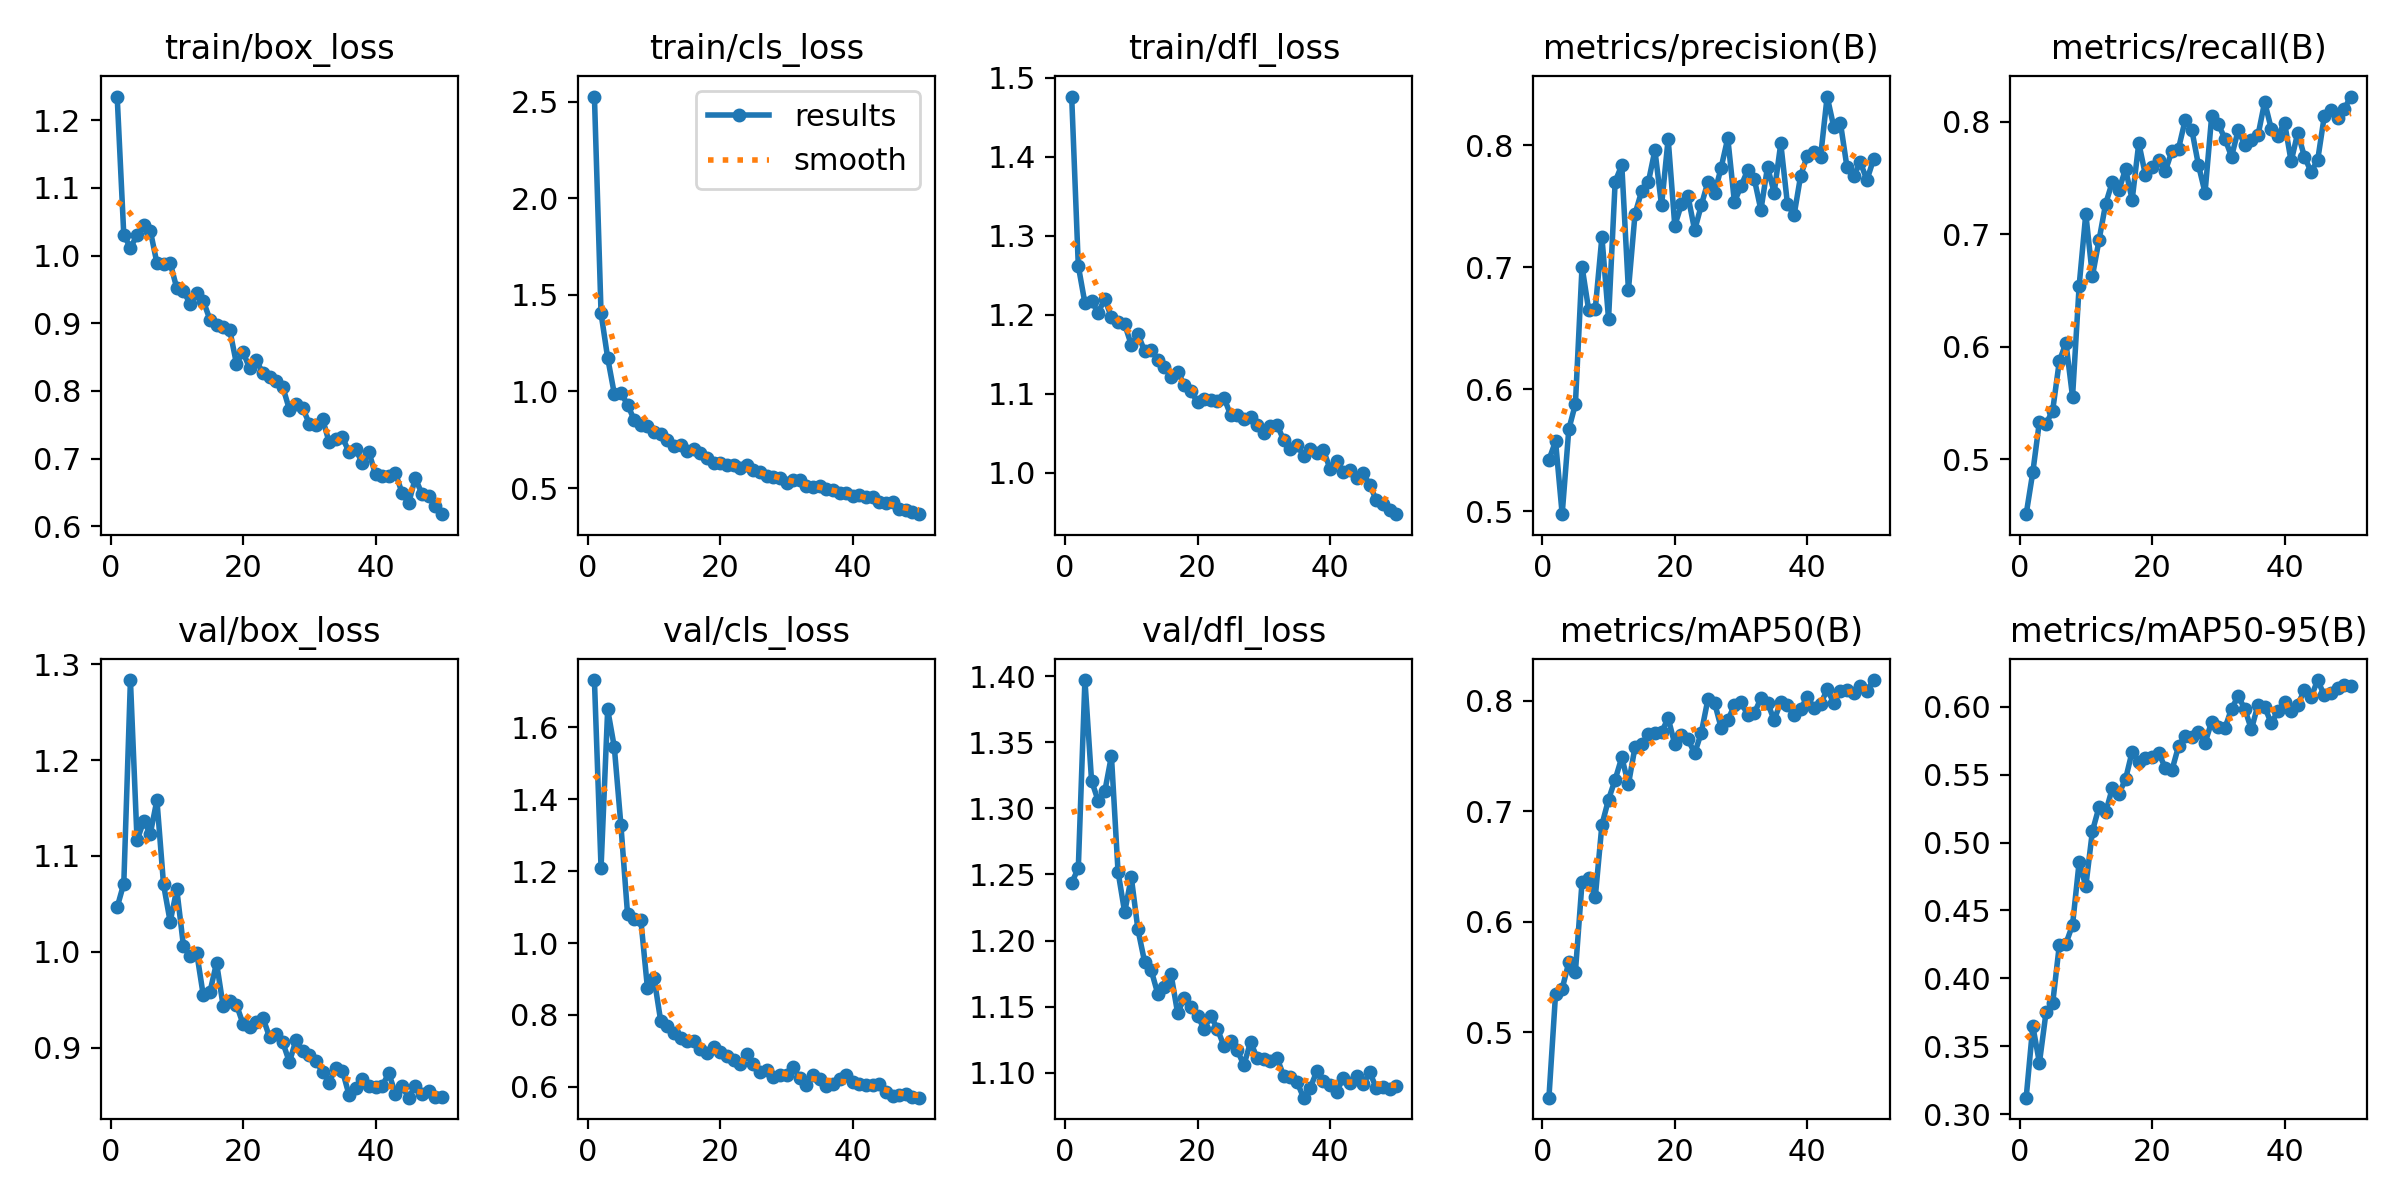

Showing: confusion_matrix.png


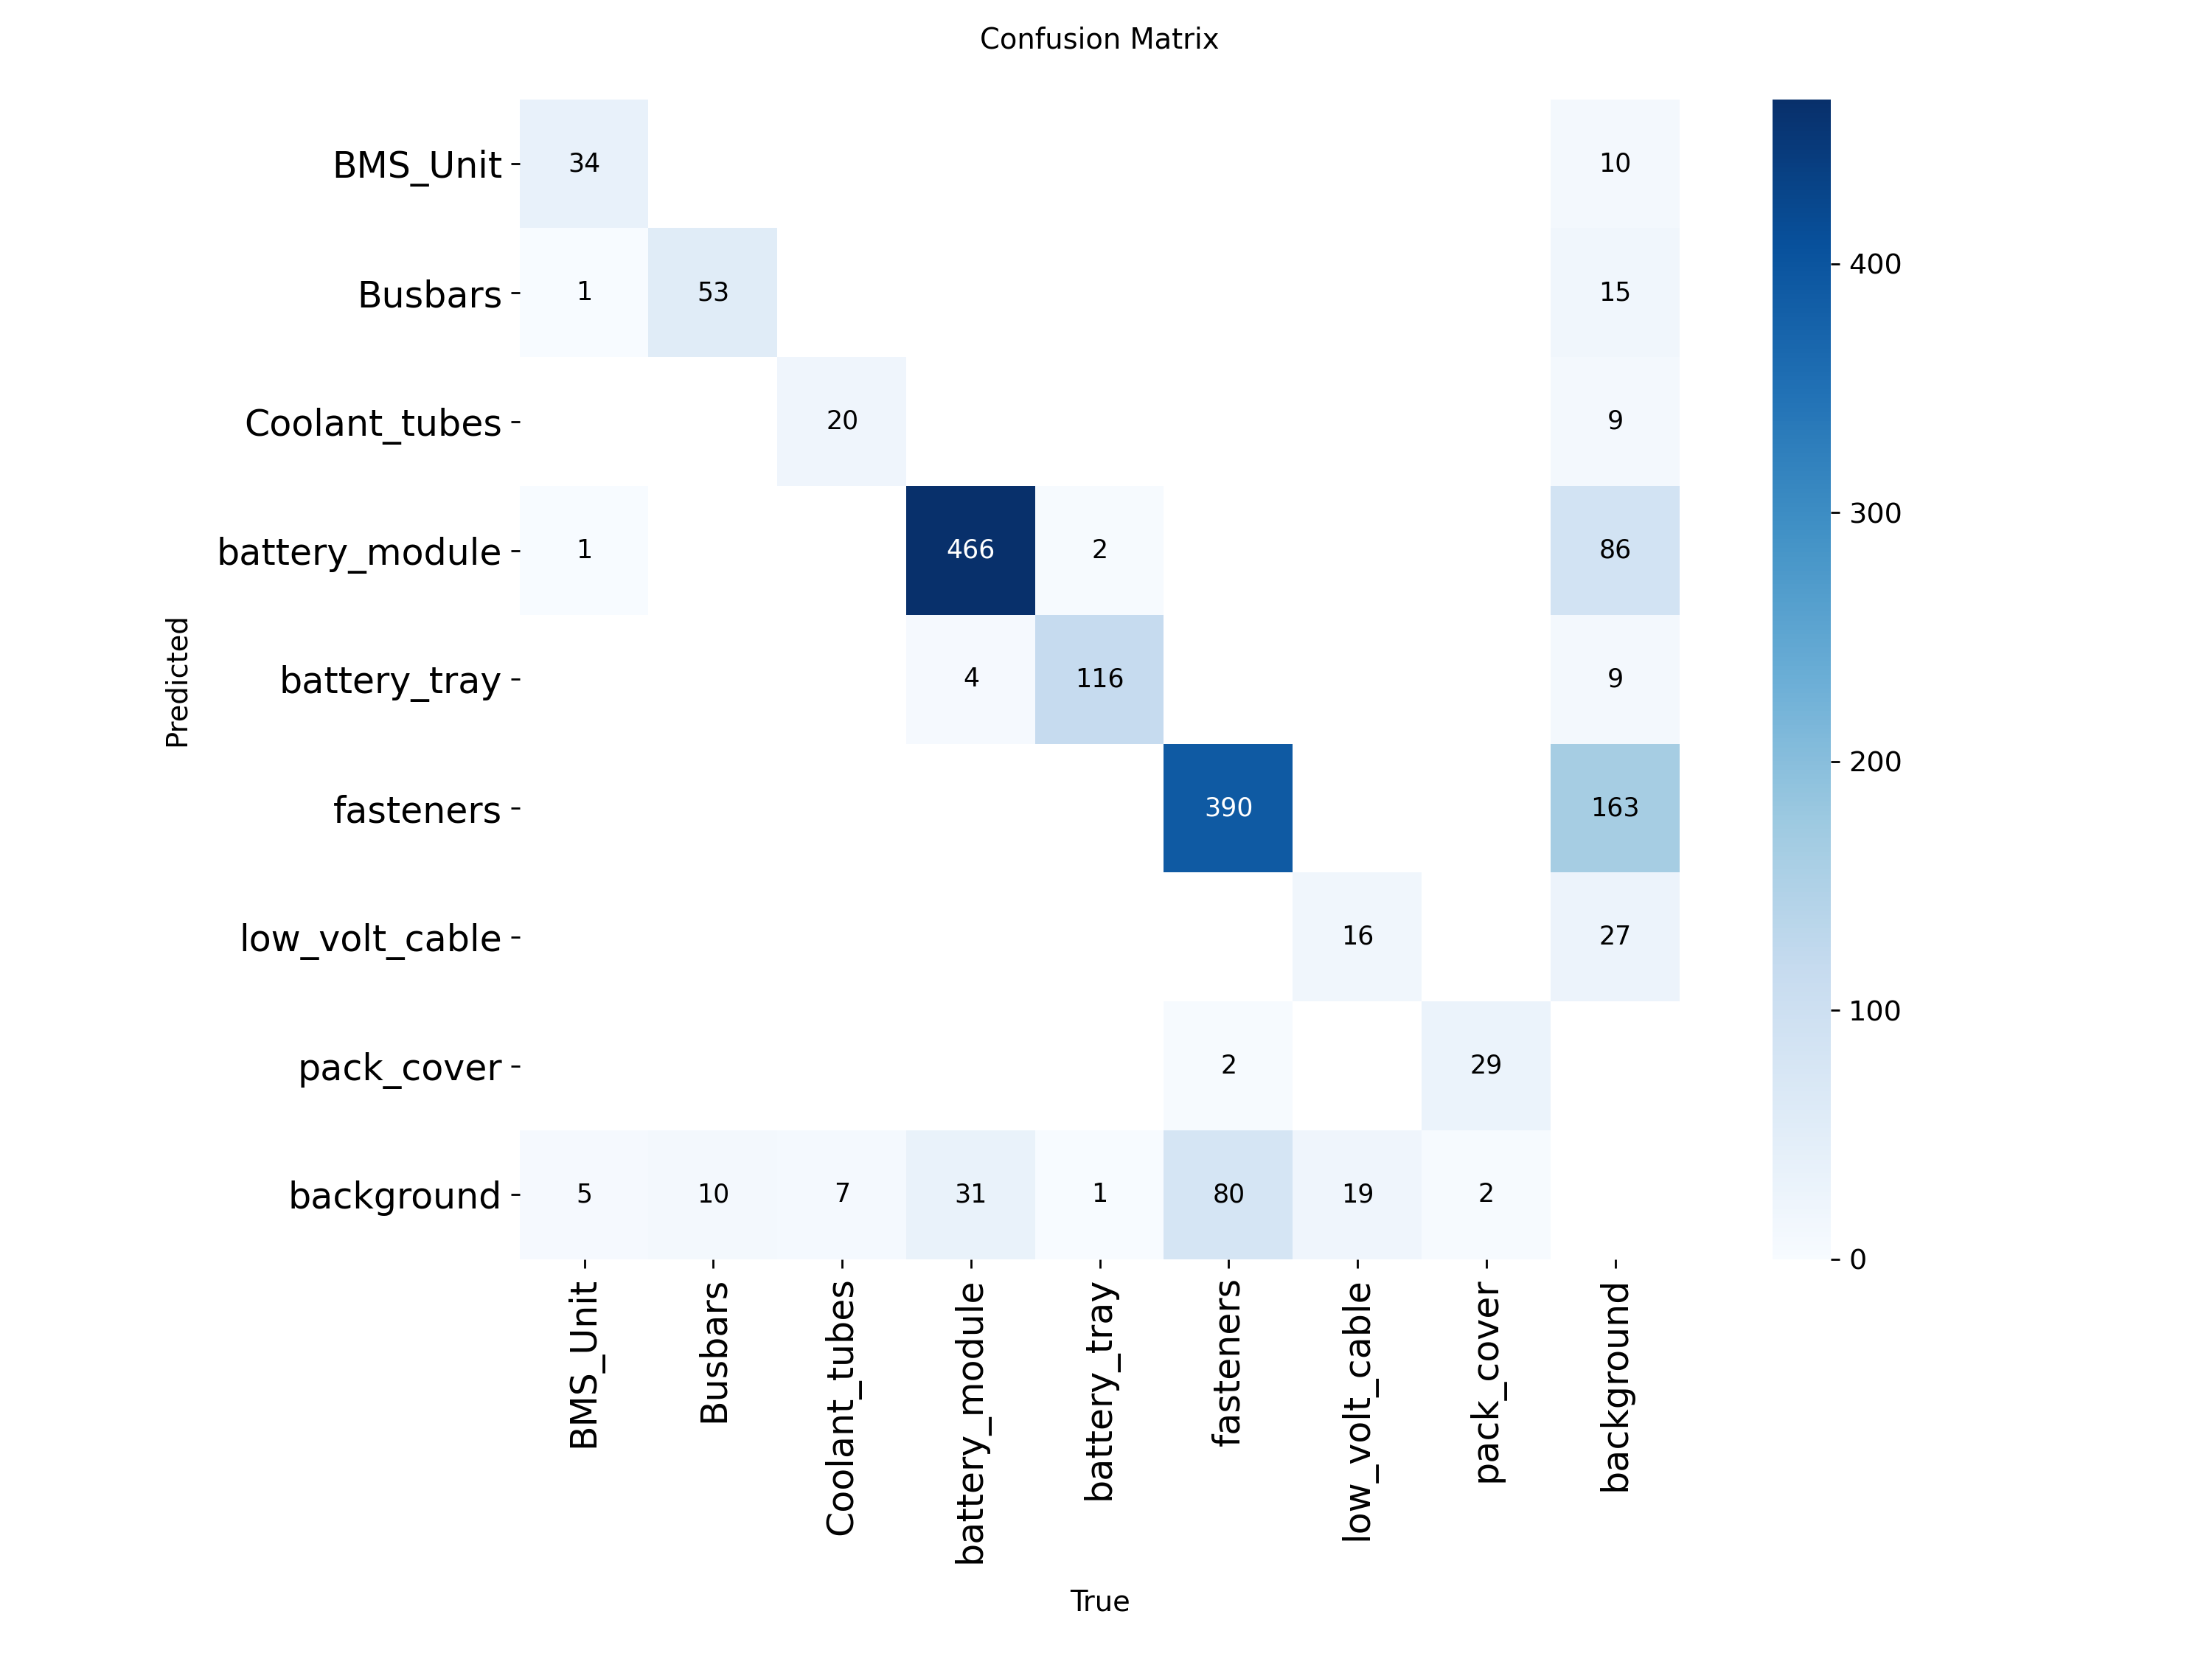

Showing: confusion_matrix_normalized.png


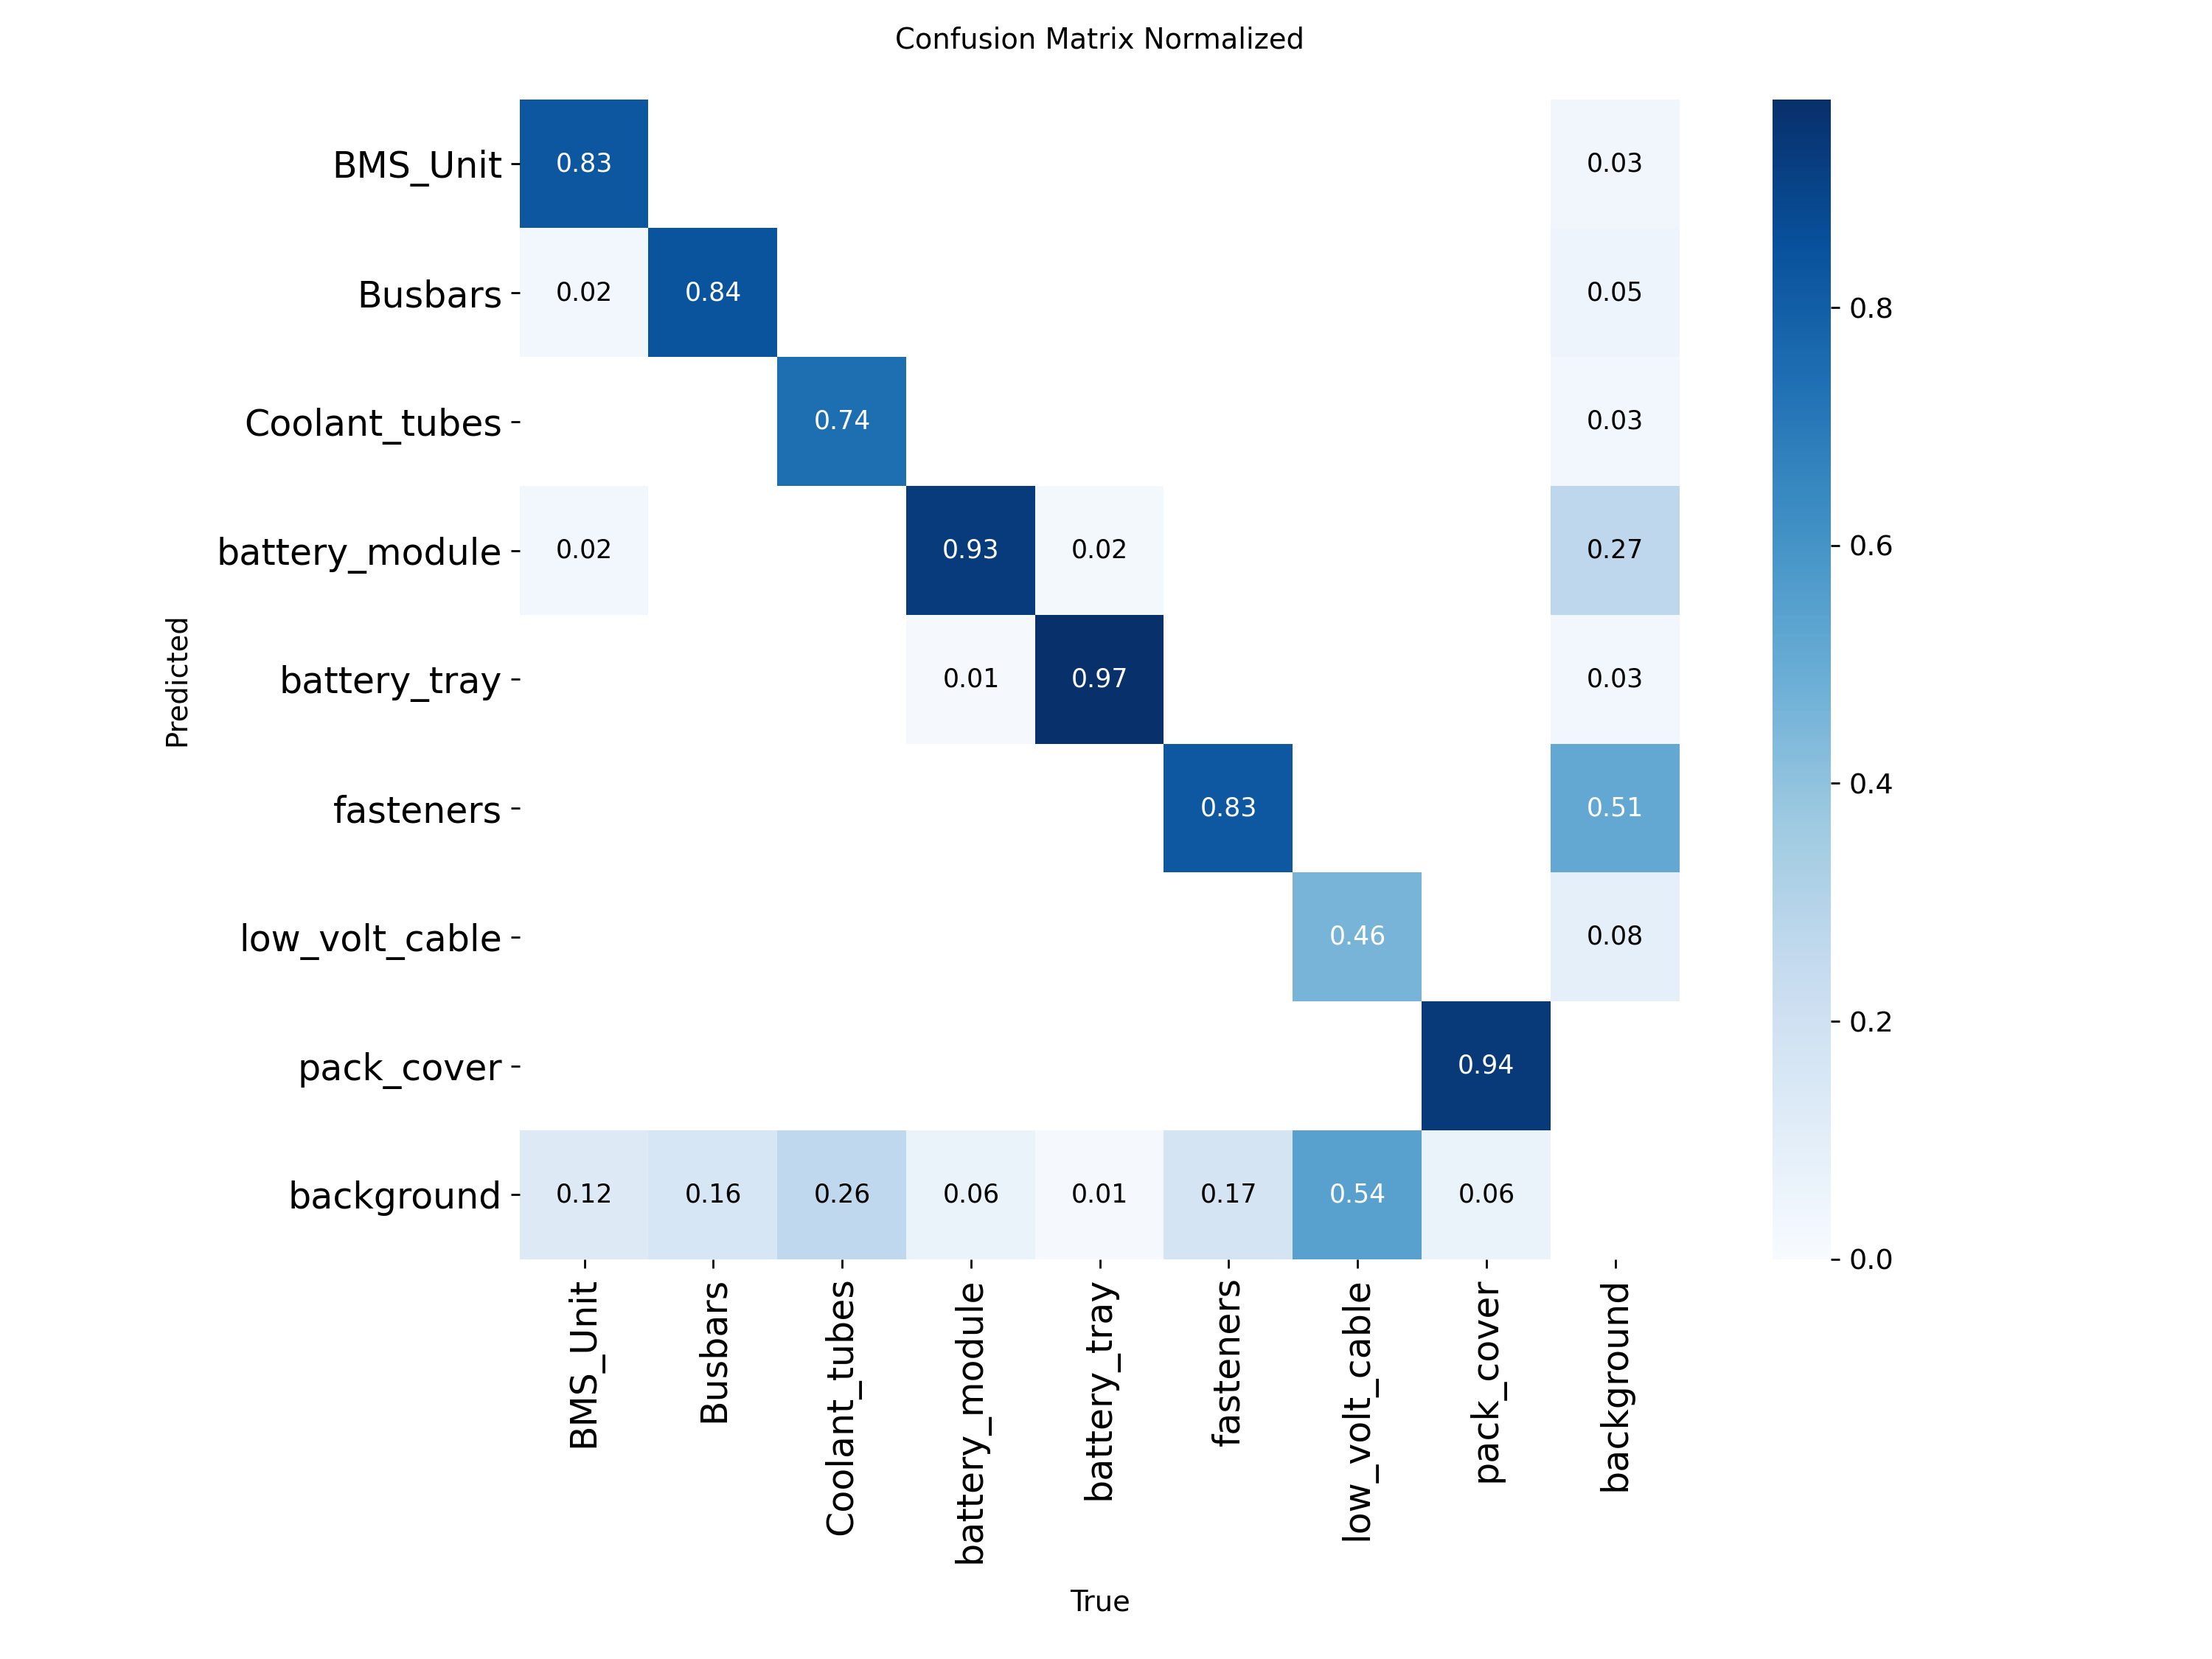

Showing: BoxPR_curve.png


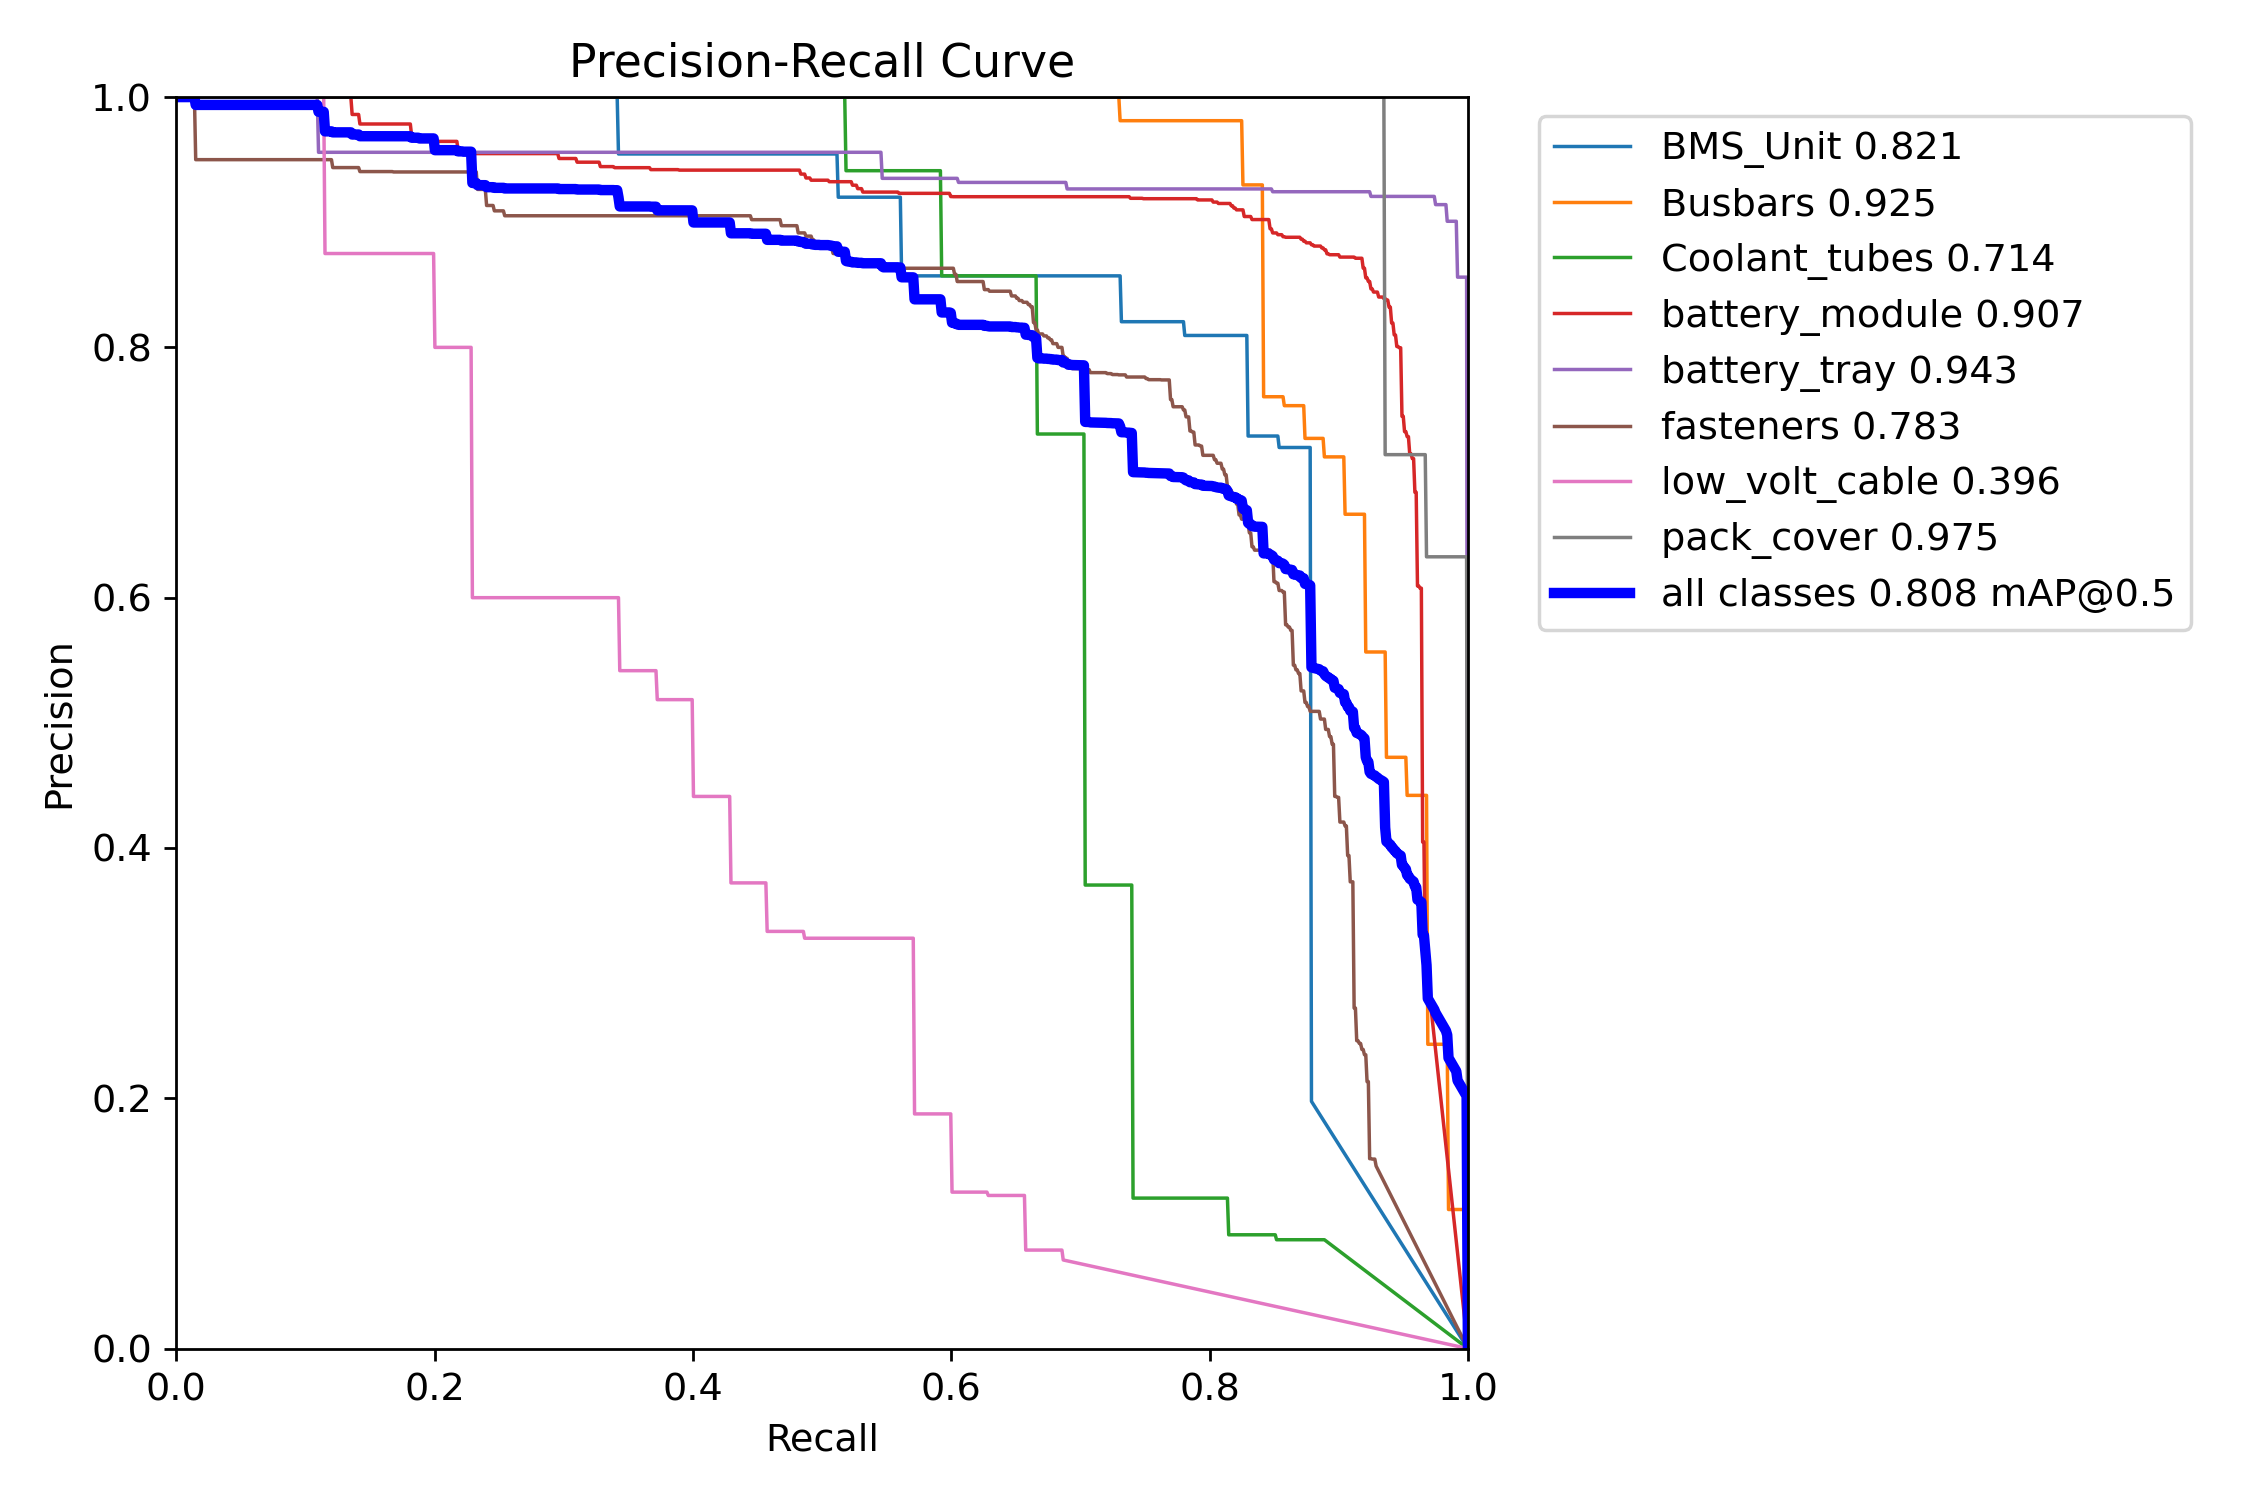

Showing: BoxF1_curve.png


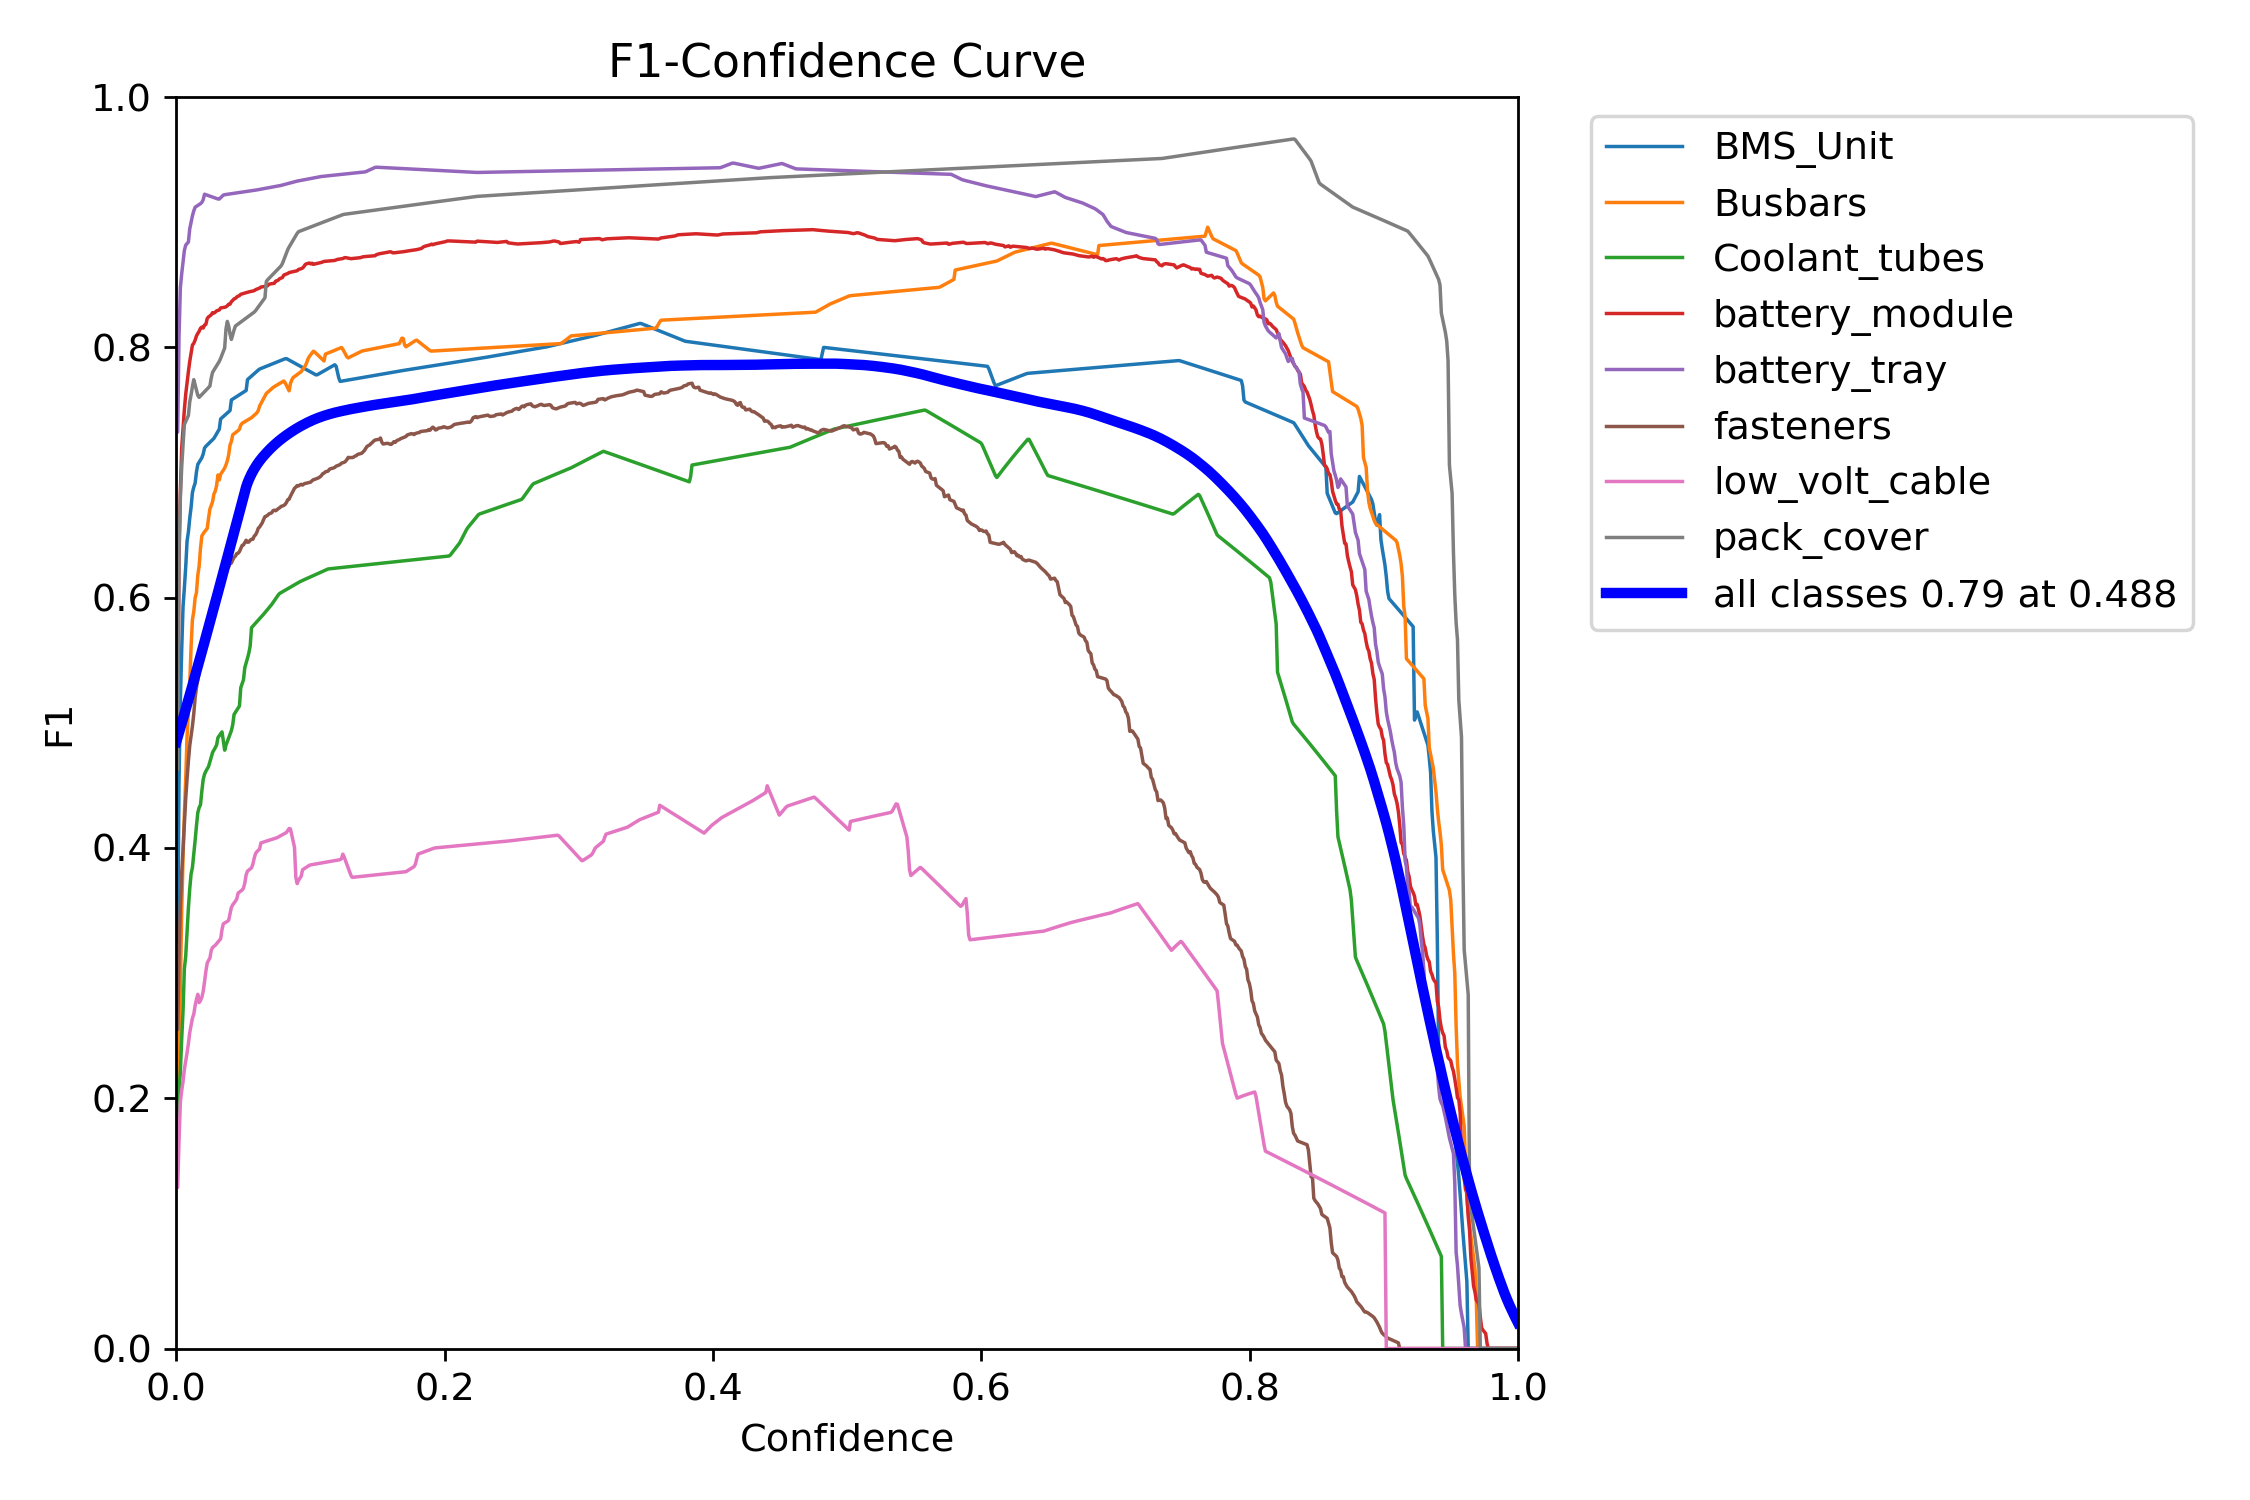

Showing: BoxP_curve.png


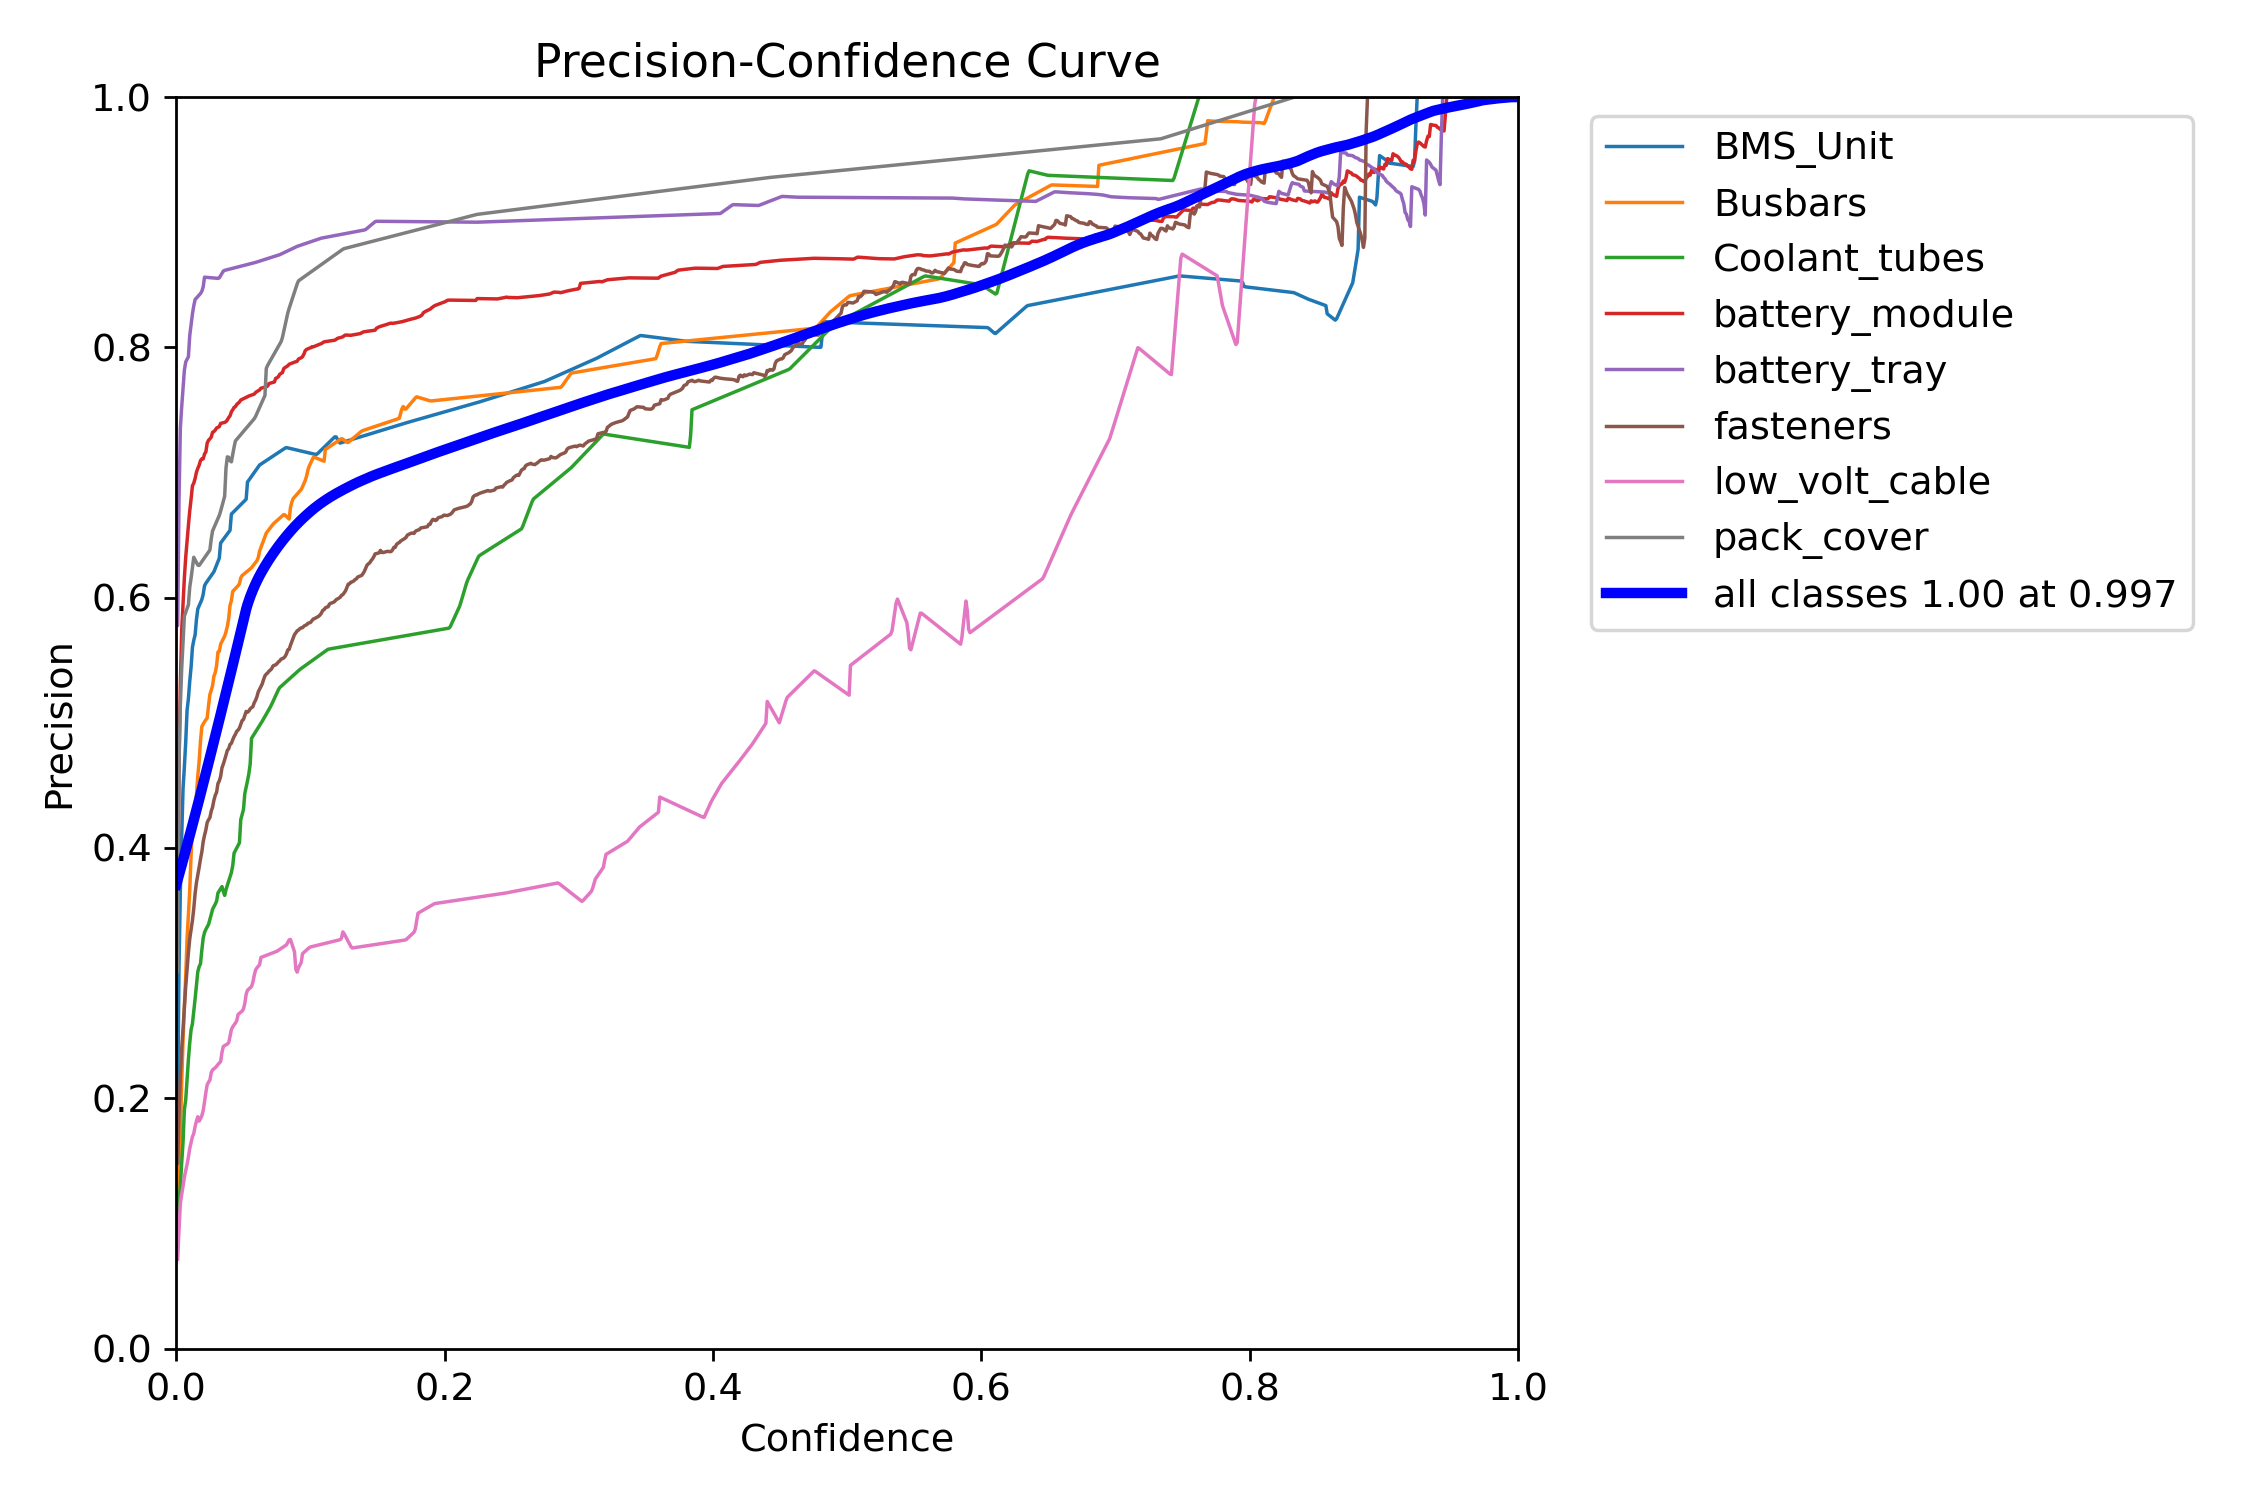

Showing: BoxR_curve.png


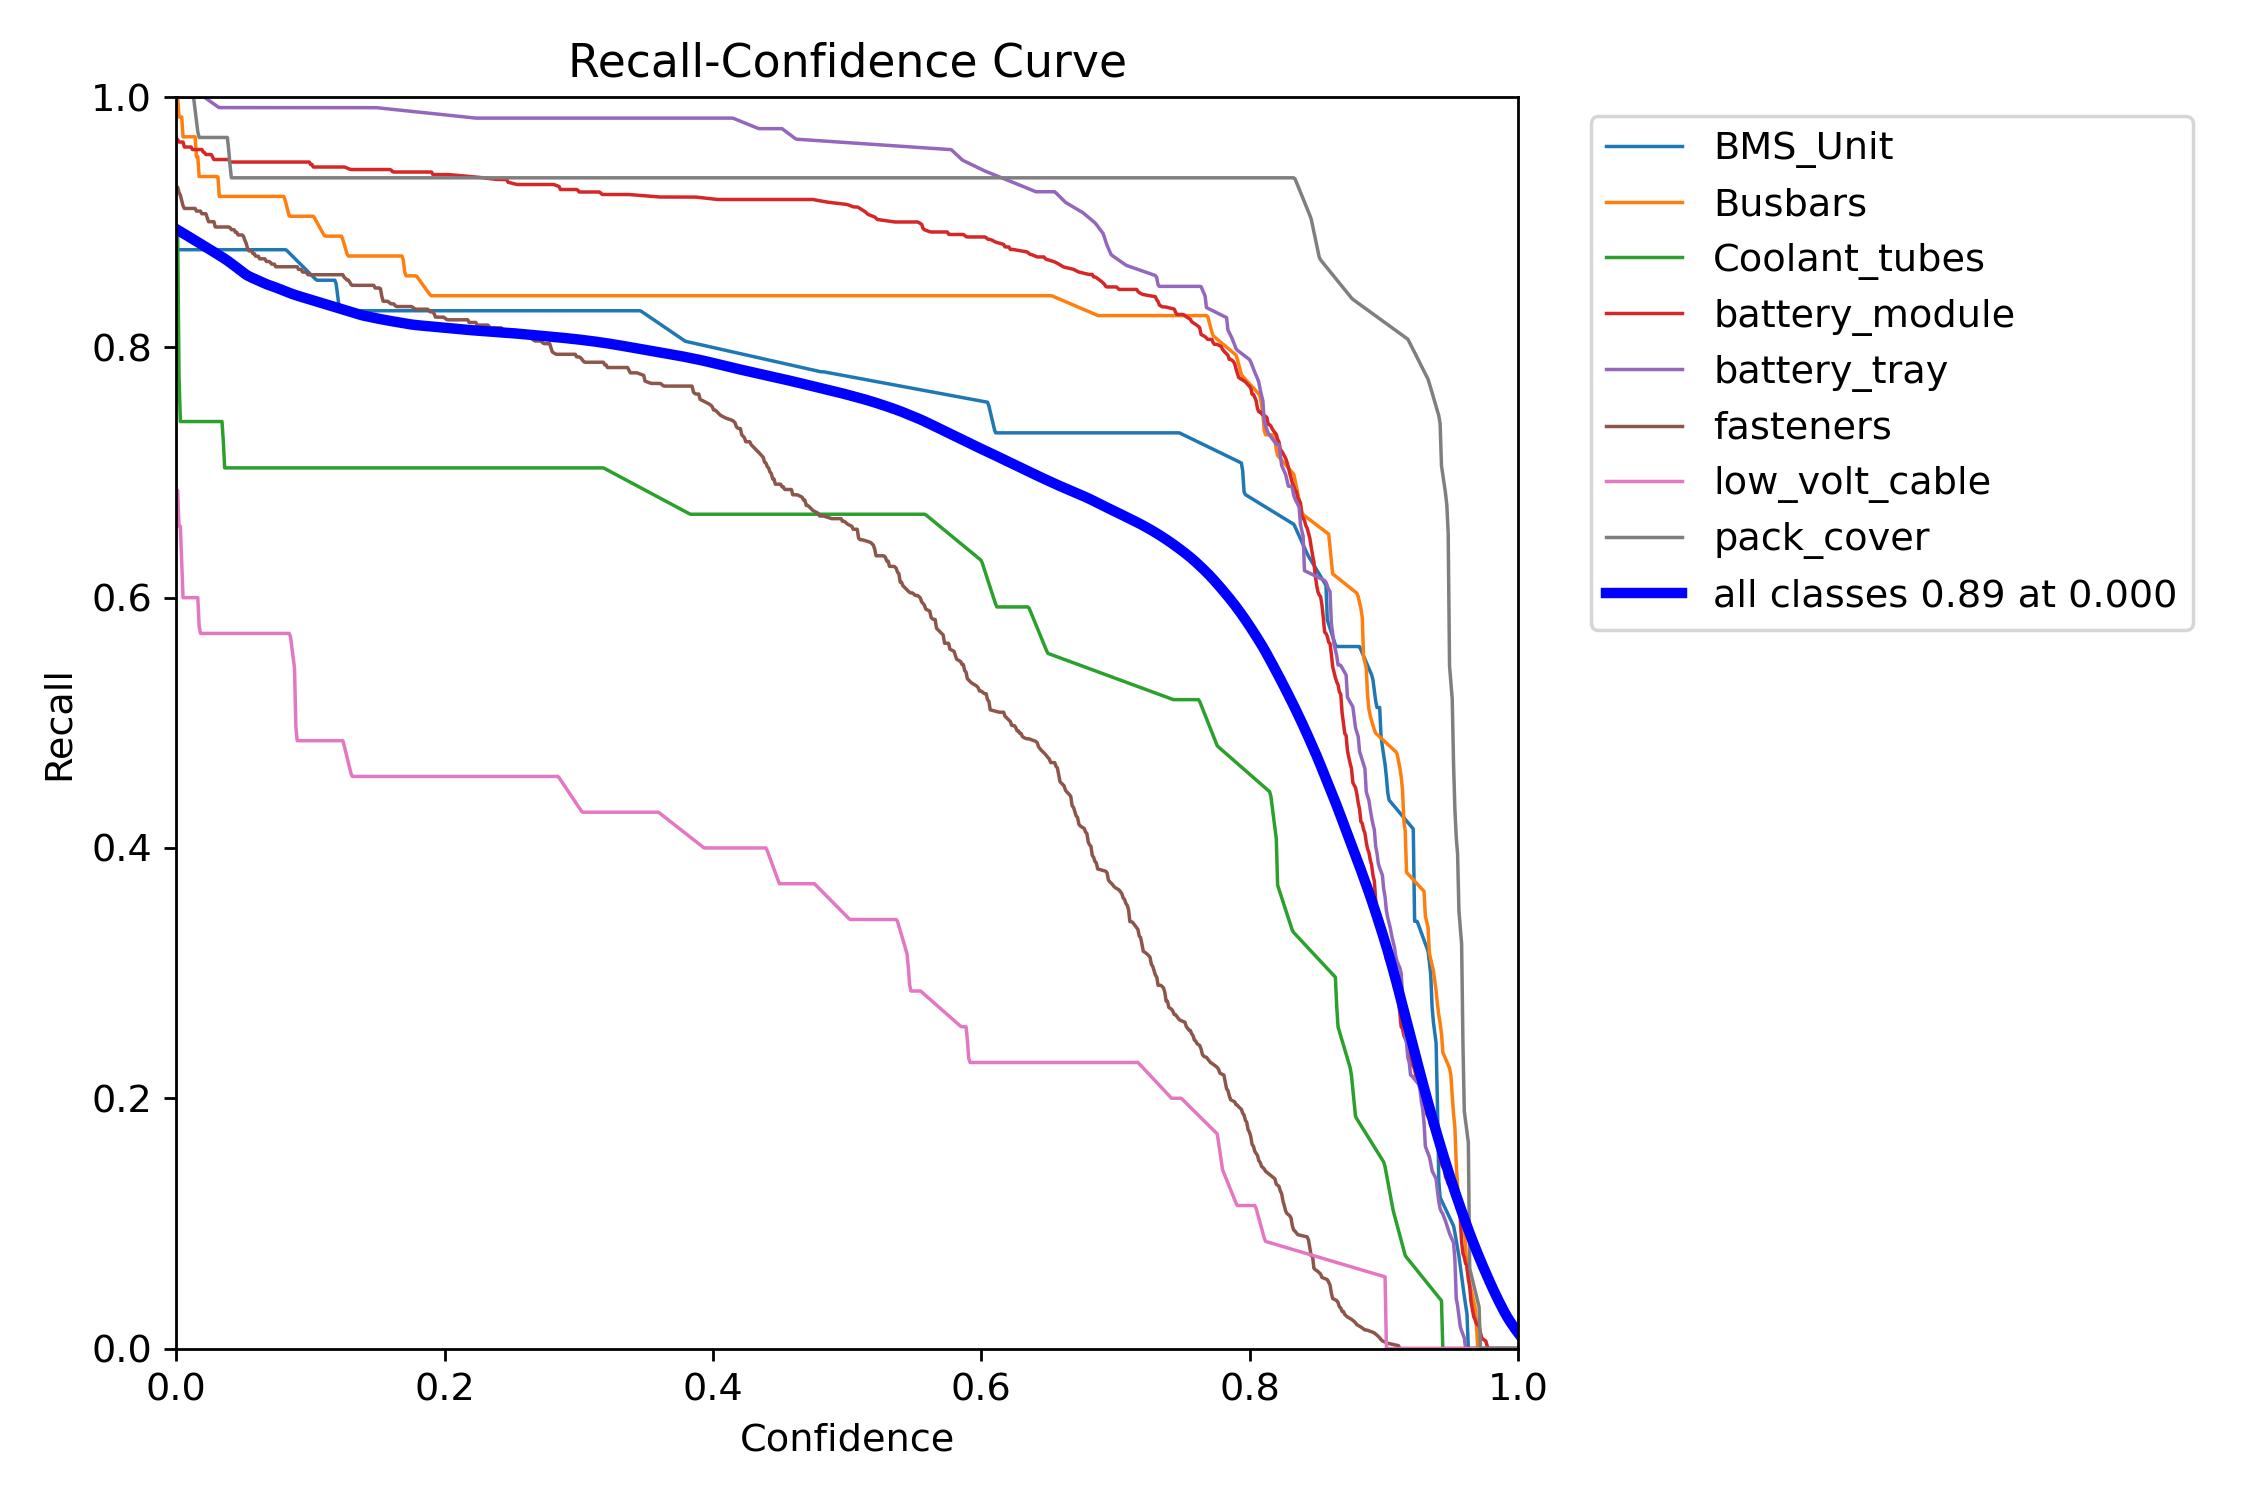

In [13]:
# VISUALISATION 

import os, glob
from IPython.display import Image, display

save_dir = None
try:
    save_dir = str(y_siou_base.trainer.save_dir)
except Exception:
    save_dir = os.path.join(PROJECT_DIR, run_siou_base)

print("Run save_dir:", save_dir)
assert os.path.isdir(save_dir), f"Run directory not found: {save_dir}"

# Lists all PNGs produced by training/val
pngs = sorted(glob.glob(os.path.join(save_dir, "*.png")))
print(f"Found {len(pngs)} PNGs:")
for p in pngs:
    print(" -", os.path.basename(p))

# Displaying key plots 
preferred = [
    "results.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "BoxPR_curve.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
    "PR_curve.png",
    "F1_curve.png",
    "P_curve.png",
    "R_curve.png",
]

print("\nDISPLAYING KEY PLOTS")
for fname in preferred:
    fpath = os.path.join(save_dir, fname)
    if os.path.exists(fpath):
        print("Showing:", fname)
        display(Image(filename=fpath))


need_any = any(not os.path.exists(os.path.join(save_dir, f)) for f in ["confusion_matrix.png", "BoxPR_curve.png"])
if need_any:
    print("\nSome plots missing--> running explicit validation to generate them")
    y_siou_base.val(
        data=DATA_YAML,
        imgsz=IMGSZ,
        device=DEVICE,
        plots=True,
        verbose=True,
        project=PROJECT_DIR,
        name=run_siou_base + "_val"
    )

    val_dir = os.path.join(PROJECT_DIR, run_siou_base + "_val")
    print("Expected val_dir:", val_dir)

    if os.path.isdir(val_dir):
        val_pngs = sorted(glob.glob(os.path.join(val_dir, "*.png")))
        print(f"Found {len(val_pngs)} PNGs in val dir:")
        for p in val_pngs:
            print(" -", os.path.basename(p))
        for fname in preferred:
            fpath = os.path.join(val_dir, fname)
            if os.path.exists(fpath):
                print("Showing (val):", fname)
                display(Image(filename=fpath))
    else:
        print("Val dir not found. Ultralytics may have saved it under runs/detect/val*.")

In [14]:
# CUSTOM MODULES (BICUBIC UPSAMPLE ONLY)


class BicubicUpsample(nn.Module):
    """
    Bicubic interpolation wrapper.
    """
    def __init__(self, scale=2):
        super().__init__()
        self.scale = scale
        self.upsample = nn.Upsample(scale_factor=scale, mode="bicubic", align_corners=False)

    def forward(self, x):
        return self.upsample(x)


def _clone_ultra_meta(src: nn.Module, dst: nn.Module) -> nn.Module:
    """
    Ultralytics builds a dynamic compute graph using module attributes like `f` and `i`.
    If we replace nn.Upsample without copying these, forward() can crash.
    """
    for k in ("f", "i", "type", "np", "receptive_field", "scale"):
        if hasattr(src, k):
            try:
                setattr(dst, k, getattr(src, k))
            except Exception:
                pass
    return dst


def replace_upsamplers(root: nn.Module, kind="bicubic"):
    """
    Replace nn.Upsample layers in YOLO with bicubic, preserving Ultralytics metadata.
    """
    replaced = 0
    for name, child in list(root.named_children()):

        # recurse first
        new_child, rep = replace_upsamplers(child, kind=kind)
        if rep:
            setattr(root, name, new_child)
            replaced += rep

        # replace upsample layers
        if isinstance(child, nn.Upsample):
            scale = getattr(child, "scale_factor", 2)

            if kind == "bicubic":
                new_mod = BicubicUpsample(scale=scale)
            else:
                new_mod = nn.Upsample(scale_factor=scale, mode="nearest")

            # preserve Ultralytics graph metadata
            new_mod = _clone_ultra_meta(child, new_mod)

            setattr(root, name, new_mod)
            replaced += 1

    return root, replaced


In [15]:
# BASELINE TRAINING
logger.info("\nTRAIN BASELINE YOLOv9m")

y_base = YOLO("yolov9m.pt")
run_base = f"baseline_yolov9m_1045_{int(time.time())}"

results_base = y_base.train(
    data=DATA_YAML,
    imgsz=IMGSZ,
    epochs=BASE_EPOCHS,
    patience=BASE_PATIENCE,
    batch=BATCH,
    workers=WORKERS,
    device=DEVICE,
    optimizer="SGD",
    lr0=0.01,
    lrf=0.01,
    warmup_epochs=2,
    hsv_h=0.015, hsv_s=0.5, hsv_v=0.5,
    degrees=3.0, translate=0.05, scale=0.4, shear=1.0,
    cache=False,
    close_mosaic=5,
    seed=42,
    project=PROJECT_DIR,
    name=run_base,
    save=True,
    plots=True,
    verbose=True
)

best_base = os.path.join(PROJECT_DIR, run_base, "weights", "best.pt")
logger.info(f"Baseline best weights: {best_base}")

2026-01-26 05:07:47,455 | INFO | 
TRAIN BASELINE YOLOv9m


New https://pypi.org/project/ultralytics/8.4.7 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.6 🚀 Python-3.10.18 torch-1.12.1+cu113 CUDA:0 (NVIDIA RTX A6000, 48539MiB)
WARNING ⚠️ Upgrade to torch>=2.0.0 for deterministic training.
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=5, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/240388203/ev-disassembly/datasets/ev_battery_1045/data.yaml, degrees=3.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.5, hsv_v=0.5, imgsz=768, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=t

/users/2/240388203/anaconda3/envs/evdisassembly/lib/python3.10/site-packages/ultralytics/nn/modules/head.py:236: UserWarning: __floordiv__ is deprecated, and its behavior will change in a future version of pytorch. It currently rounds toward 0 (like the 'trunc' function NOT 'floor'). This results in incorrect rounding for negative values. To keep the current behavior, use torch.div(a, b, rounding_mode='trunc'), or for actual floor division, use torch.div(a, b, rounding_mode='floor').
  idx = ori_index[torch.arange(batch_size)[..., None], index // nc]  # original index


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 595.6±476.8 MB/s, size: 204.4 KB)
val: Scanning /home/240388203/ev-disassembly/datasets/ev_battery_1045/valid/labels.cache... 209 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 209/209 6.8Mit/s 0.0s
Plotting labels to /home/240388203/ev-disassembly/runs_yolov9/baseline_yolov9m_1045_1769404067/labels.jpg... 
optimizer: SGD(lr=0.01, momentum=0.937) with parameter groups 149 weight(decay=0.0), 156 weight(decay=0.0005), 155 bias(decay=0.0)
Image sizes 768 train, 768 val
Using 8 dataloader workers
Logging results to /home/240388203/ev-disassembly/runs_yolov9/baseline_yolov9m_1045_1769404067
Starting training for 50 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/50      12.1G      1.343      2.592      1.559        205        768: 100% ━━━━━━━━━━━━ 46/46 2.9it/s 15.9s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 6.1it

2026-01-26 05:21:11,548 | INFO | Baseline best weights: /home/240388203/ev-disassembly/runs_yolov9/baseline_yolov9m_1045_1769404067/weights/best.pt


In [16]:
#  CUSTOM MODEL BUILD

logger.info("\nBUILD CUSTOM YOLOv9m (Bicubic Upsample)")

UPS_KIND = "bicubic"  # bicubic for small-object preservation

y_custom = YOLO("yolov9m.pt")
mdl = y_custom.model

mdl, n_up = replace_upsamplers(mdl, kind=UPS_KIND)
logger.info(f"Upsamplers replaced: {n_up} ({UPS_KIND})")

y_custom.model = mdl

2026-01-26 05:21:11,553 | INFO | 
BUILD CUSTOM YOLOv9m (Bicubic Upsample)
2026-01-26 05:21:11,719 | INFO | Upsamplers replaced: 2 (bicubic)


In [18]:
#  CUSTOM TRAINING

logger.info("\nTRAIN CUSTOM MODEL")

run_custom = f"custom_{UPS_KIND}_1045_{int(time.time())}"

results_custom = y_custom.train(
    data=DATA_YAML,
    imgsz=IMGSZ,
    epochs=CUSTOM_EPOCHS,
    patience=CUSTOM_PATIENCE,
    batch=BATCH,
    workers=WORKERS,
    device=DEVICE,
    optimizer="AdamW",
    lr0=0.003,
    lrf=0.01,
    warmup_epochs=3,
    hsv_h=0.015, hsv_s=0.5, hsv_v=0.5,
    degrees=5.0, translate=0.05, scale=0.5, shear=2.0,
    rect=False,
    cache=False,
    close_mosaic=5,
    mixup=0.0, cutmix=0.0, erasing=0.05,
    seed=42,
    project=PROJECT_DIR,
    name=run_custom,
    save=True,
    plots=True,
    verbose=True
)

best_custom = os.path.join(PROJECT_DIR, run_custom, "weights", "best.pt")
logger.info(f"Custom best weights: {best_custom}")

2026-01-26 05:56:07,073 | INFO | 
TRAIN CUSTOM MODEL


New https://pypi.org/project/ultralytics/8.4.7 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.6 🚀 Python-3.10.18 torch-1.12.1+cu113 CUDA:0 (NVIDIA RTX A6000, 48539MiB)
WARNING ⚠️ Upgrade to torch>=2.0.0 for deterministic training.
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=5, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/240388203/ev-disassembly/datasets/ev_battery_1045/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.05, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.5, hsv_v=0.5, imgsz=768, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.003, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode

/users/2/240388203/anaconda3/envs/evdisassembly/lib/python3.10/site-packages/ultralytics/nn/modules/head.py:236: UserWarning: __floordiv__ is deprecated, and its behavior will change in a future version of pytorch. It currently rounds toward 0 (like the 'trunc' function NOT 'floor'). This results in incorrect rounding for negative values. To keep the current behavior, use torch.div(a, b, rounding_mode='trunc'), or for actual floor division, use torch.div(a, b, rounding_mode='floor').
  idx = ori_index[torch.arange(batch_size)[..., None], index // nc]  # original index


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 942.0±683.2 MB/s, size: 204.4 KB)
val: Scanning /home/240388203/ev-disassembly/datasets/ev_battery_1045/valid/labels.cache... 209 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 209/209 7.9Mit/s 0.0s
Plotting labels to /home/240388203/ev-disassembly/runs_yolov9/custom_bicubic_1045_1769406967/labels.jpg... 
optimizer: AdamW(lr=0.003, momentum=0.937) with parameter groups 149 weight(decay=0.0), 156 weight(decay=0.0005), 155 bias(decay=0.0)
Image sizes 768 train, 768 val
Using 8 dataloader workers
Logging results to /home/240388203/ev-disassembly/runs_yolov9/custom_bicubic_1045_1769406967
Starting training for 80 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/80      13.1G      1.054     0.8066       1.26        208        768: 100% ━━━━━━━━━━━━ 46/46 2.6it/s 17.6s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 6.7it/

2026-01-26 06:18:04,974 | INFO | Custom best weights: /home/240388203/ev-disassembly/runs_yolov9/custom_bicubic_1045_1769406967/weights/best.pt


In [19]:
# VALIDATION

def _to_float(x):
    try:
        return float(np.array(x).reshape(-1)[0])
    except Exception:
        return float("nan")

# Load best weights
if os.path.exists(best_base):
    y_base_eval = YOLO(best_base)
else:
    y_base_eval = y_base
    logger.warning(f"Baseline best.pt not found: {best_base}. Using in-memory model.")

if os.path.exists(best_custom):
    y_custom_eval = YOLO(best_custom)
else:
    y_custom_eval = y_custom
    logger.warning(f"Custom best.pt not found: {best_custom}. Using in-memory model.")

# RUN VALIDATION 
val_base = y_base_eval.val(data=DATA_YAML, imgsz=IMGSZ, batch=BATCH, device=DEVICE, plots=True, verbose=True)
val_custom = y_custom_eval.val(data=DATA_YAML, imgsz=IMGSZ, batch=BATCH, device=DEVICE, plots=True, verbose=True)

# PRINT METRICS
logger.info(
    f"[BASE]  P={_to_float(val_base.box.p):.3f} "
    f"R={_to_float(val_base.box.r):.3f} "
    f"mAP50={_to_float(val_base.box.map50):.3f} "
    f"mAP50-95={_to_float(val_base.box.map):.3f}"
)

logger.info(
    f"[CUST]  P={_to_float(val_custom.box.p):.3f} "
    f"R={_to_float(val_custom.box.r):.3f} "
    f"mAP50={_to_float(val_custom.box.map50):.3f} "
    f"mAP50-95={_to_float(val_custom.box.map):.3f}"
)


Ultralytics 8.4.6 🚀 Python-3.10.18 torch-1.12.1+cu113 CUDA:0 (NVIDIA RTX A6000, 48539MiB)
YOLOv9m summary (fused): 151 layers, 20,018,776 parameters, 0 gradients, 76.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2355.5±528.2 MB/s, size: 157.6 KB)
val: Scanning /home/240388203/ev-disassembly/datasets/ev_battery_1045/valid/labels.cache... 209 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 209/209 48.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 2.7it/s 5.2s0.1s
                   all        209       1289       0.81      0.784      0.798      0.595
              BMS_Unit         40         41      0.835      0.865      0.866      0.621
               Busbars         31         63       0.81      0.873      0.914      0.726
         Coolant_tubes         20         27      0.701      0.608      0.596       0.37
        battery_module        147        501      0.874      0.912      0.898     

2026-01-26 06:18:22,064 | INFO | [BASE]  P=0.835 R=0.865 mAP50=0.798 mAP50-95=0.595
2026-01-26 06:18:22,066 | INFO | [CUST]  P=0.810 R=0.829 mAP50=0.799 mAP50-95=0.571


In [20]:
#  COMPARISON TABLE FROM results.csv

def read_results_csv(run_dir):
    csv_path = os.path.join(run_dir, "results.csv")
    if not os.path.exists(csv_path):
        return None
    df = pd.read_csv(csv_path)
    last = df.iloc[-1]
    return {
        "Epochs": len(df),
        "Precision": last.get("metrics/precision(B)", np.nan),
        "Recall": last.get("metrics/recall(B)", np.nan),
        "mAP50": last.get("metrics/mAP50(B)", np.nan),
        "mAP50-95": last.get("metrics/mAP50-95(B)", np.nan),
    }

base_dir = os.path.join(PROJECT_DIR, run_base)
cust_dir = os.path.join(PROJECT_DIR, run_custom)

baseline_metrics = read_results_csv(base_dir)
custom_metrics = read_results_csv(cust_dir)

cmp = pd.DataFrame([baseline_metrics, custom_metrics],
                   index=["Baseline YOLOv9m", "Custom Bicubic Upsample"]
)
cmp


,Epochs,Precision,Recall,mAP50,mAP50-95
Baseline YOLOv9m,50,0.75955,0.81139,0.80106,0.59296
Custom Bicubic Upsample,80,0.77728,0.78482,0.77755,0.56995



DISPLAYING BASELINE PLOTS

 Baseline YOLOv9m
Showing: results.png


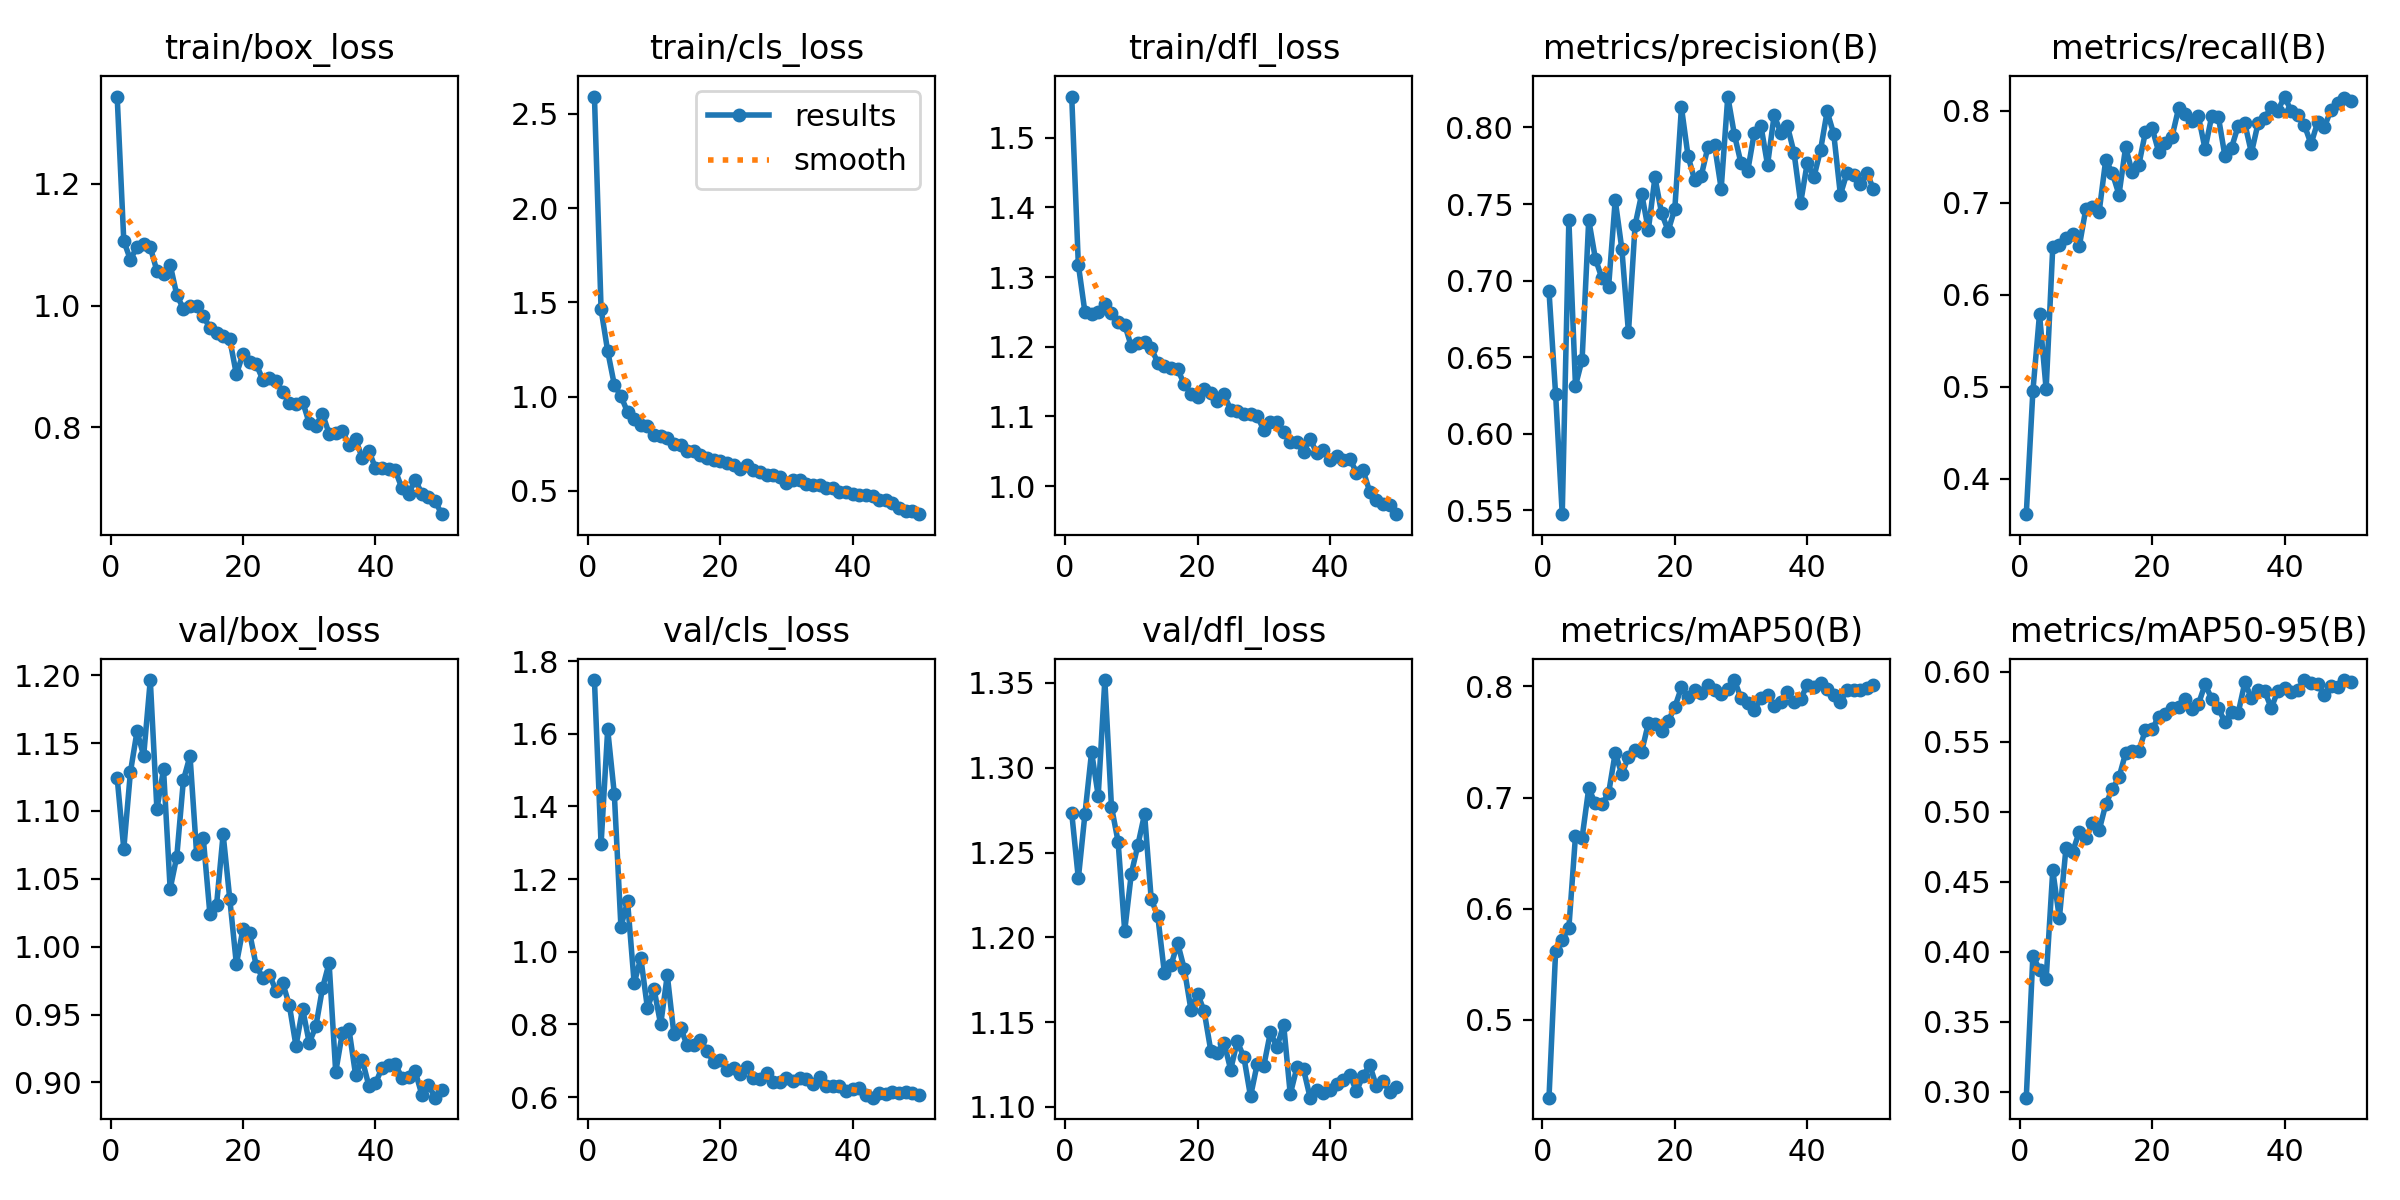

Showing: confusion_matrix.png


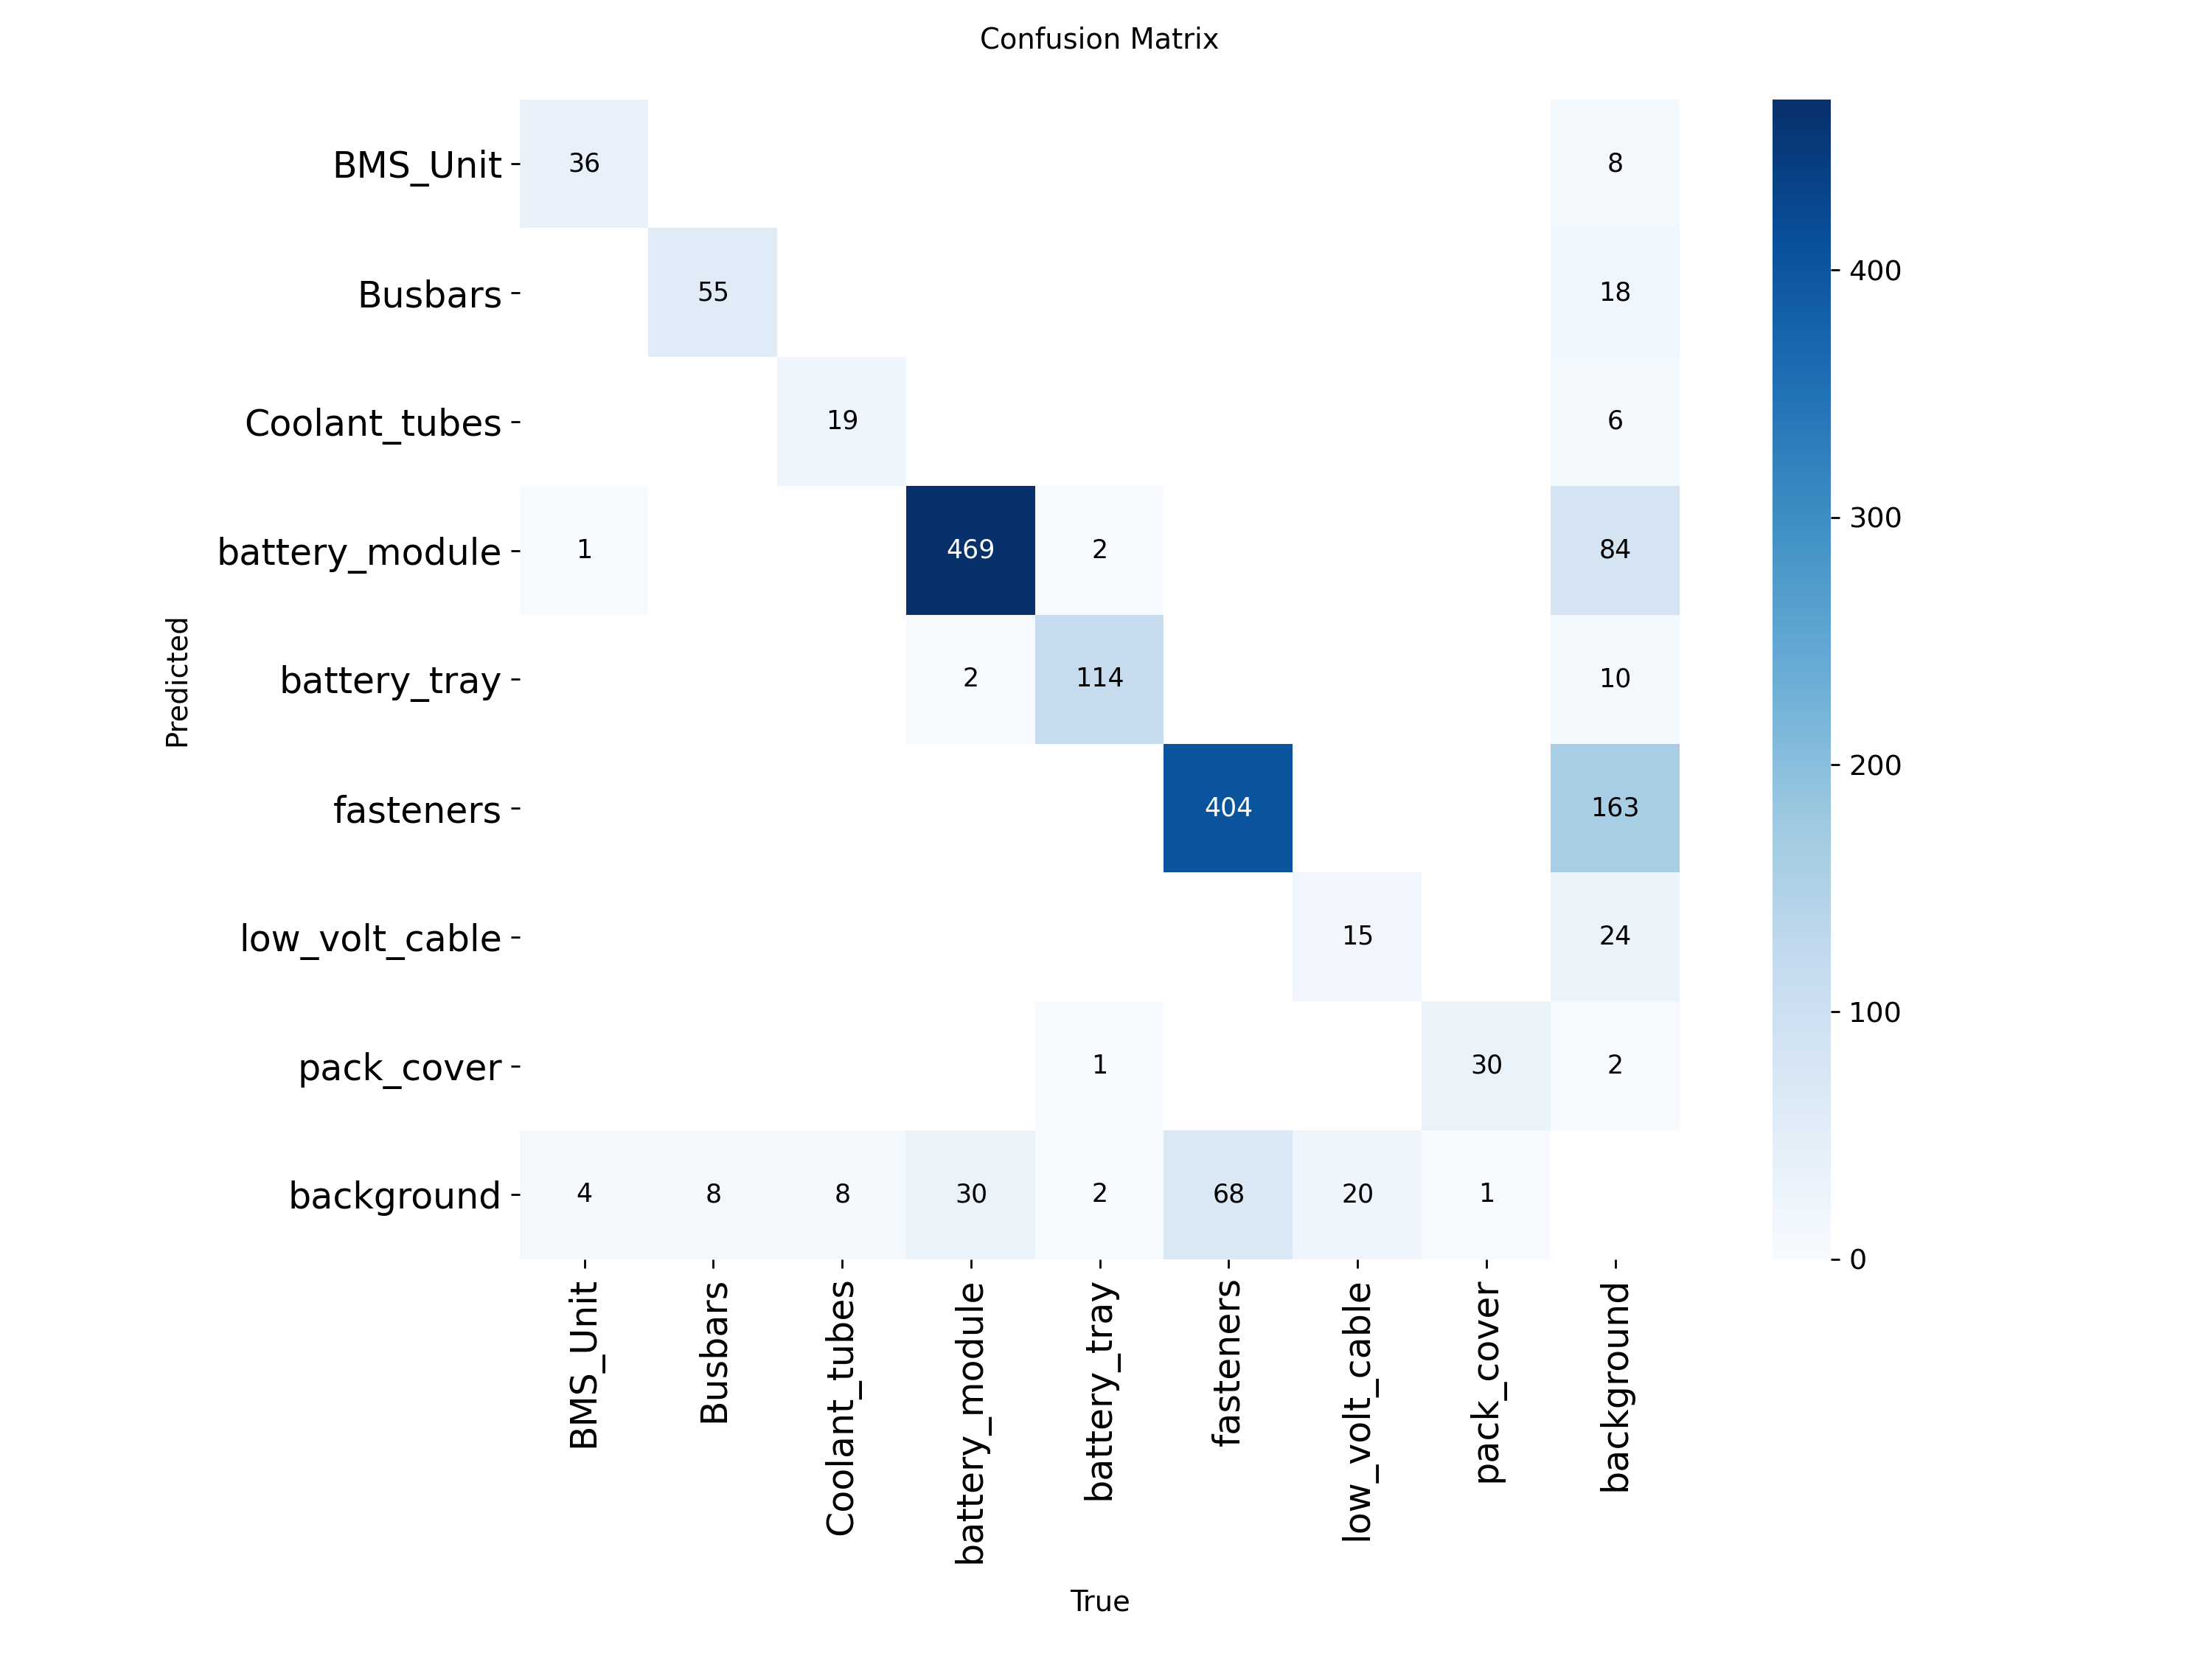

Showing: confusion_matrix_normalized.png


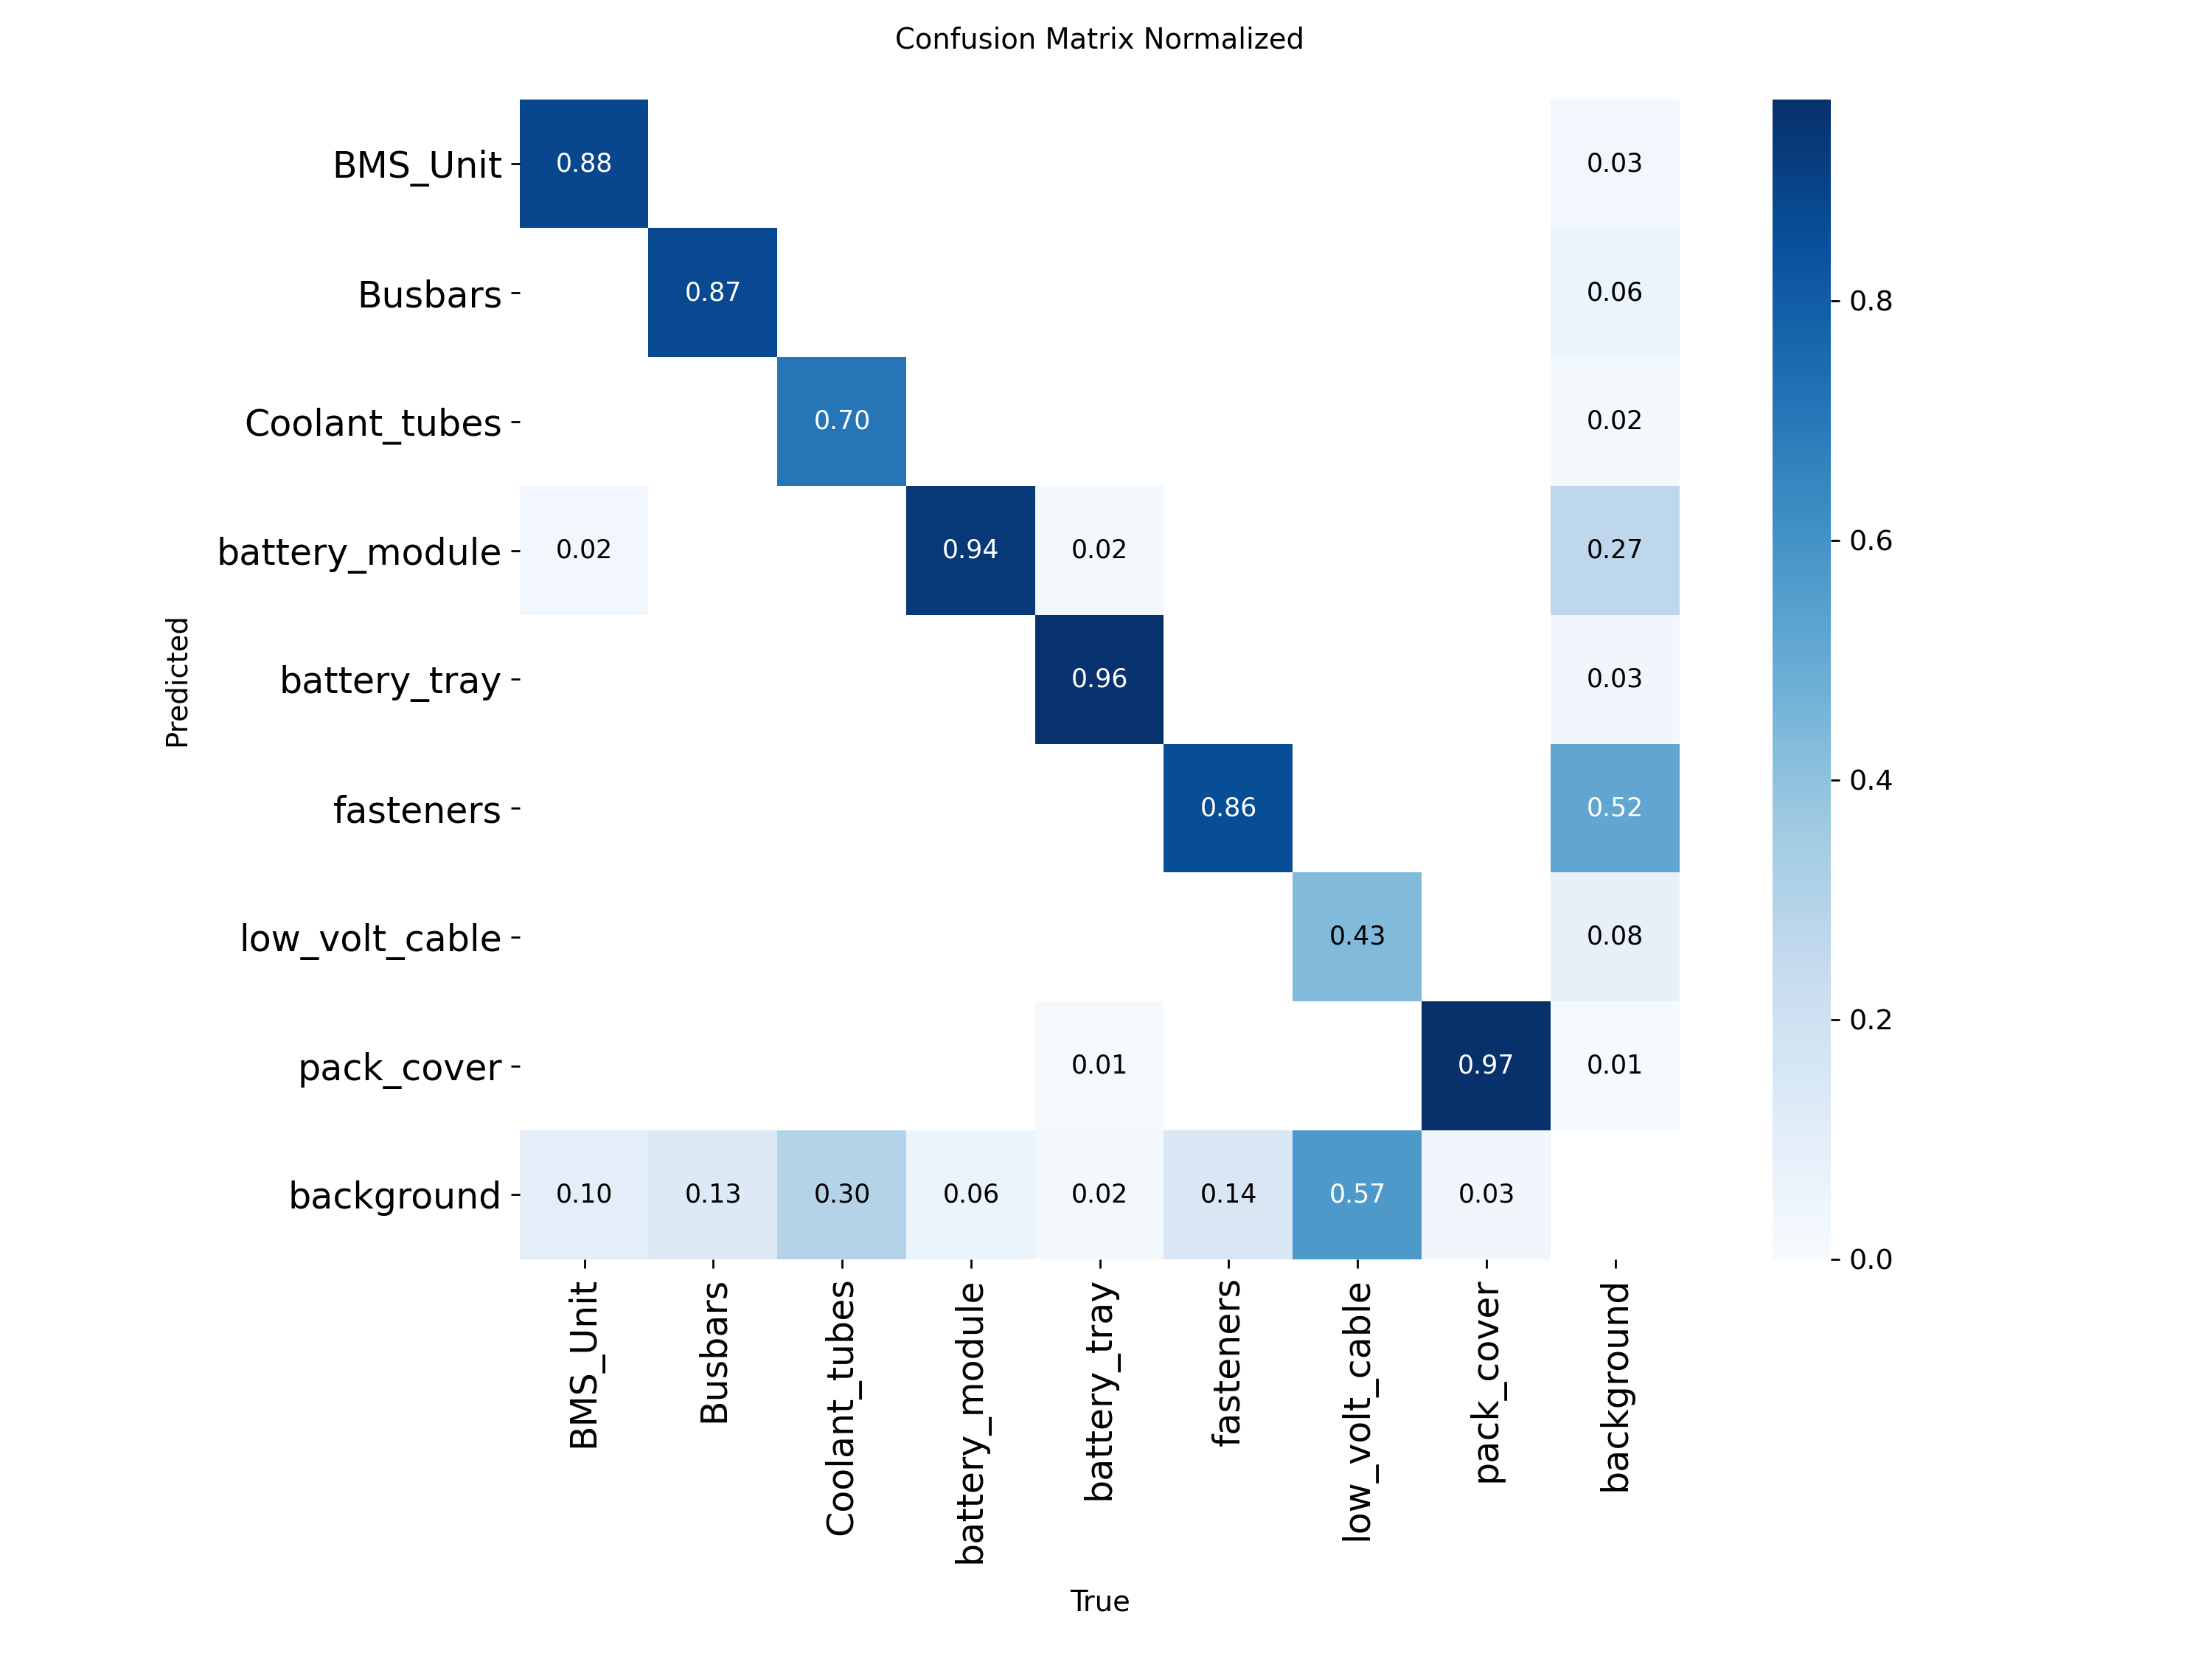

Showing: BoxPR_curve.png


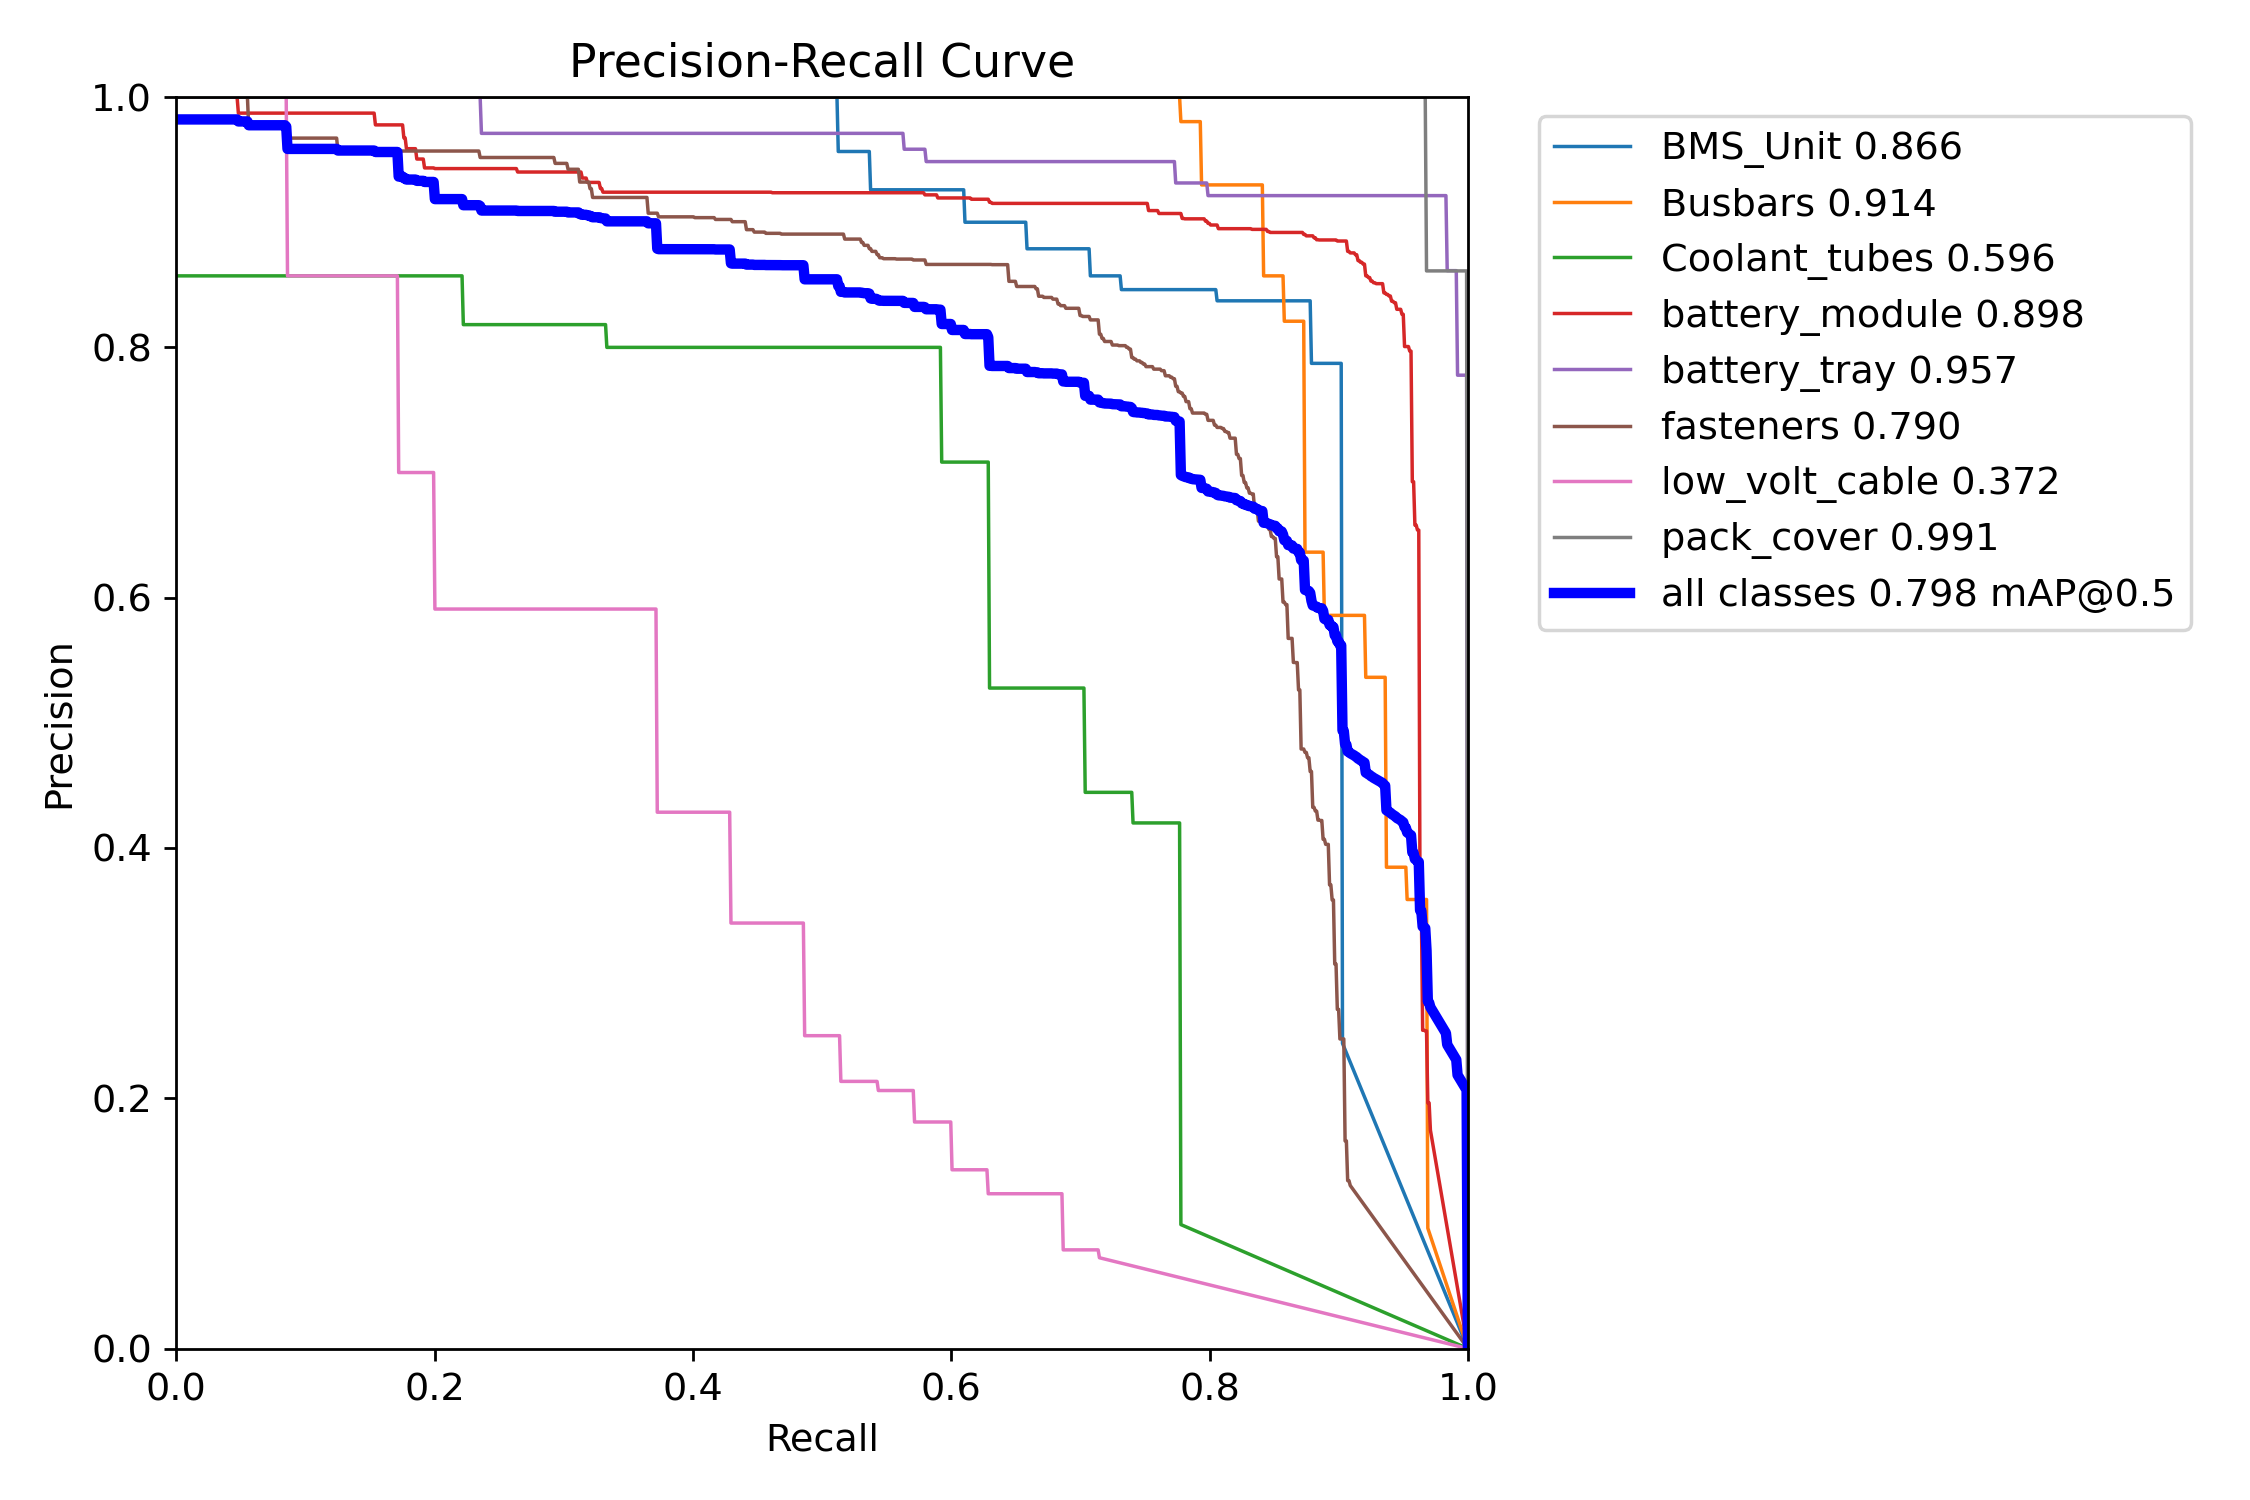

Showing: BoxF1_curve.png


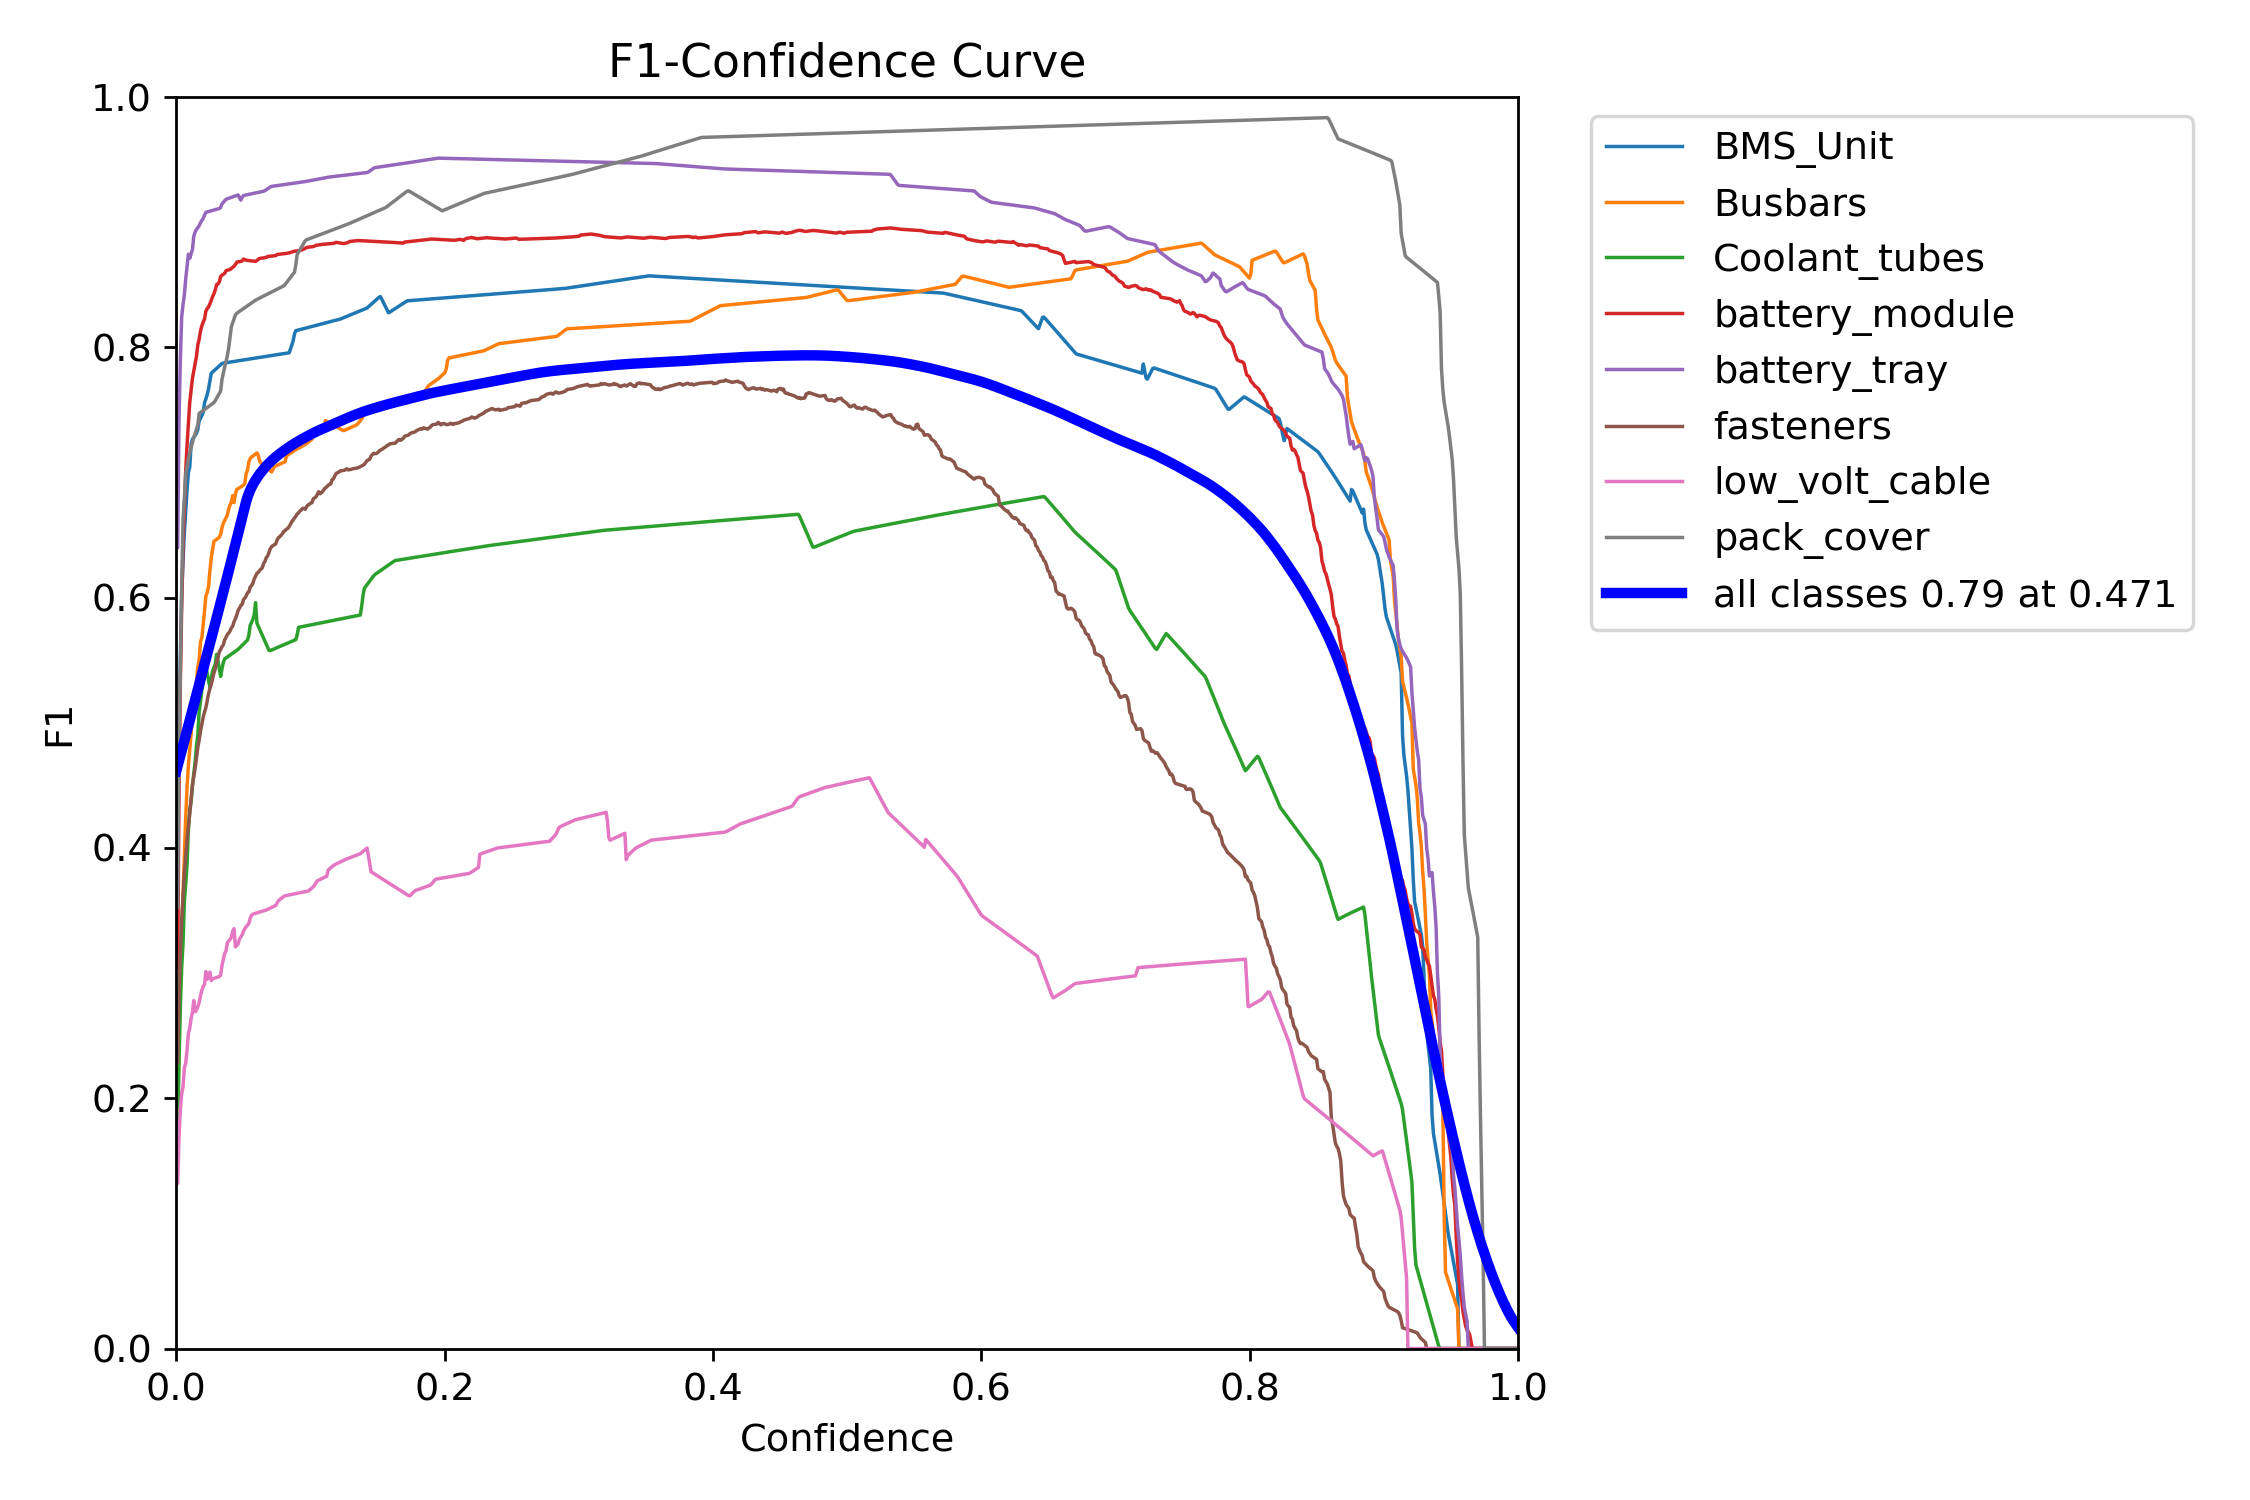

Showing: BoxP_curve.png


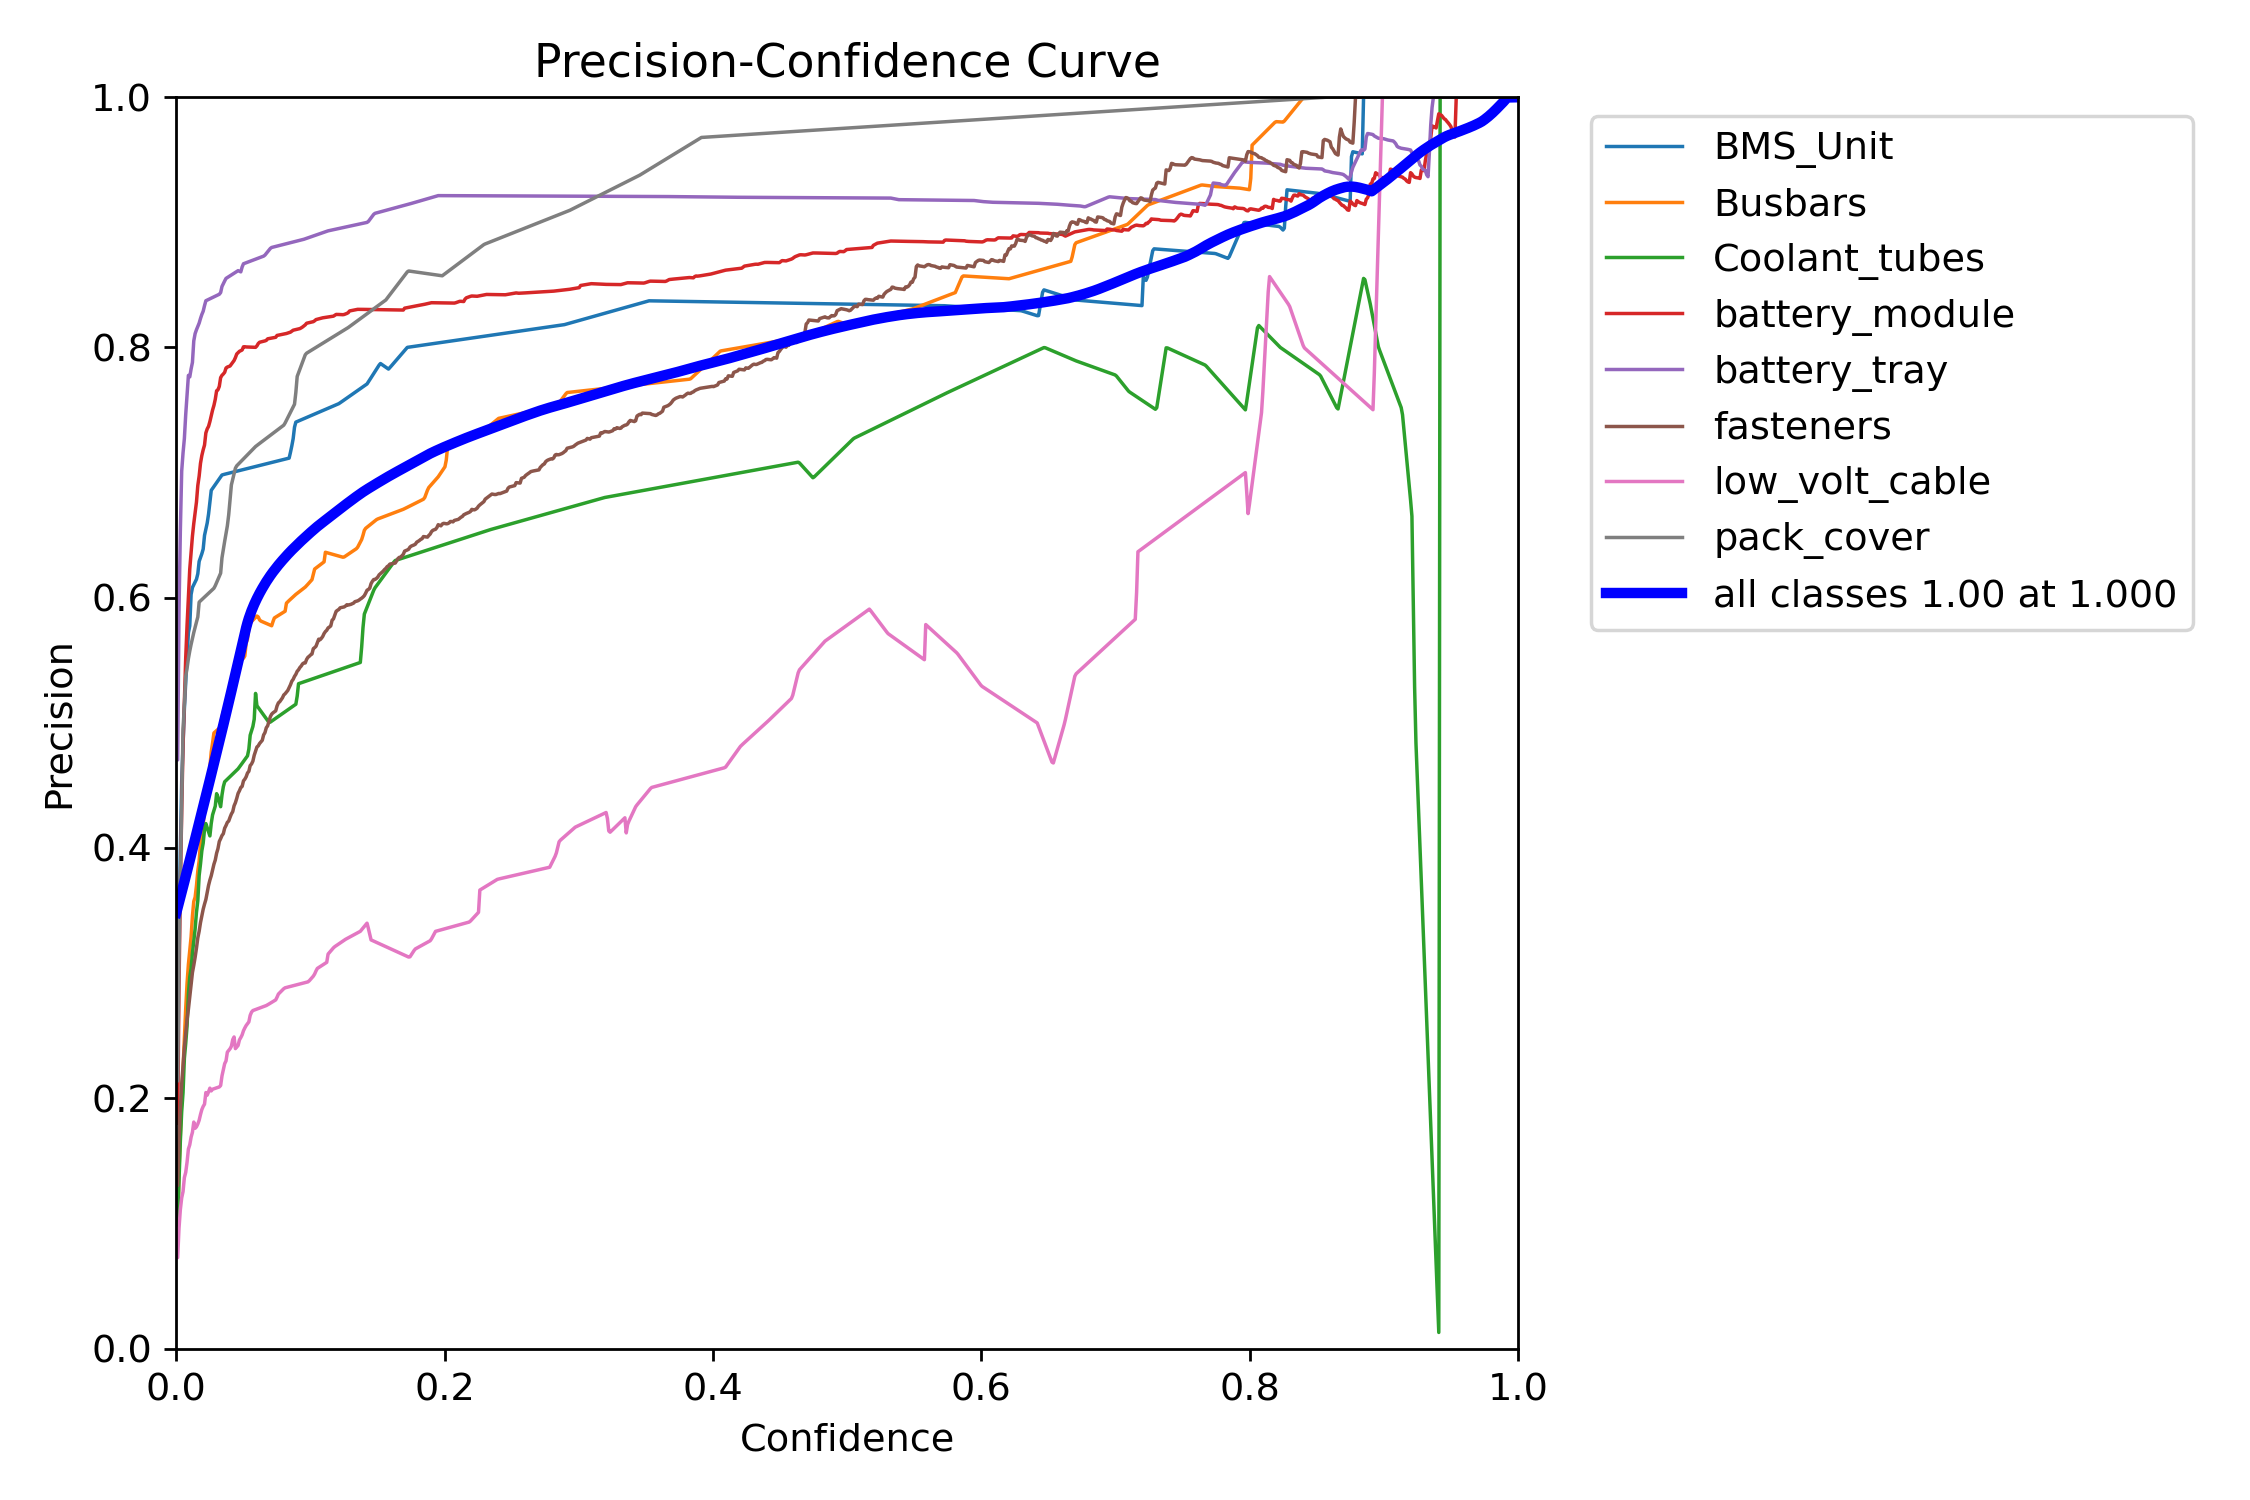

Showing: BoxR_curve.png


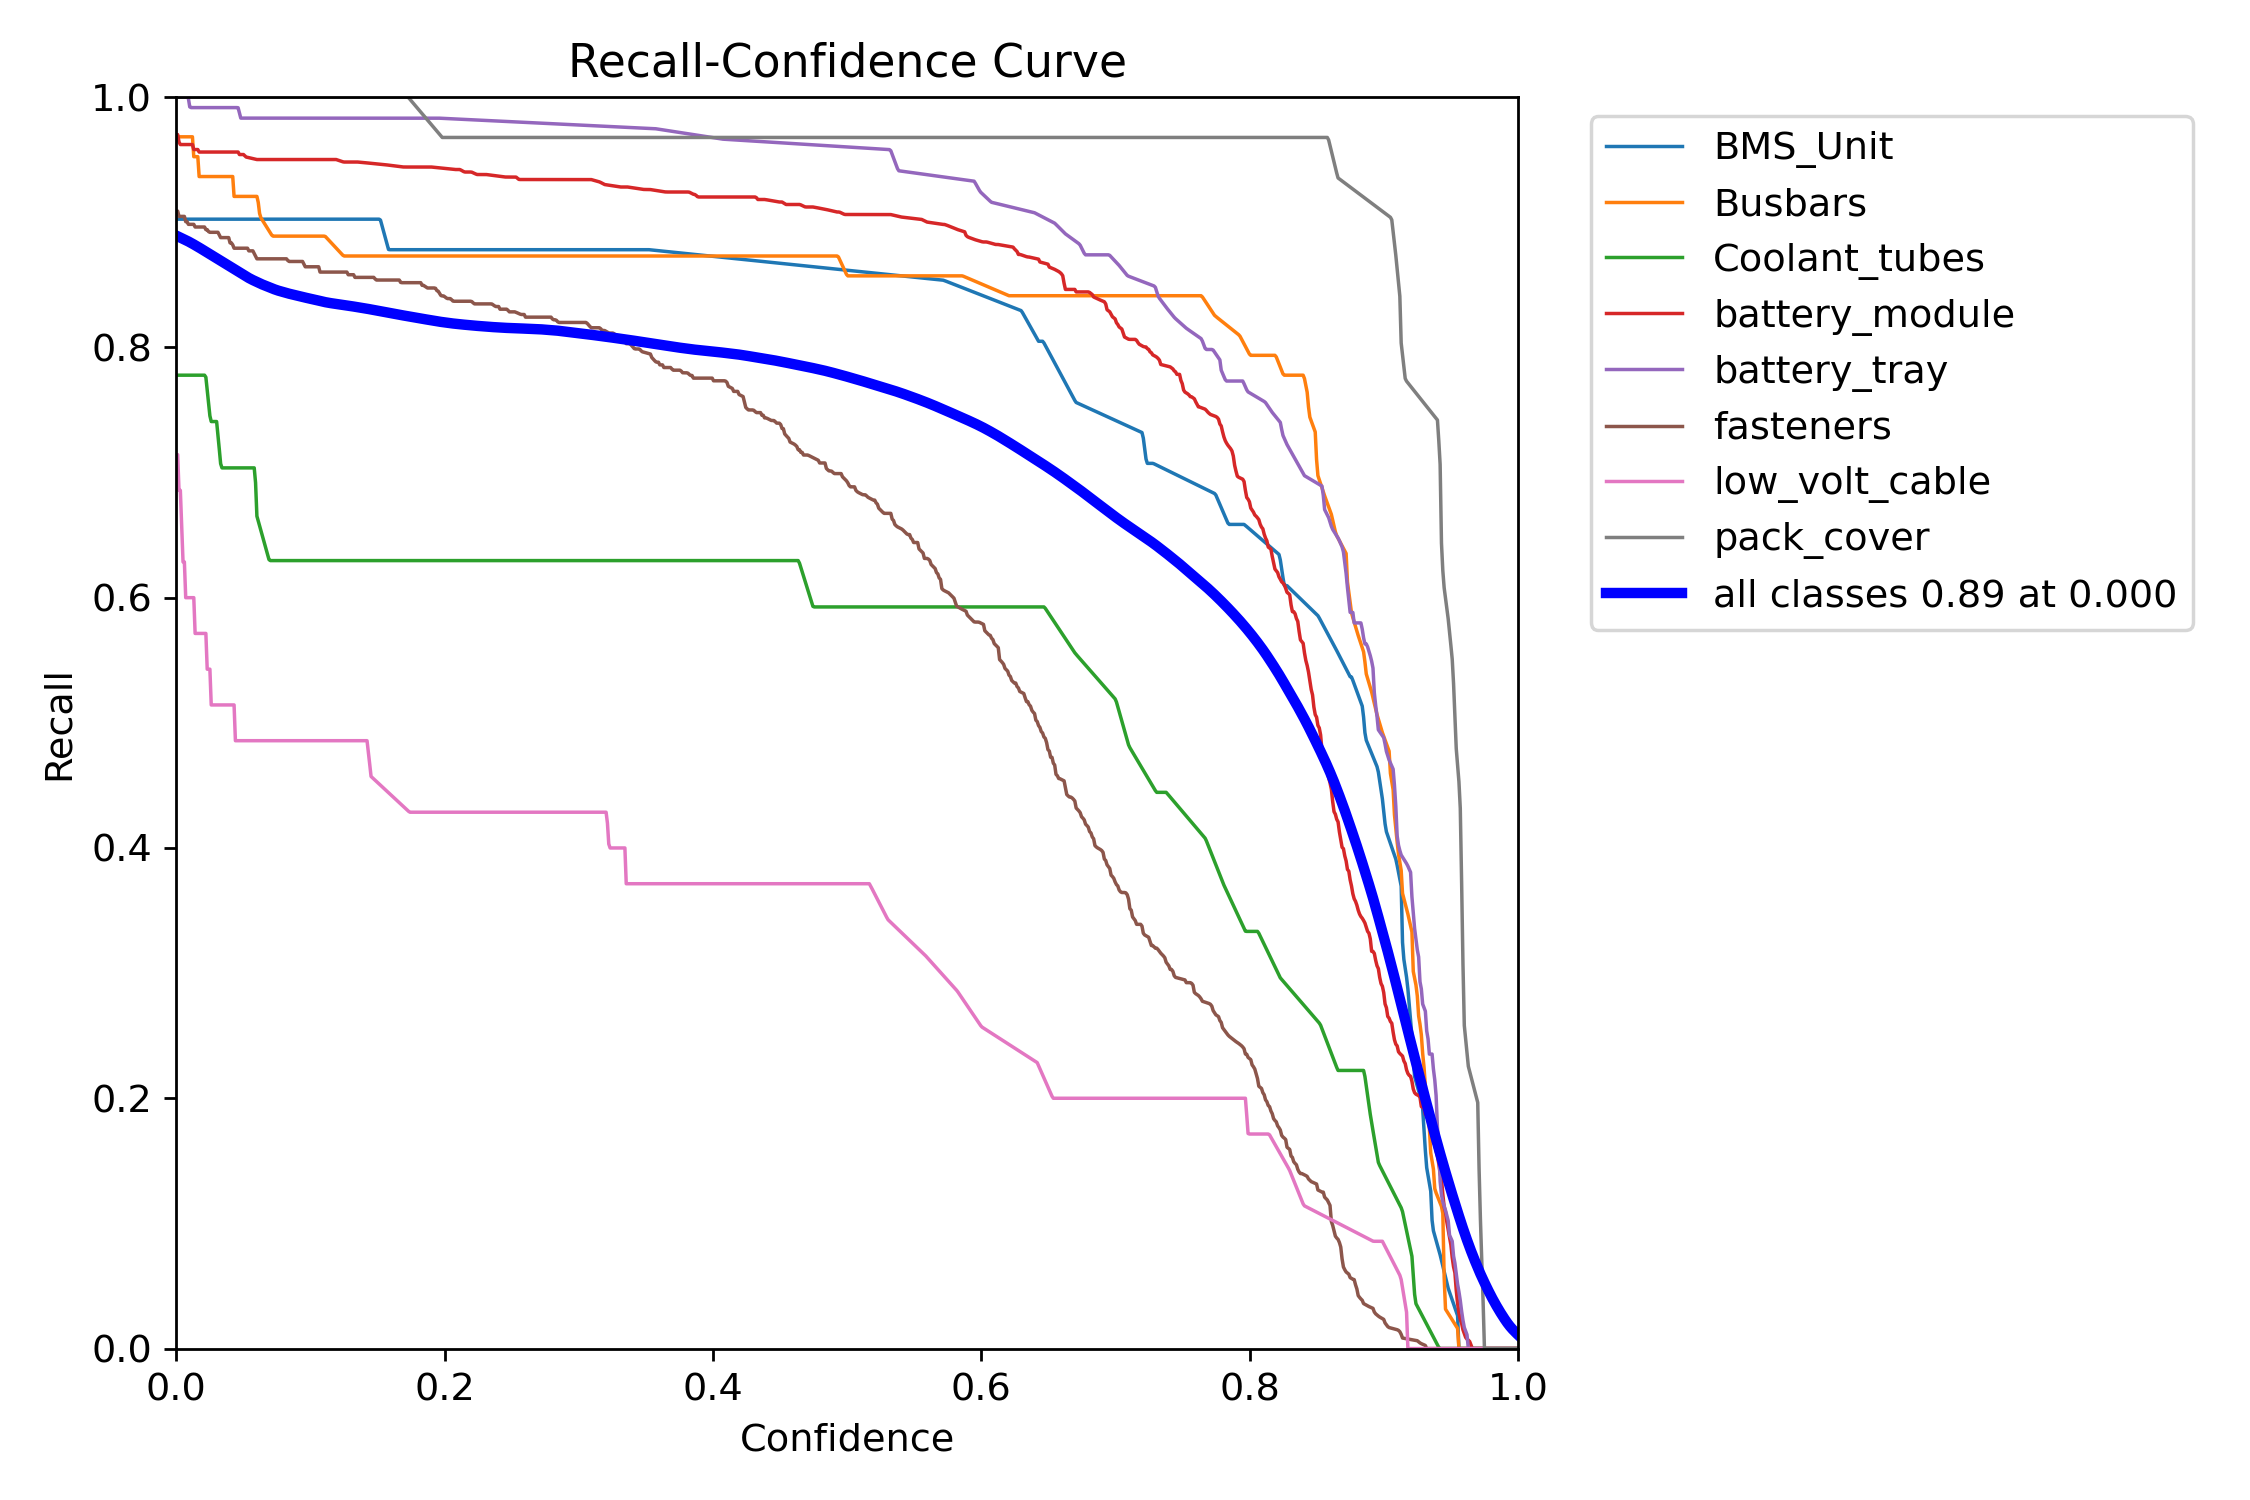


DISPLAYING CUSTOM MODEL PLOTS

 Custom Bicubic Upsample
Showing: results.png


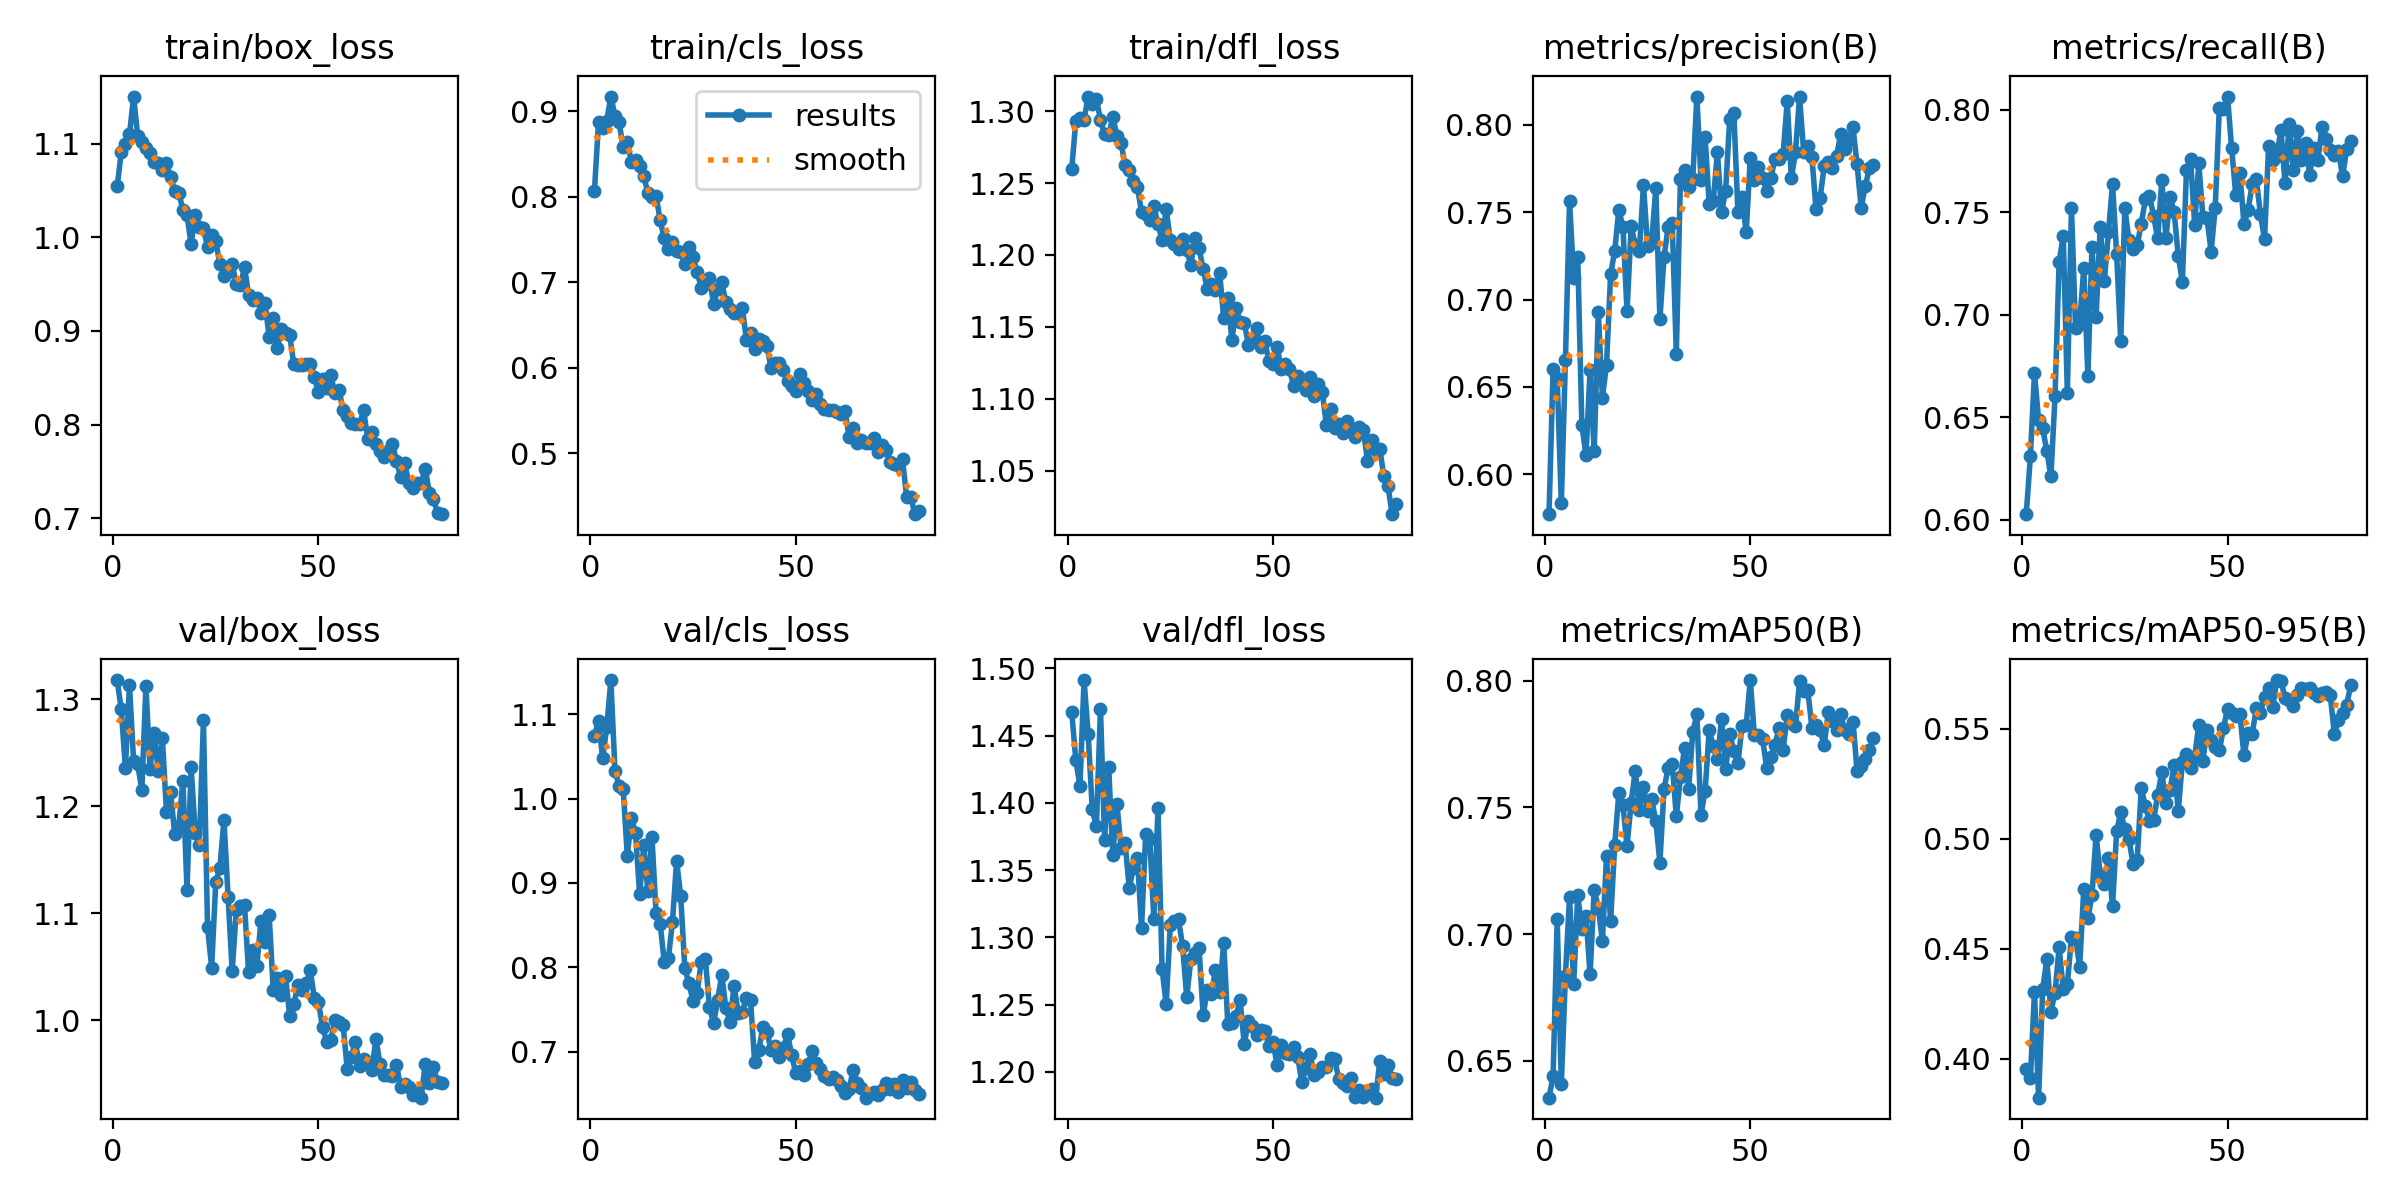

Showing: confusion_matrix.png


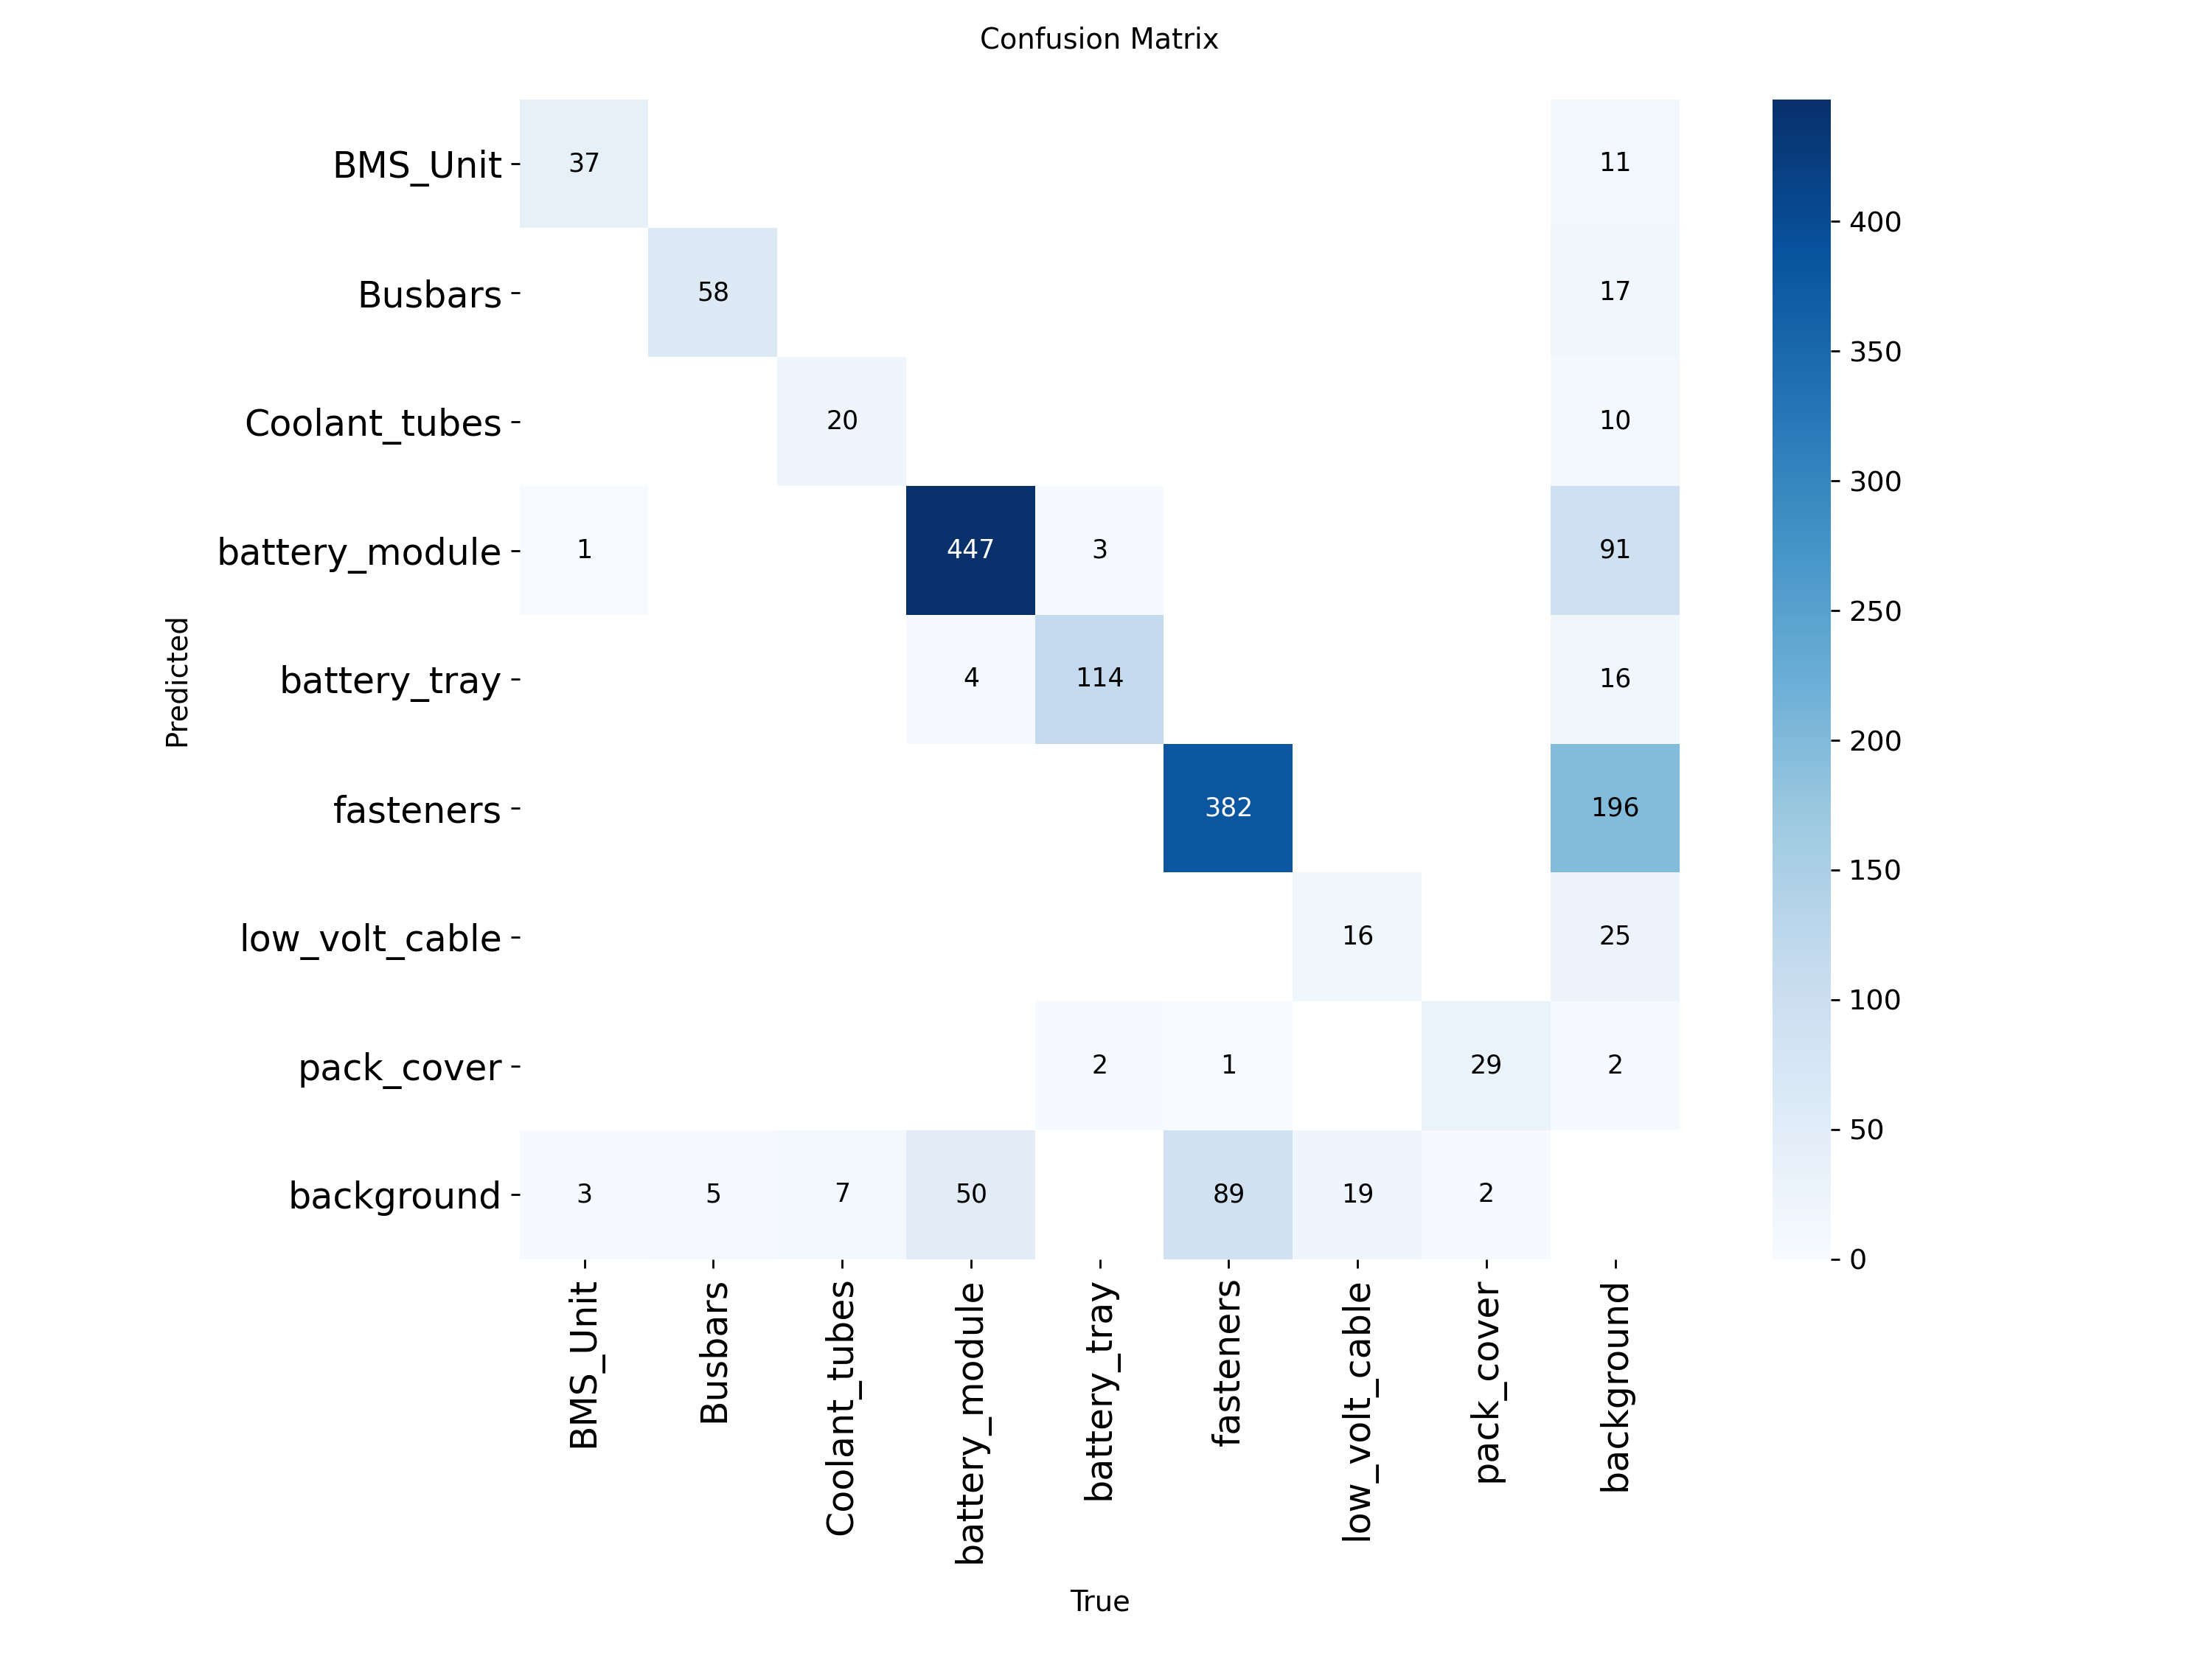

Showing: confusion_matrix_normalized.png


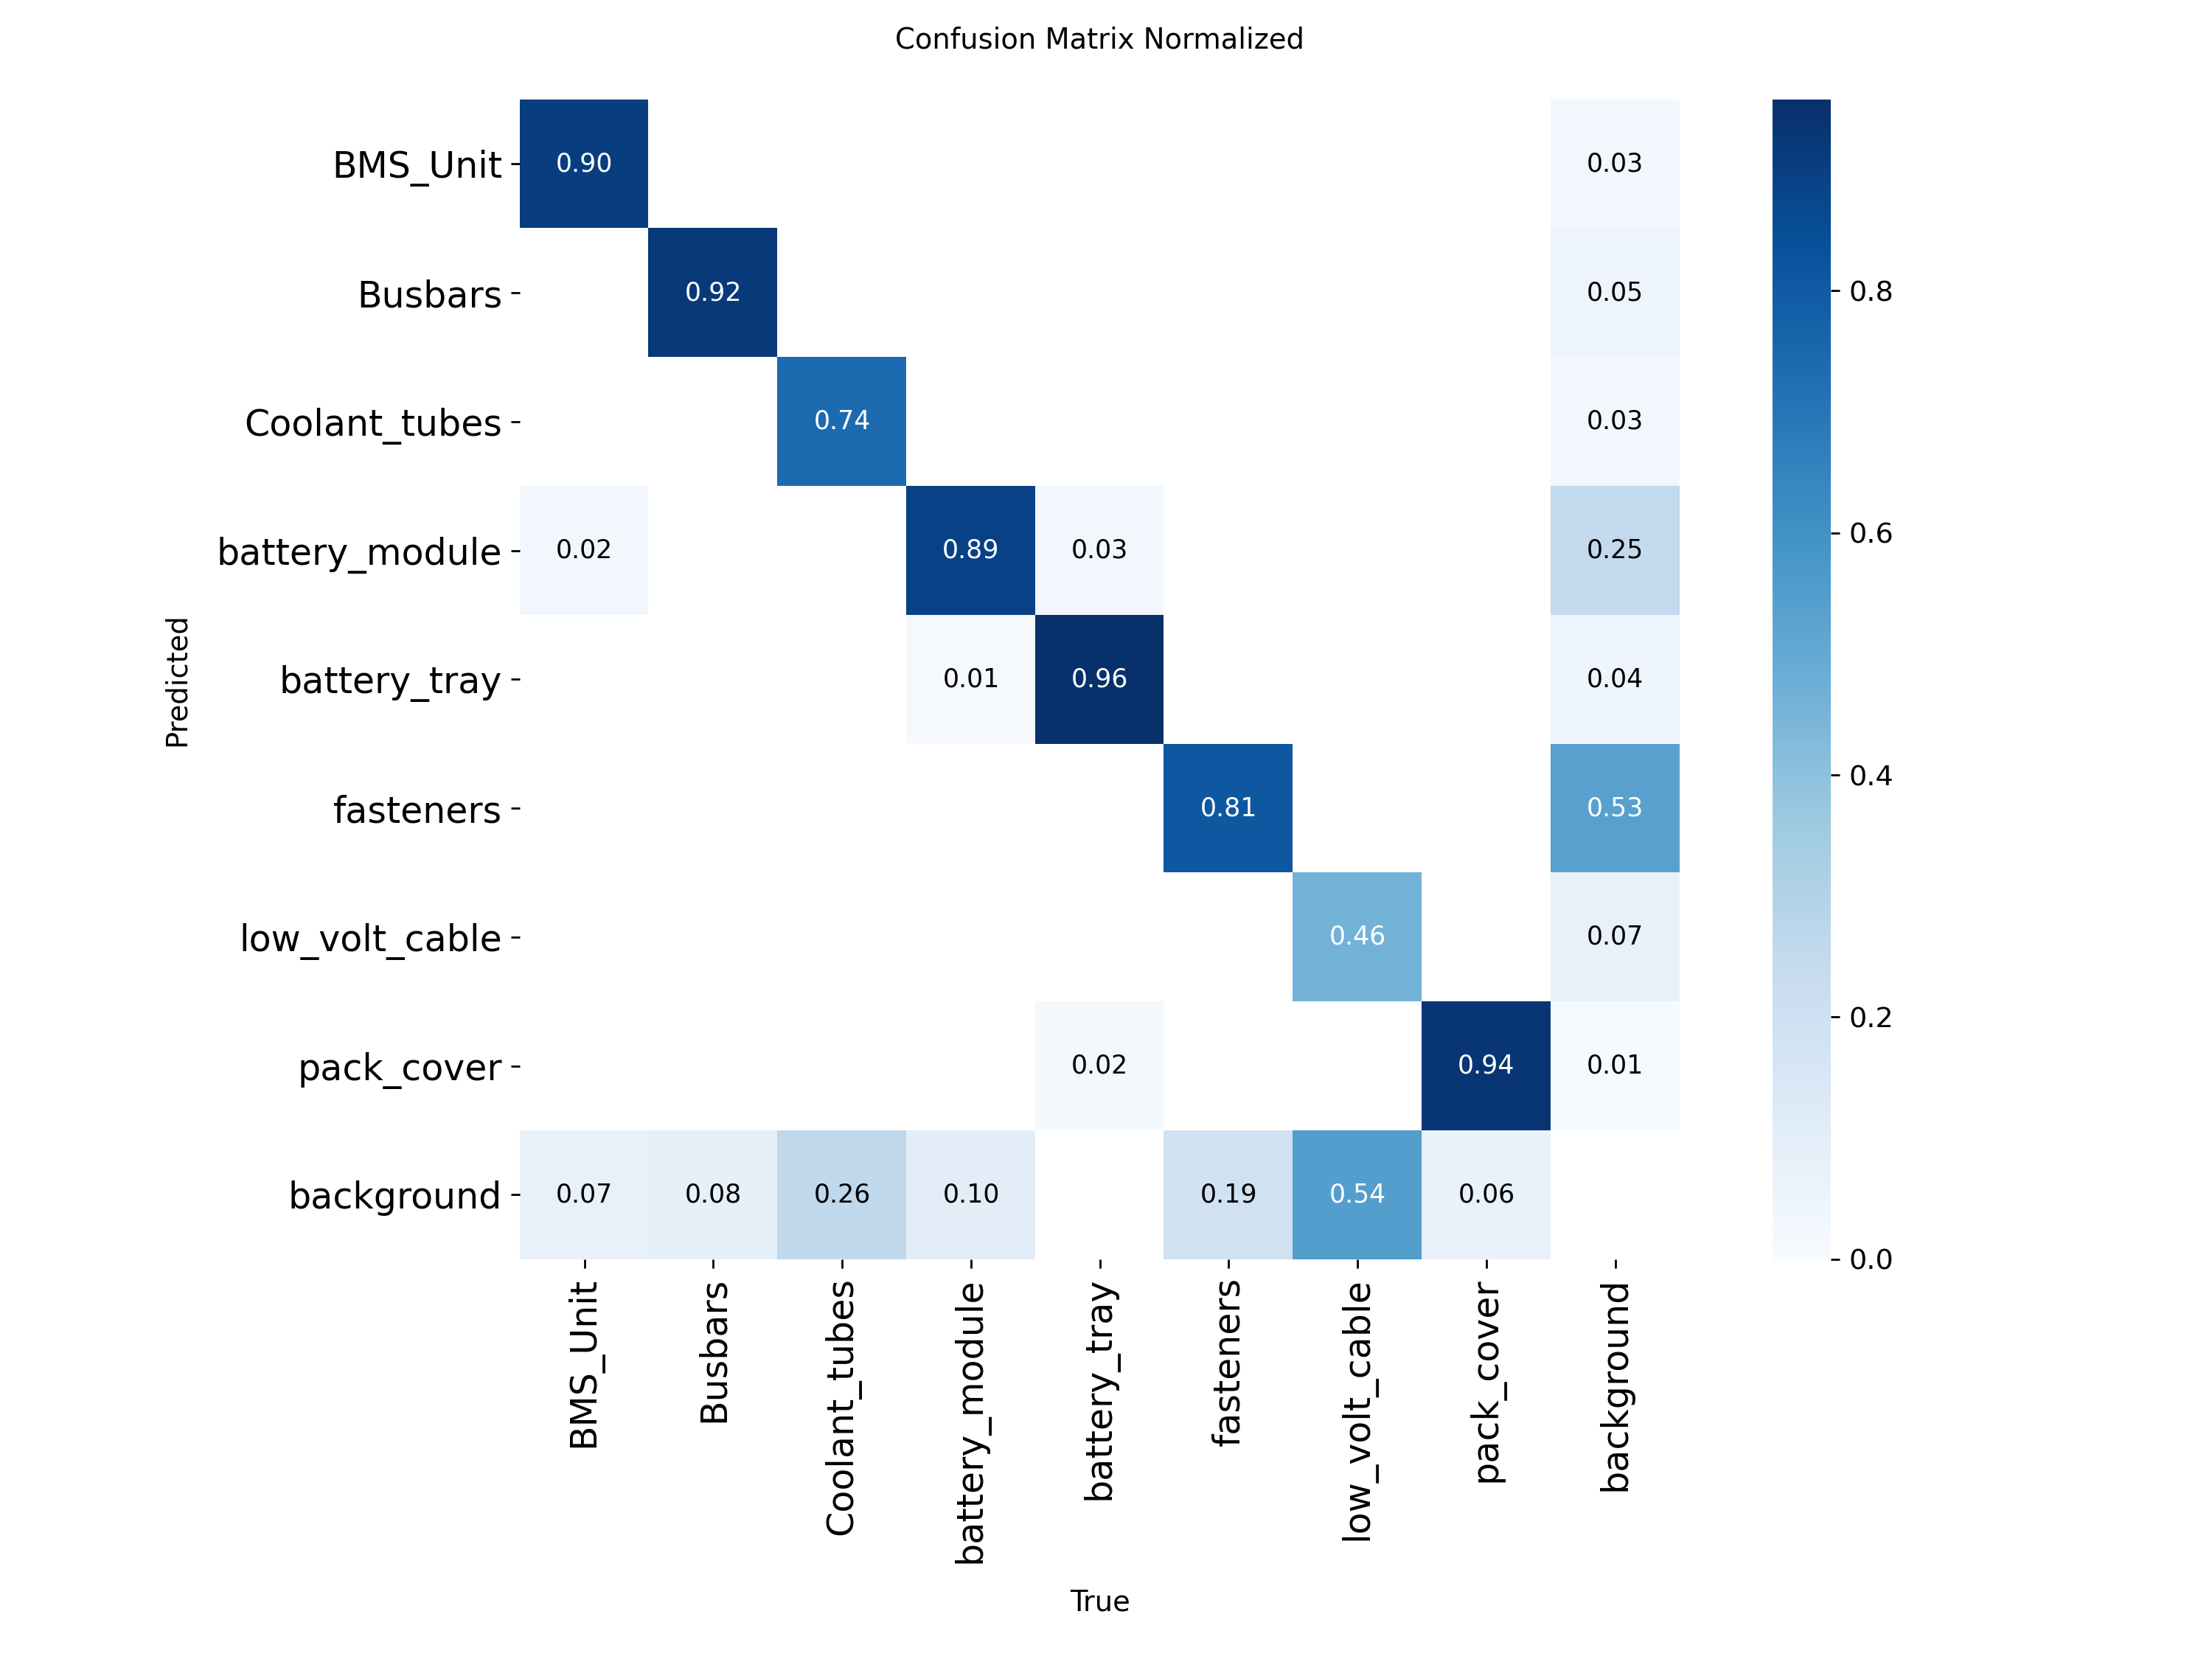

Showing: BoxPR_curve.png


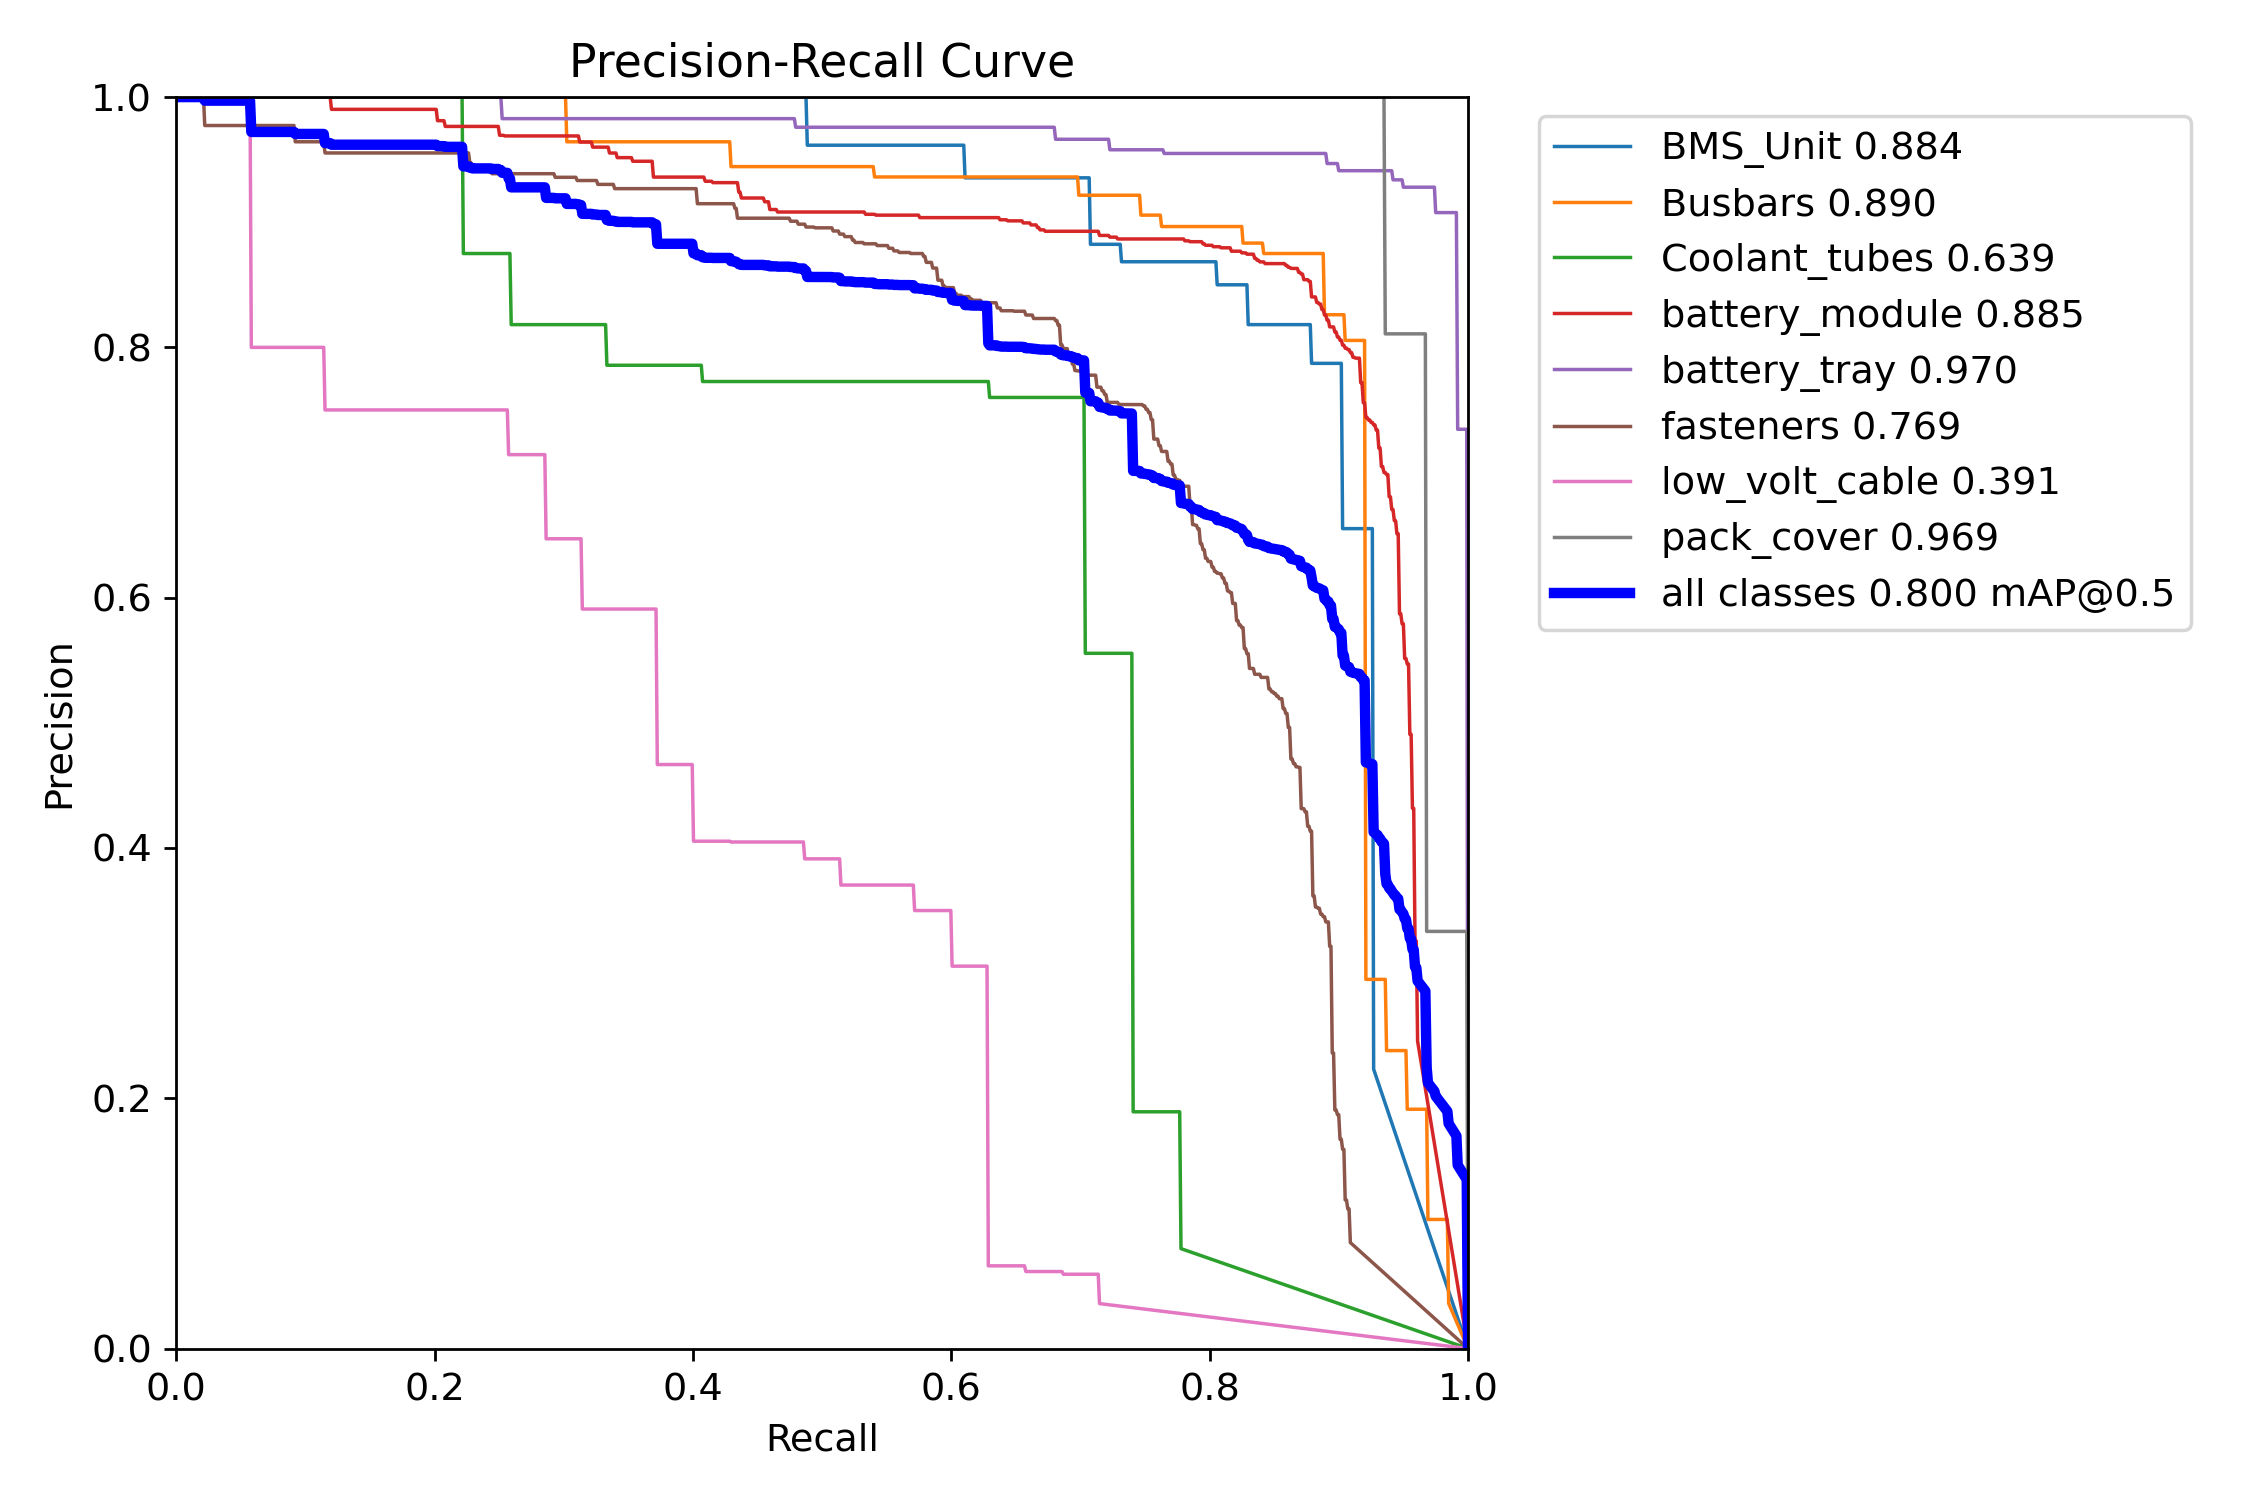

Showing: BoxF1_curve.png


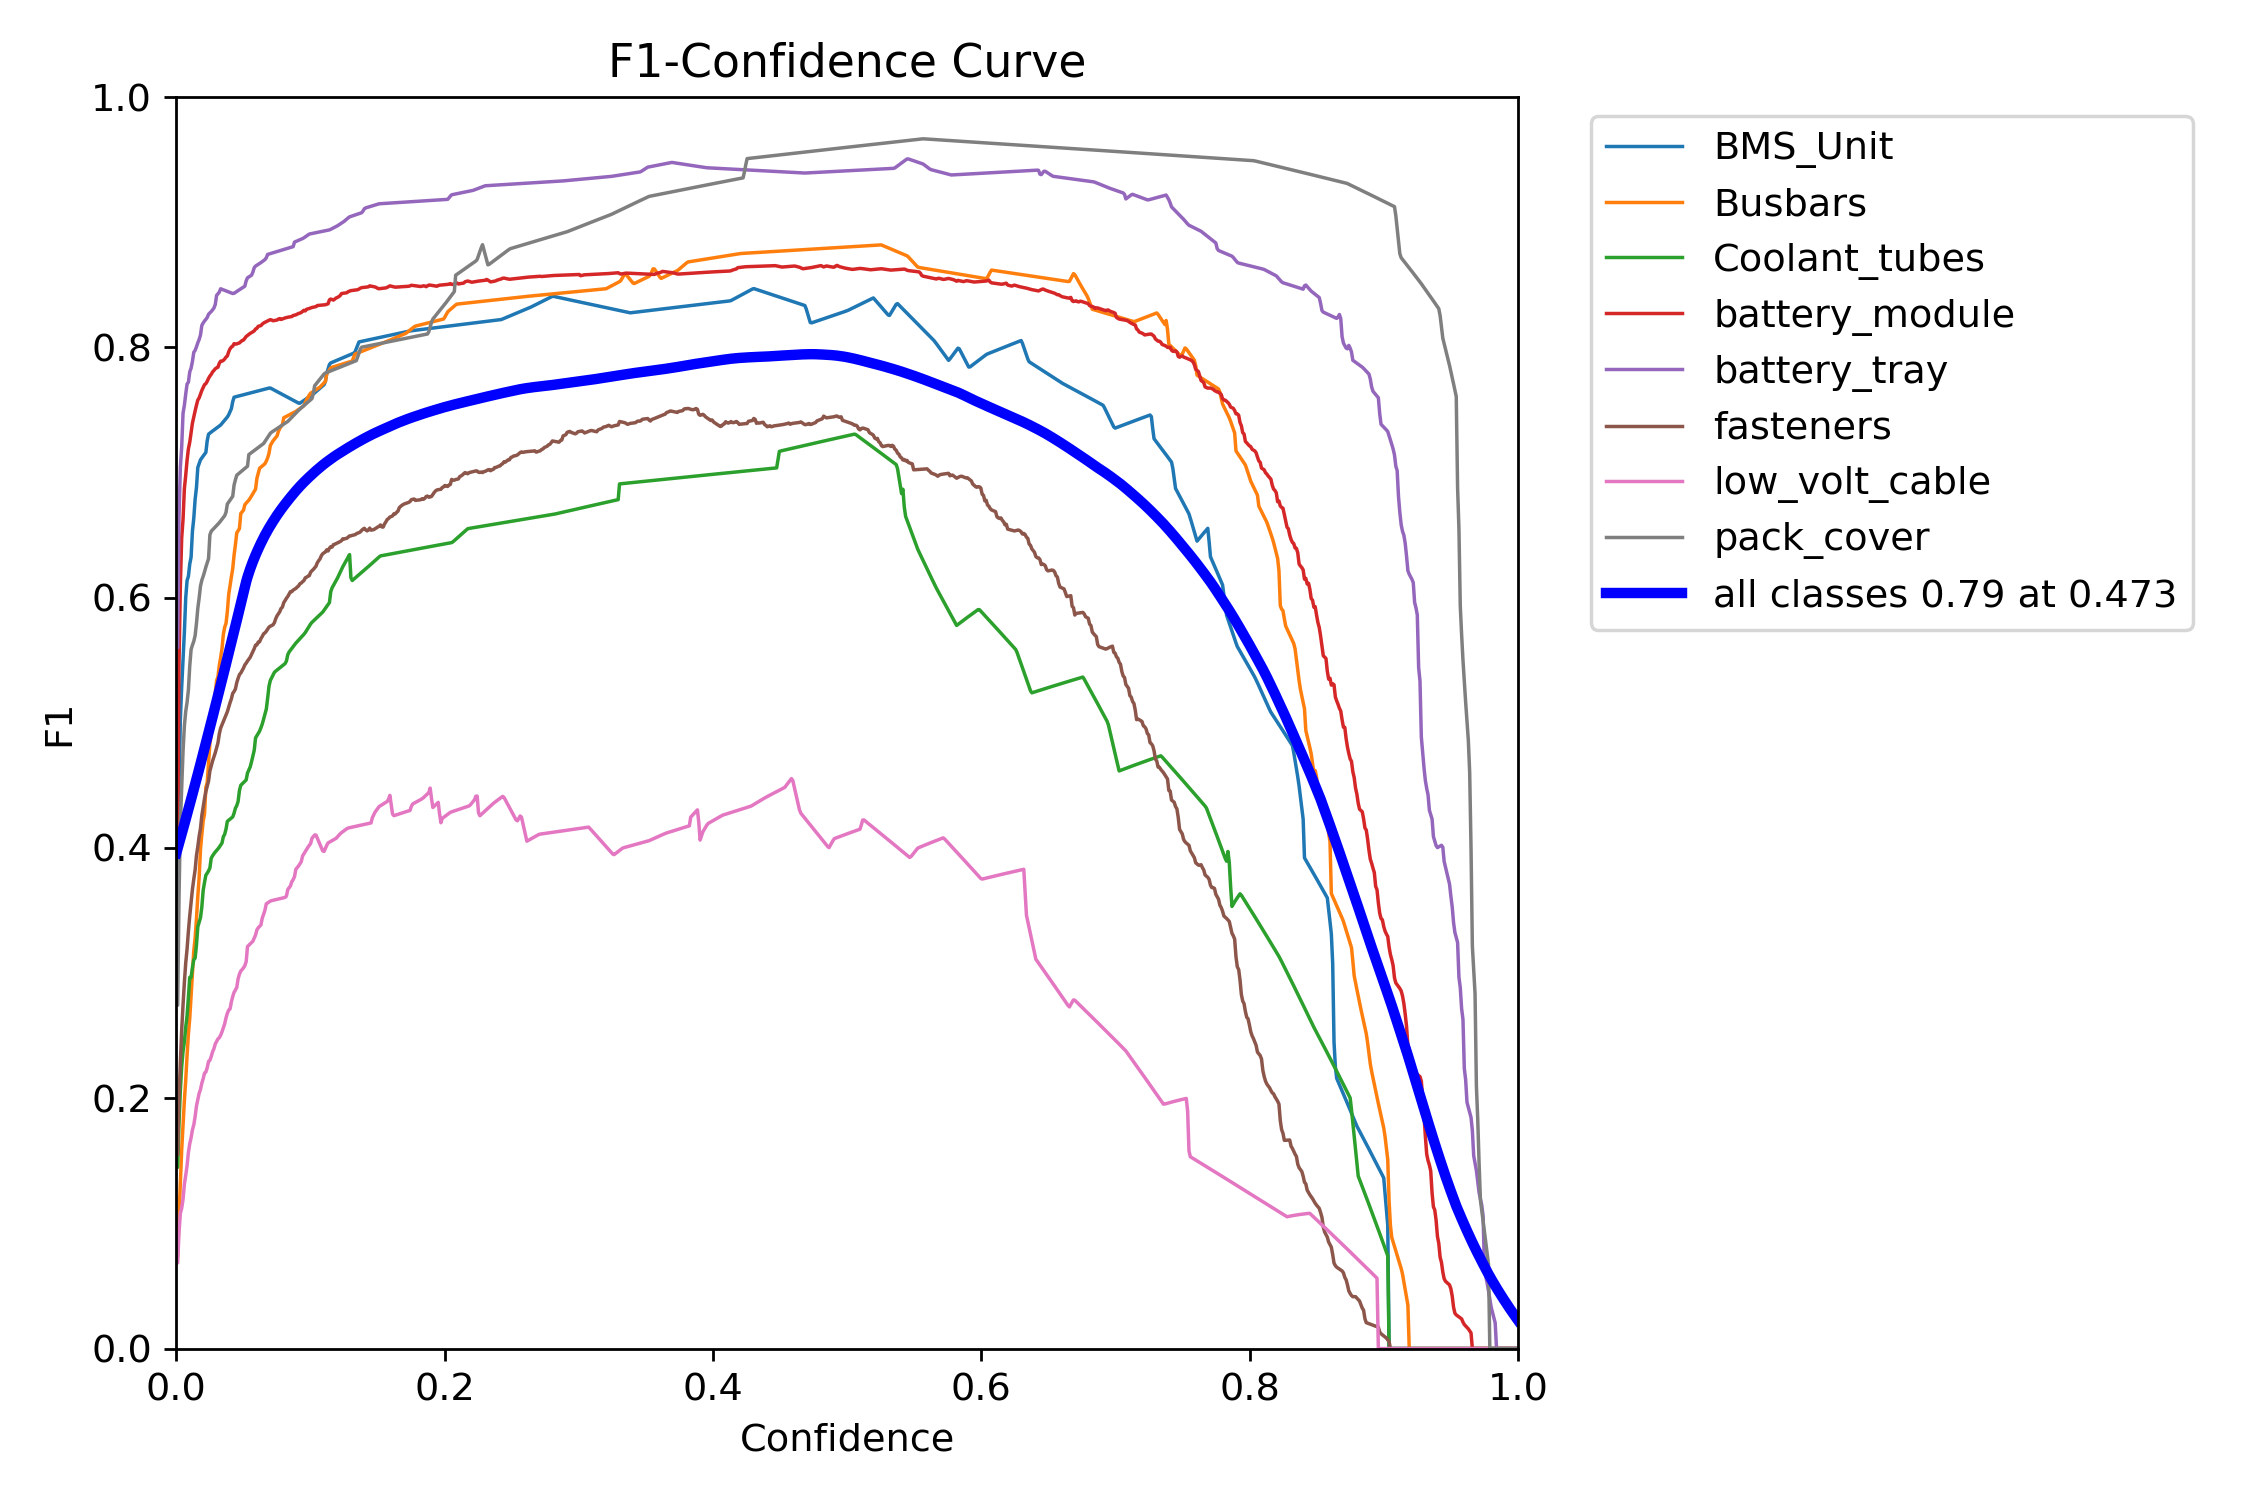

Showing: BoxP_curve.png


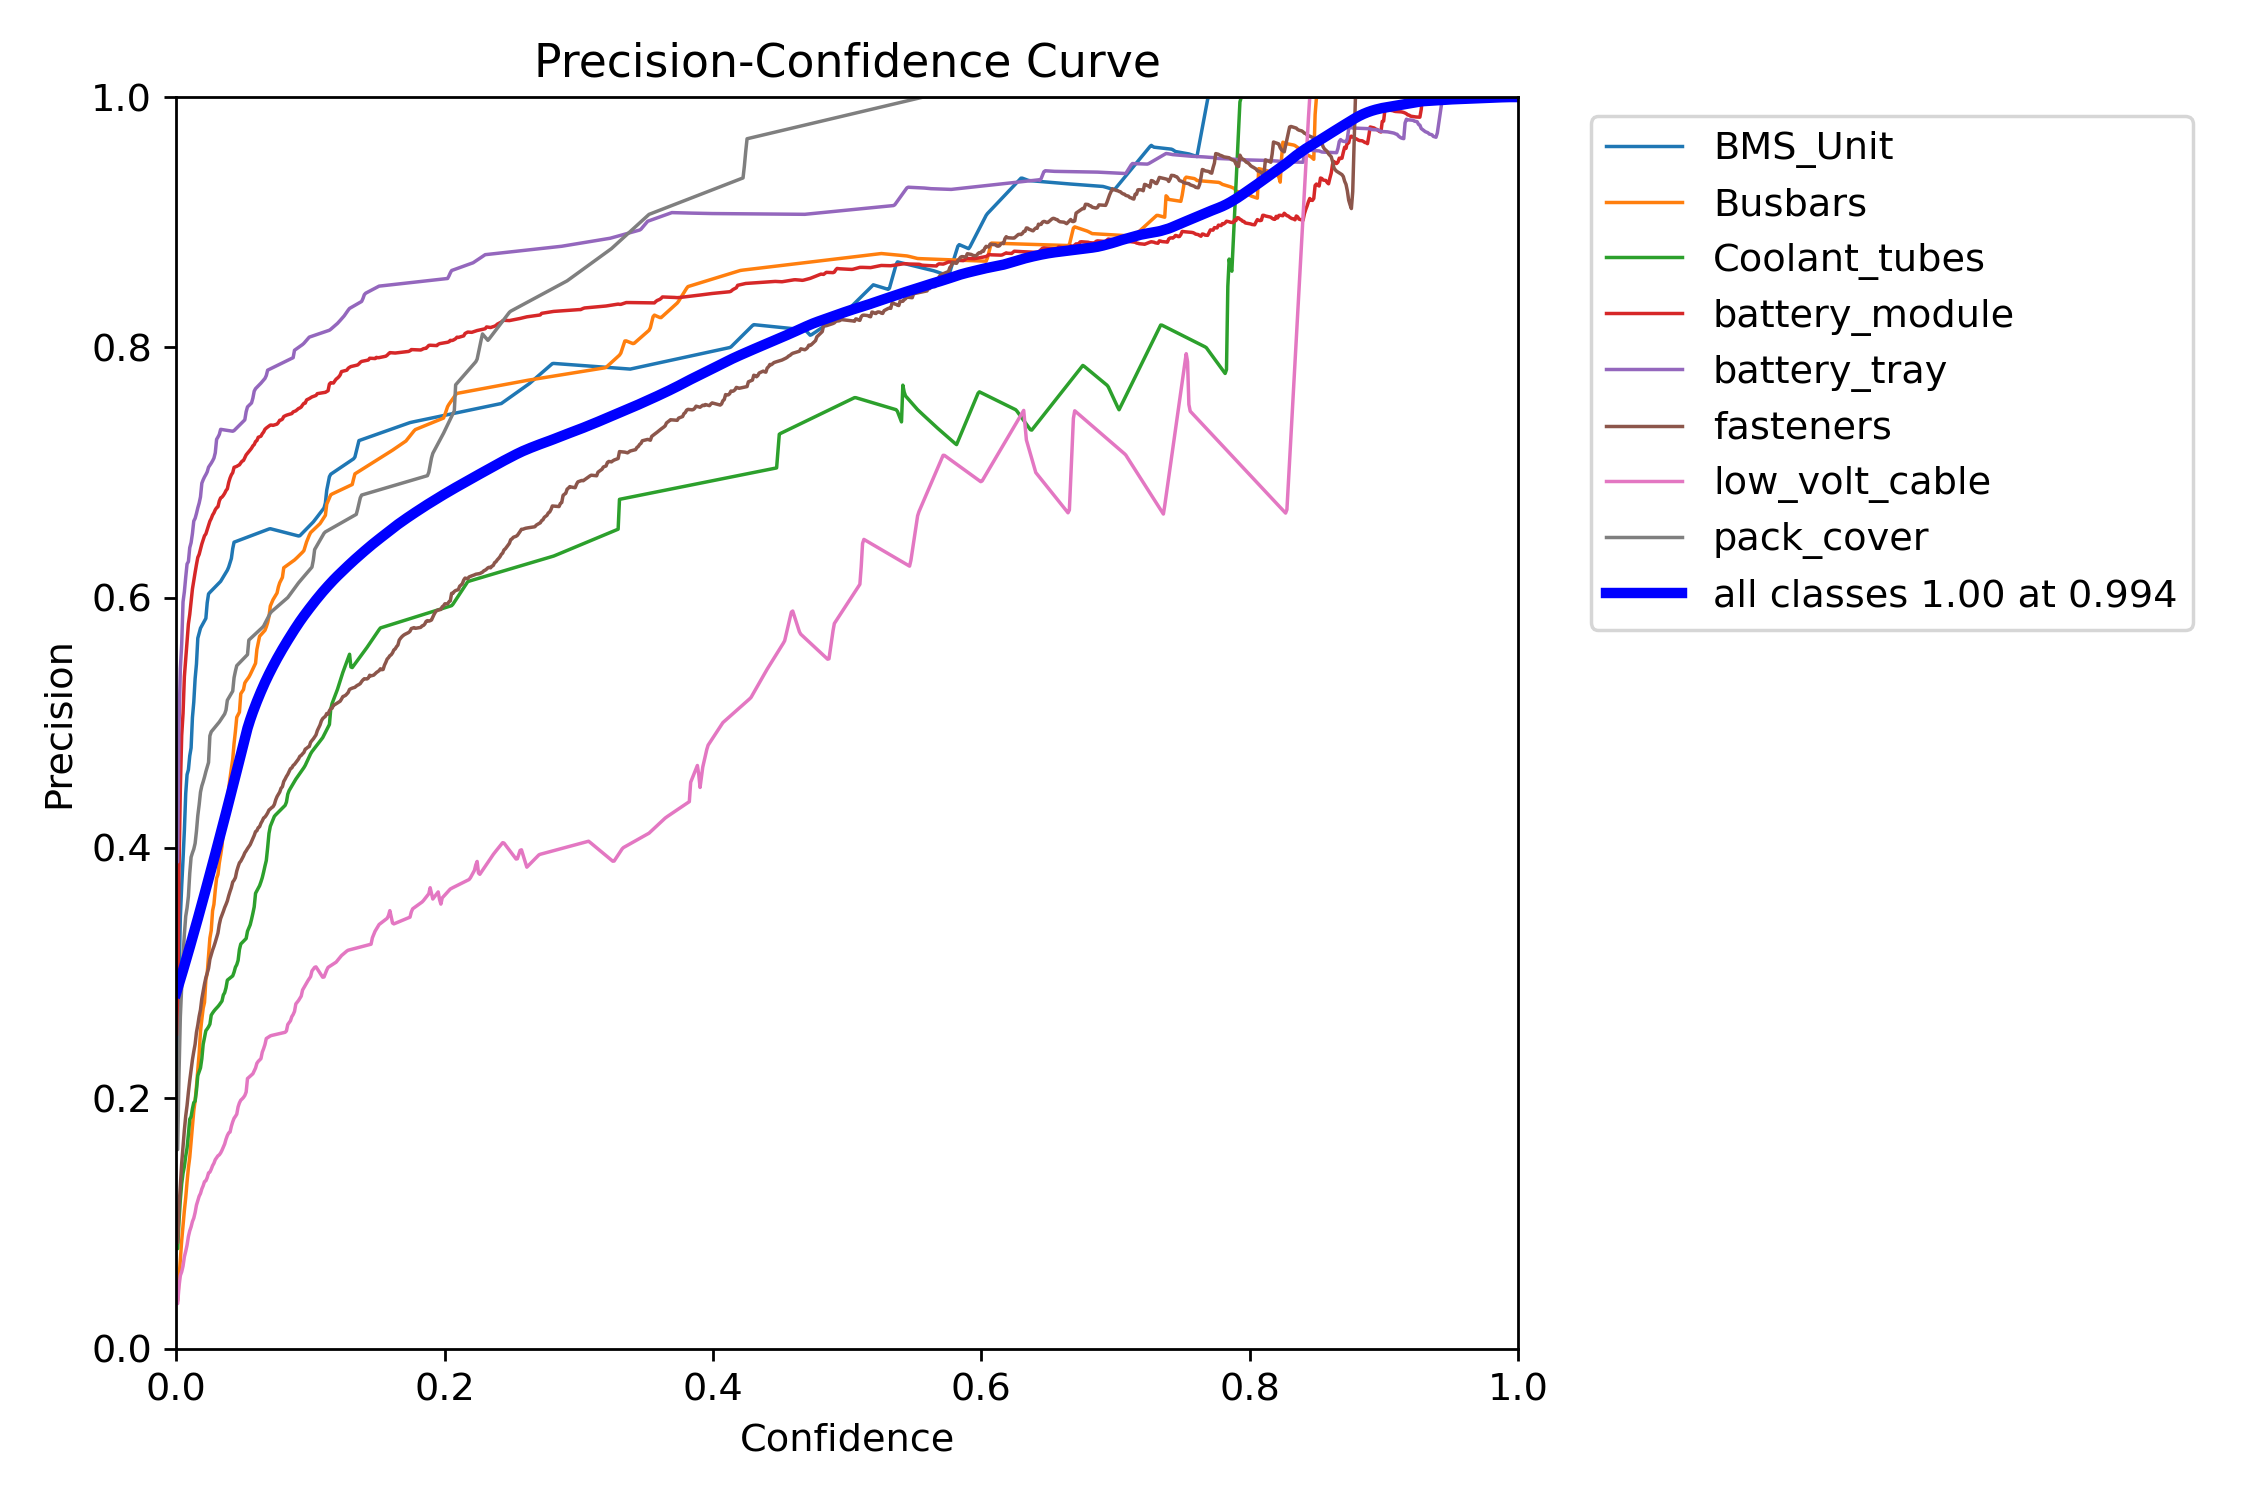

Showing: BoxR_curve.png


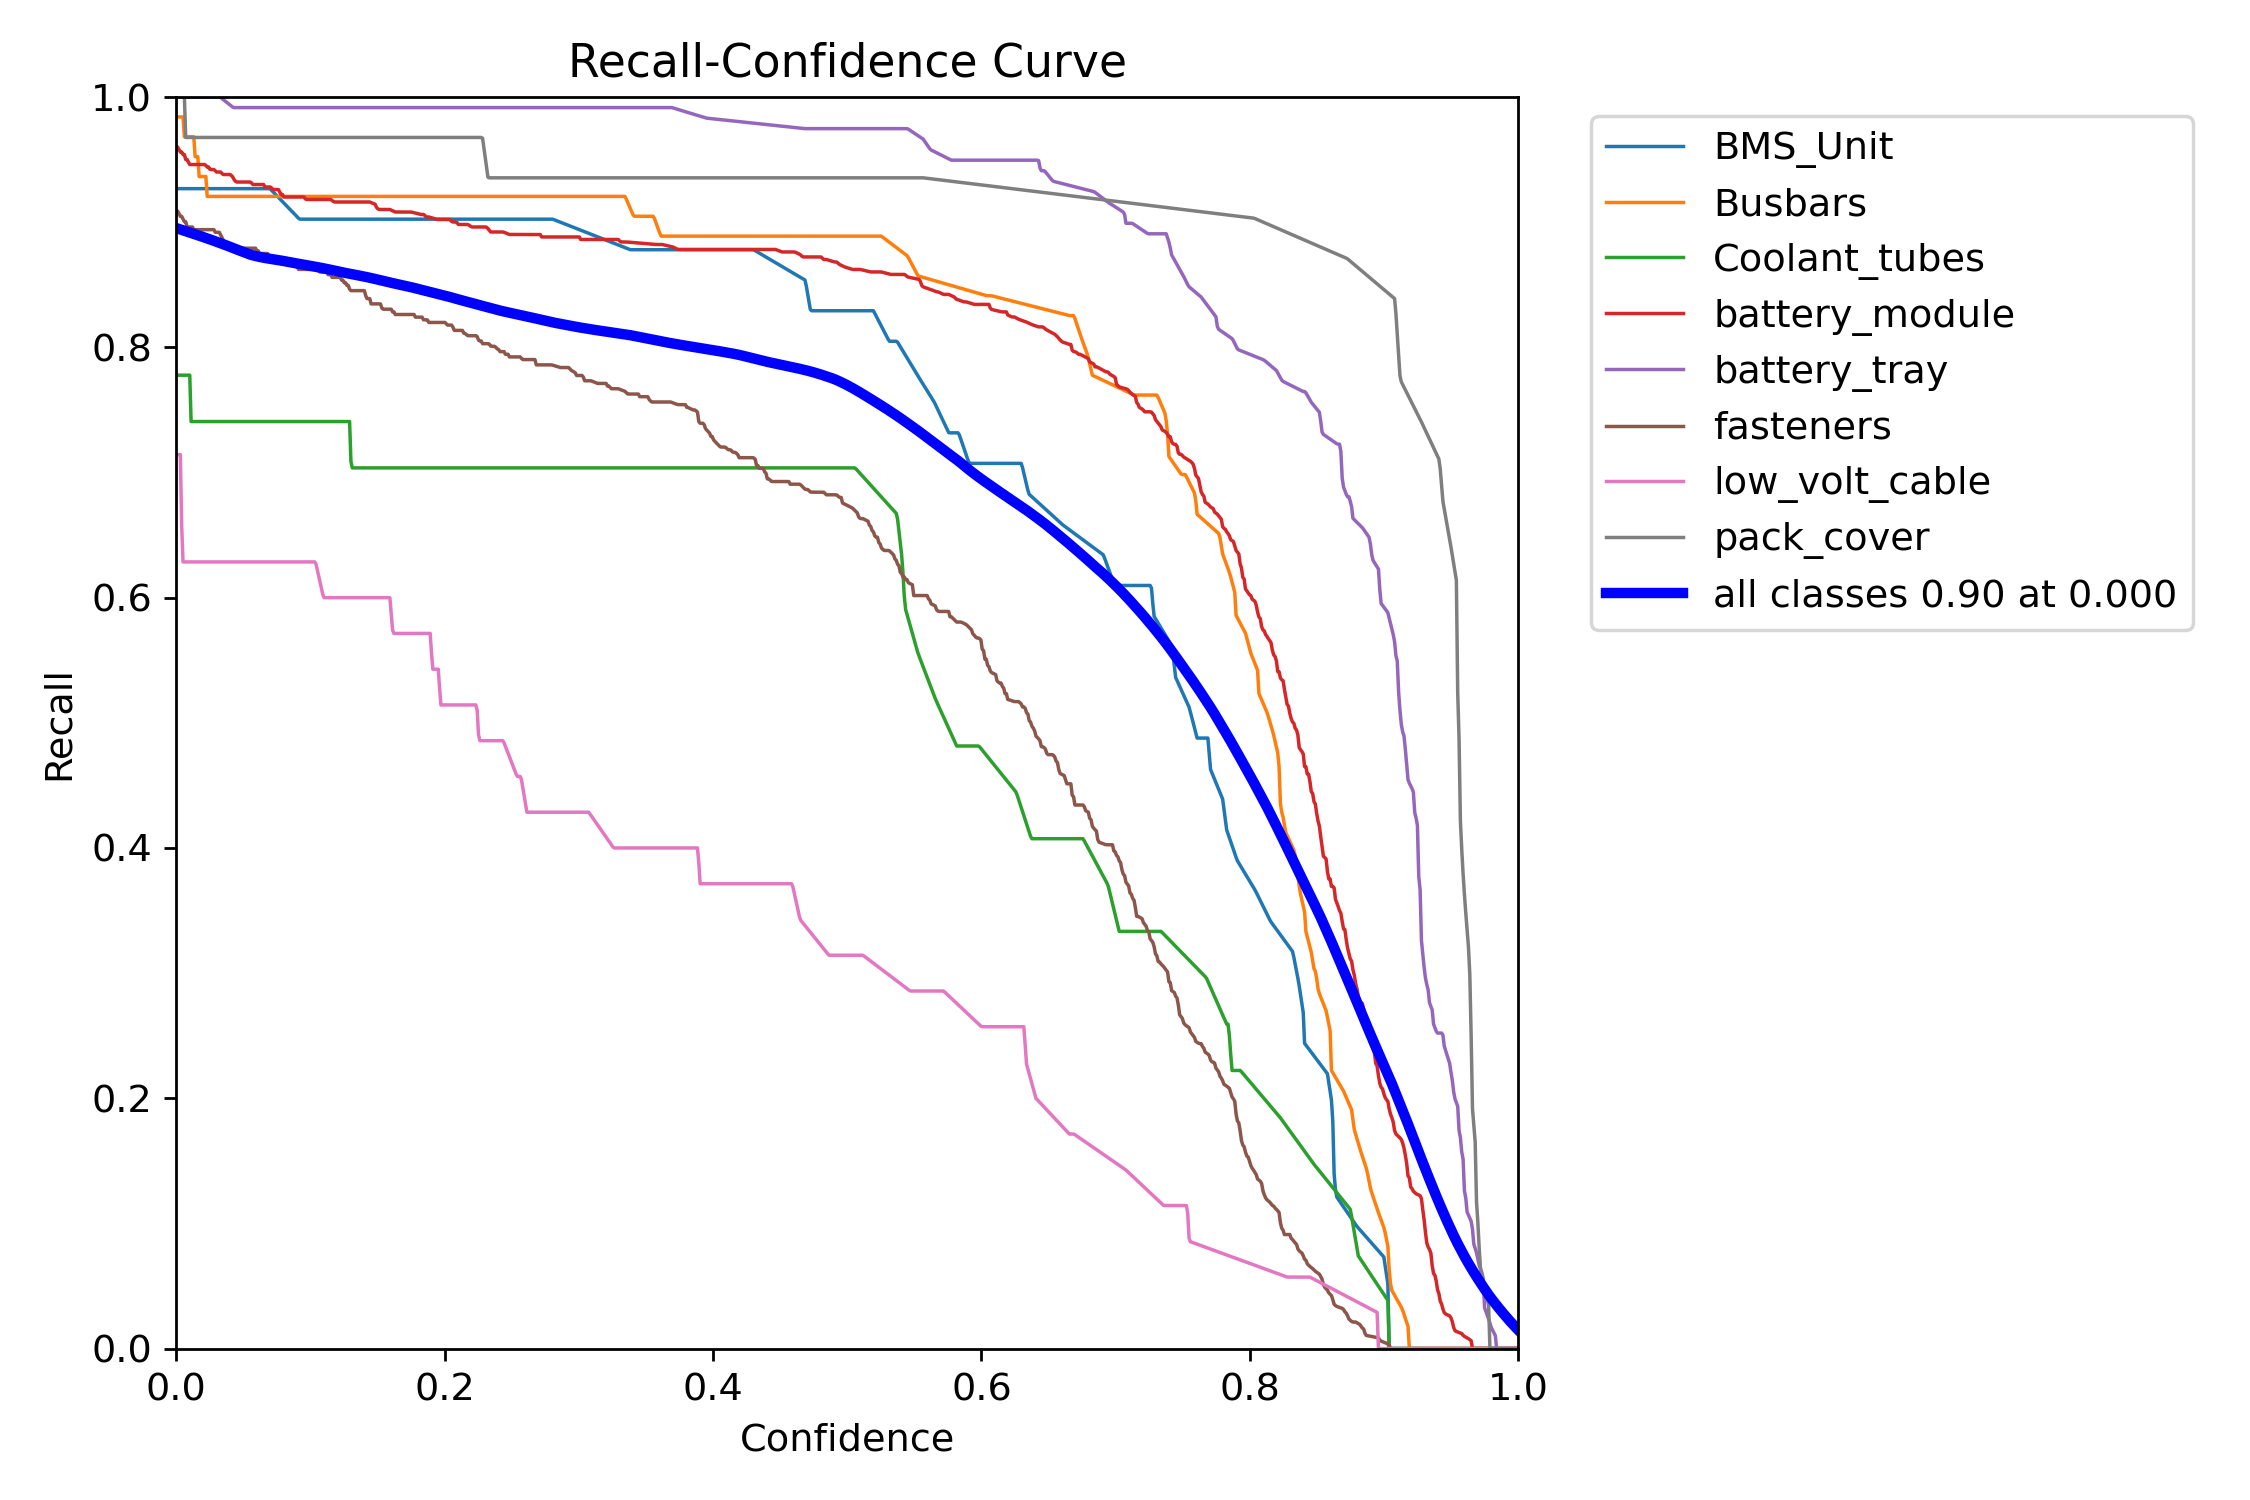

In [21]:
# VISUALISATIONS 

from IPython.display import Image, display
import os

def show_run_plots(run_dir, title):
    print(f"\n {title}")
    plot_files = [
        "results.png",
        "confusion_matrix.png",
        "confusion_matrix_normalized.png",
        "BoxPR_curve.png",
        "BoxF1_curve.png",
        "BoxP_curve.png",
        "BoxR_curve.png",
    ]

    for f in plot_files:
        p = os.path.join(run_dir, f)
        if os.path.exists(p):
            print(f"Showing: {f}")
            display(Image(filename=p))
        else:
            print(f"Missing: {f}")

# Paths)
print("\nDISPLAYING BASELINE PLOTS")
show_run_plots(base_dir, "Baseline YOLOv9m")

print("\nDISPLAYING CUSTOM MODEL PLOTS")
show_run_plots(cust_dir, "Custom Bicubic Upsample")


In [22]:
import inspect
from ultralytics.utils import metrics

src = inspect.getsource(metrics.bbox_iou)
print("Has SIoU?", "SIoU" in src)
print(src[:1200])  


Has SIoU? True
def bbox_iou(
    box1: torch.Tensor,
    box2: torch.Tensor,
    xywh: bool = True,
    GIoU: bool = False,
    DIoU: bool = False,
    CIoU: bool = False,
    SIoU: bool = False,
    eps: float = 1e-7,
) -> torch.Tensor:
    """Calculate the Intersection over Union (IoU) between bounding boxes.

    This function supports various shapes for `box1` and `box2` as long as the last dimension is 4. For instance, you
    may pass tensors shaped like (4,), (N, 4), (B, N, 4), or (B, N, 1, 4). Internally, the code will split the last
    dimension into (x, y, w, h) if `xywh=True`, or (x1, y1, x2, y2) if `xywh=False`.

    Args:
        box1 (torch.Tensor): A tensor representing one or more bounding boxes, with the last dimension being 4.
        box2 (torch.Tensor): A tensor representing one or more bounding boxes, with the last dimension being 4.
        xywh (bool, optional): If True, input boxes are in (x, y, w, h) format. If False, input boxes are in (x1, y1,
            x2

In [23]:
import shutil

src = "/users/2/240388203/anaconda3/envs/evdisassembly/lib/python3.10/site-packages/ultralytics/utils/loss.py"
dst = src + ".bak"

shutil.copyfile(src, dst)
print("Backed up to:", dst)


Backed up to: /users/2/240388203/anaconda3/envs/evdisassembly/lib/python3.10/site-packages/ultralytics/utils/loss.py.bak


In [24]:
import inspect
from ultralytics.utils import metrics

print(inspect.getfile(metrics))


/users/2/240388203/anaconda3/envs/evdisassembly/lib/python3.10/site-packages/ultralytics/utils/metrics.py
